<a href="https://colab.research.google.com/github/SergeiVKalinin/RL_and_Rewards/blob/main/RL_EELS/0_EELS_Size_Blur.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Adaptive image–spectroscopy experiments
## Reproducing the RF, DCNN and DKL manuscript

This notebook follows the paper: data and observation model → predictor calibration → maturity and references → sequential decisions → results → the alternative acquisition law.

**`MODE="paper"` performs new fits and campaigns.** It contains no dataset, saved predictions, trained models, or archived result tables. The NPZ stays external. The numerical protocol uses **B = 150**, including initialization; the proposed B = 250 extension is not a reported result.

Candidate locations are selected by predicted response or uncertainty; the actor selects IMAGE/SPECTRUM and the imaging settings. Policy actions remain stochastic. No replay, drift, image-only training, or hidden-label reward is introduced.

A complete run is computationally substantial and checkpoints each fit/campaign. `MODE="check"` tests every regressor on real data without claiming to reproduce the full study.

In [ ]:
from pathlib import Path
import os, sys, json

MODE = "paper"                 # "paper": full manuscript; "check": implementation tests only
WORKERS = 3                    # CPU worker processes; one numerical thread per fit
OUTPUT = Path("eels_paper_run").resolve()
SELECTION = "paper"            # freeze the manuscript's selected profile/configuration identities
DATA_SOURCE = "npz"            # "npz" or "original" (584 MB NPY → verified compact NPZ)
DATA_URL = ""                  # optional public HTTPS NPZ URL; none has yet been verified
LOCAL_DATA = ""                # optional path to EELS_Manuscript_Data.npz
TRUST_ORIGINAL_NPY = False     # required only for the known pickled original source

if MODE not in {"paper", "check"}: raise ValueError(MODE)
if SELECTION != "paper": raise ValueError("Use the manuscript selections for this reproducer.")
CODE = Path("eels_code").resolve()
CODE.mkdir(exist_ok=True)
for key in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[key] = "1"
os.environ.setdefault("MPLBACKEND", "Agg")


'module://matplotlib_inline.backend_inline'

### Software
The recorded numerical environment used Python 3.13, NumPy 2.3.5, SciPy 1.17.0, scikit-learn 1.8.0 and CPU PyTorch 2.10.0. The notebook records installed versions. Fresh neural fits and timings need not be bitwise identical across CPUs or library versions. Hardware-dependent profile recommendations are recorded separately from the frozen manuscript selections.

In [ ]:
import importlib.util, subprocess, importlib.metadata
packages = {"numpy":"numpy", "scipy":"scipy", "pandas":"pandas", "sklearn":"scikit-learn",
            "torch":"torch", "matplotlib":"matplotlib", "PIL":"Pillow", "joblib":"joblib",
            "threadpoolctl":"threadpoolctl"}
if DATA_SOURCE == "original" or "drive.google.com" in DATA_URL:
    packages["gdown"] = "gdown"
missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
import numpy as np
import pandas as pd
from IPython.display import display, Image, FileLink
print({p:importlib.metadata.version(p) for p in ("numpy","scipy","pandas","scikit-learn","torch")})

{'numpy': '2.4.6', 'scipy': '1.16.3', 'pandas': '2.2.3', 'scikit-learn': '1.6.1', 'torch': '2.14.1+cpu'}


## 1. Experimental data and dynamic observations
Use the **separate `EELS_Manuscript_Data.npz` download** beside this notebook, a local path, or a real HTTPS NPZ URL. In Colab the missing-file fallback opens an upload dialog. No public URL for this derived NPZ has yet been established; the notebook does not invent one.

The alternative `DATA_SOURCE="original"` downloads the original Drive archive and rebuilds the same arrays. This needs `TRUST_ORIGINAL_NPY=True` because that source is a pickled dictionary. Every loading route verifies all ten arrays against their manuscript hashes; no synthetic fallback is allowed.

The stored band area is the scalar target. The 100-channel spectra are retained for illustration, not reintegrated to replace that target. Unavailable spectra remain unavailable.

In [ ]:
%%writefile eels_code/data_io.py
"""External data loading. No observations or fitted results are embedded in this module."""
from pathlib import Path
import hashlib, json, shutil, tempfile, urllib.request
import numpy as np


def check_data(path, manifest_path):
    """Verify array content, not ZIP timestamps, so a rebuilt NPZ remains valid."""
    path, manifest_path = Path(path), Path(manifest_path)
    manifest = json.loads(manifest_path.read_text())
    with np.load(path, allow_pickle=False) as z:
        required = set(manifest['arrays'])
        if not required.issubset(z.files):
            raise ValueError(f'Missing arrays: {required - set(z.files)}')
        for key, ref in manifest['arrays'].items():
            a = z[key]
            if list(a.shape) != ref['shape'] or str(a.dtype) != ref['dtype']:
                raise ValueError(f'{key}: expected {ref["shape"]} / {ref["dtype"]}, got {a.shape} / {a.dtype}')
            if not np.isfinite(a).all():
                raise ValueError(f'{key}: nonfinite observations')
            if hashlib.sha256(a.tobytes(order='C')).hexdigest() != ref['sha256']:
                raise ValueError(f'{key}: differs from the manuscript dataset. Use a separate protocol for other data.')
    return {'status':'passed', 'file':str(path.resolve()),
            'sha256':hashlib.sha256(path.read_bytes()).hexdigest(), 'verified_arrays':len(required)}


def download(url, destination):
    """Download to a temporary file, then atomically commit the result."""
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    temporary = destination.with_suffix(destination.suffix + '.download')
    try:
        if not url or not url.startswith('https://'):
            raise ValueError('Provide a real HTTPS data URL, not a sandbox path or file name.')
        if 'drive.google.com' in url or 'drive.usercontent.google.com' in url:
            import gdown
            if not gdown.download(url=url, output=str(temporary), fuzzy=True, quiet=False):
                raise RuntimeError('Google Drive did not return a downloadable file.')
        else:
            request = urllib.request.Request(url, headers={'User-Agent':'EELS-manuscript-reproduction/1.0'})
            with urllib.request.urlopen(request, timeout=90) as response, temporary.open('wb') as f:
                shutil.copyfileobj(response, f, length=1024 * 1024)
        if not temporary.exists() or temporary.stat().st_size == 0:
            raise RuntimeError('The data download is empty.')
        temporary.replace(destination)
    finally:
        temporary.unlink(missing_ok=True)
    return destination


def from_original(original, output, *, trust_original=False):
    """Apply the original preprocessing exactly, then verify the resulting arrays.

    The original NPY is a pickled dictionary. Enable trust_original only for the
    known experimental source. NPZ loading elsewhere always uses allow_pickle=False.
    """
    if not trust_original:
        raise ValueError('The original NPY contains a pickled dictionary. Explicit trust_original=True is required.')
    from scipy.ndimage import sobel, gaussian_filter1d
    raw = np.load(original, allow_pickle=True).tolist()
    d = raw['2']
    image = np.asarray(d['image'], dtype=np.float32)
    cube = np.asarray(d['spectrum image'], dtype=np.float32)
    energy = np.asarray(d['energy axis'], dtype=float).ravel()
    h, width = image.shape
    if cube.shape[:2] != image.shape or cube.shape[-1] != len(energy):
        raise ValueError('The source image and spectrum cube are not registered.')
    full = np.nan_to_num(cube.reshape(h*width, -1), nan=0., posinf=0., neginf=0.)
    roles = np.zeros((h, width), np.uint8)
    rng = np.random.default_rng(42)
    for y0 in range(0, h, 5):
        for x0 in range(0, width, 5):
            coordinates = np.array([(y,x) for y in range(y0,min(h,y0+5)) for x in range(x0,min(width,x0+5))])
            rng.shuffle(coordinates)
            nc = round(.2*len(coordinates)); nt = round(.2*len(coordinates))
            for j,(y,x) in enumerate(coordinates):
                roles[y,x] = 1 if j < nc else (3 if j < nc+nt else 2)
    cal = np.flatnonzero((roles==1).ravel())
    pool = np.flatnonzero((roles==2).ravel())
    test = np.flatnonzero((roles==3).ravel())
    cal = np.random.default_rng(1001).permutation(cal)
    nr = max(55,int(.2*len(cal))); ref, cal_fit = cal[:nr], cal[nr:]
    order = np.argsort(energy); energy = energy[order]; spectra = full[:,order]
    if np.any(np.diff(energy)<=0):
        raise ValueError('Non-increasing energy calibration.')
    gradient = np.hypot(sobel(image,0),sobel(image,1)).reshape(-1)
    lo,hi = np.quantile(gradient[cal_fit],[.25,.75])
    contrast = spectra[cal_fit[gradient[cal_fit]>=hi]].mean(0) - spectra[cal_fit[gradient[cal_fit]<=lo]].mean(0)
    contrast = gaussian_filter1d(contrast,sigma=max(2,len(energy)//160))
    center = int(np.argmax(contrast)); half = max(2,int(.025*len(energy)))
    band = np.array([energy[max(0,center-half)],energy[min(len(energy)-1,center+half)]])
    mask = (energy>=band[0]) & (energy<=band[1])
    area = np.trapezoid(spectra[:,mask],x=energy[mask],axis=1).astype(np.float32)
    energy100 = np.linspace(float(energy[0]),float(energy[-1]),100)
    spectral100 = np.stack([np.interp(energy100,energy,row) for row in spectra]).astype(np.float32)
    targets = np.column_stack([area,spectral100]).astype(np.float32)
    centers = np.stack(np.unravel_index(np.arange(h*width),(h,width)),axis=1).astype(np.int32)
    rng = np.random.default_rng(42)
    train_ids = rng.permutation(np.r_[cal_fit,ref,pool])
    test_ids = rng.permutation(test)[:min(300,len(test))]
    pad = np.pad(image,8,mode='reflect')
    def patches(ids):
        return np.stack([pad[r:r+17,c:c+17] for r,c in centers[ids]]).astype(np.float32)
    np.savez_compressed(output,image=image,Xtr=patches(train_ids),Xte=patches(test_ids),
                        Ytr=targets[train_ids],Yte=targets[test_ids],centers=centers,
                        train_ids=train_ids,test_ids=test_ids,energy100=energy100,band=band)
    return Path(output)


def obtain_data(destination, manifest_path, *, url='', local='', source='npz', upload=True, trust_original=False):
    destination = Path(destination)
    destination.parent.mkdir(parents=True,exist_ok=True)
    if local:
        local = Path(local).expanduser()
        if not local.is_file():
            raise FileNotFoundError(local)
        if local.resolve() != destination.resolve():
            shutil.copyfile(local,destination)
    elif not destination.is_file():
        if source == 'original':
            if not trust_original:
                raise ValueError('Set TRUST_ORIGINAL_NPY=True only for the verified original source; it is a pickled dictionary.')
            original = destination.parent/'Plasmonic_sets_hackathon.npy'
            if not original.is_file():
                print('Downloading the original 584 MB source; it will be converted to the compact NPZ.')
                download('https://drive.google.com/file/d/1FKmlRTRDImQS91V4YQjcQHoJU19X6P_6/view',original)
            from_original(original,destination,trust_original=trust_original)
        elif url:
            download(url,destination)
        elif upload:
            try:
                from google.colab import files
            except ImportError as exc:
                raise FileNotFoundError('Download the separate EELS_Manuscript_Data.npz beside the notebook, or set LOCAL_DATA / DATA_URL. No public NPZ URL has yet been verified.') from exc
            print('Upload the separate EELS_Manuscript_Data.npz; the notebook contains no dataset.')
            uploaded = files.upload()
            names = [name for name in uploaded if name.lower().endswith('.npz')]
            if len(names)!=1:
                raise ValueError('Upload exactly one manuscript NPZ file.')
            destination.write_bytes(uploaded[names[0]])
        else:
            raise FileNotFoundError('Set DATA_URL to a hosted NPZ, or LOCAL_DATA to the separately supplied NPZ.')
    result = check_data(destination,manifest_path)
    print(f'Dataset verified: {result["verified_arrays"]} arrays; {destination.stat().st_size/1e6:.2f} MB.')
    return destination.resolve()


Writing eels_code/data_io.py


In [ ]:
(CODE / 'data_manifest.json').write_text('{\n  "name": "EELS_Manuscript_Data.npz",\n  "source": "Plasmonic_sets_hackathon.npy, dataset 2; manuscript cache",\n  "original_drive_id": "1FKmlRTRDImQS91V4YQjcQHoJU19X6P_6",\n  "sha256": "9444b807b262341abff9cc474d5a73f71e002402abd8f5e9e67197762794c389",\n  "arrays": {\n    "image": {\n      "shape": [\n        33,\n        63\n      ],\n      "dtype": "float32",\n      "sha256": "a2f5aeaceab3cab60e35b4884b6187f0ace5262988bb1358612db9adc3776a0d"\n    },\n    "Xtr": {\n      "shape": [\n        1663,\n        17,\n        17\n      ],\n      "dtype": "float32",\n      "sha256": "7524fb7e8911d56b3903f04d5d1198083c6bf778574cb05c6b326cafbf1159c5"\n    },\n    "Xte": {\n      "shape": [\n        300,\n        17,\n        17\n      ],\n      "dtype": "float32",\n      "sha256": "b9d1f47d0468b90814224eb61076446bf1d2dfddb3269e7d842ae31a6037dd4a"\n    },\n    "Ytr": {\n      "shape": [\n        1663,\n        101\n      ],\n      "dtype": "float32",\n      "sha256": "a7b530593ac083d3b92c99dedb06dfdd54a88c6cb43455bf91c4cd6ebe71bb9c"\n    },\n    "Yte": {\n      "shape": [\n        300,\n        101\n      ],\n      "dtype": "float32",\n      "sha256": "98a043dcc11278576e933ece88a278b8b399235331d99a011d6e9f076e5a7d65"\n    },\n    "centers": {\n      "shape": [\n        2079,\n        2\n      ],\n      "dtype": "int32",\n      "sha256": "0cebeceea132735cd9379ee156775acabe51ef18d056ad6184562f0d4d1bac77"\n    },\n    "train_ids": {\n      "shape": [\n        1663\n      ],\n      "dtype": "int64",\n      "sha256": "3f34cd1c9468295478cac19e9b634a333fb42766fac49e07611cc7de5bc3b11b"\n    },\n    "test_ids": {\n      "shape": [\n        300\n      ],\n      "dtype": "int64",\n      "sha256": "78835b15385c981c179427a8e64f3a0c2a72b5b99cde3cb6323665b139910893"\n    },\n    "energy100": {\n      "shape": [\n        100\n      ],\n      "dtype": "float64",\n      "sha256": "64860ce7c7fbb5af0c99de7abe9775be165e2f108cc7caf1508bfd5daaf8744a"\n    },\n    "band": {\n      "shape": [\n        2\n      ],\n      "dtype": "float64",\n      "sha256": "749048b1285d70d71cdbac93c6ba84ebf40214da2ce288a7d448969eb51e09dc"\n    }\n  }\n}')
(CODE / 'paper_protocol.json').write_text('{\n  "profile": "paper",\n  "selection": "paper",\n  "budget": 150.0,\n  "screen_repeats": 3,\n  "full_repeats": 2,\n  "maturity_repeats": 3,\n  "scenario_repeats": 2,\n  "train_episodes": 12,\n  "policy_seeds": [\n    11,\n    29\n  ],\n  "evaluation_seeds": [\n    1001,\n    1002,\n    1003,\n    1004,\n    1005,\n    1006\n  ],\n  "objectives": [\n    "exploitation",\n    "exploration"\n  ],\n  "paper_profiles": {\n    "RF": {\n      "primary": "RF_fast",\n      "accuracy": "RF_fast",\n      "alternative": "RF_detail"\n    },\n    "DCNN": {\n      "primary": "DCNN_compact",\n      "accuracy": "DCNN_wide",\n      "alternative": "DCNN_wide"\n    },\n    "DKL": {\n      "primary": "DKL_RBF_compact",\n      "accuracy": "DKL_Matern_compact",\n      "alternative": "DKL_Matern_compact"\n    }\n  },\n  "paper_oracle_configurations": {\n    "RF": {\n      "regressor": "RF_detail",\n      "configuration": 38\n    },\n    "DCNN": {\n      "regressor": "DCNN_medium",\n      "configuration": 43\n    },\n    "DKL": {\n      "regressor": "DKL_RBF_detail",\n      "configuration": 37\n    }\n  },\n  "physical": {\n    "mode": "linear",\n    "reference_side": 17.0,\n    "raster_exponent": 2.0,\n    "blur_coefficient": 0.12,\n    "spectrum_cost": 0.3,\n    "budget": 150.0\n  },\n  "versions": {\n    "numpy": "2.3.5",\n    "scipy": "1.17.0",\n    "pandas": "2.2.3",\n    "scikit-learn": "1.8.0",\n    "torch": "2.10.0+cpu",\n    "matplotlib": "3.10.8"\n  }\n}')

1392

In [ ]:
!gdown --fuzzy 1FKmlRTRDImQS91V4YQjcQHoJU19X6P_6

Downloading...
From (original): https://drive.google.com/uc?id=1FKmlRTRDImQS91V4YQjcQHoJU19X6P_6
From (redirected): https://drive.google.com/uc?id=1FKmlRTRDImQS91V4YQjcQHoJU19X6P_6&confirm=t&uuid=c9a3aea9-26f9-4174-a0c7-164ff5ca3bc0
To: /content/Plasmonic_sets_hackathon.npy
100% 584M/584M [00:07<00:00, 77.2MB/s]


In [ ]:
from pathlib import Path
import sys
import numpy as np

sys.path.insert(0, str(CODE))
from data_io import from_original, check_data

# Read the original dataset already present in /content.
SOURCE_FILE = Path("/content/Plasmonic_sets_hackathon.npy")
if not SOURCE_FILE.is_file():
    raise FileNotFoundError(f"Dataset not found: {SOURCE_FILE}")

# Convert using the notebook's existing preprocessing.
DATA_FILE = (OUTPUT / "data" / "EELS_Manuscript_Data.npz").resolve()
DATA_FILE.parent.mkdir(parents=True, exist_ok=True)

# The original NPY contains a pickled dictionary: use only the trusted archive.
from_original(SOURCE_FILE, DATA_FILE, trust_original=True)

# Verify the converted arrays against the manuscript-data manifest.
verification = check_data(DATA_FILE, CODE / "data_manifest.json")
print(f"Dataset verified: {verification['verified_arrays']} arrays.")
print("Data file:", DATA_FILE)

with np.load(DATA_FILE, allow_pickle=False) as archive:
    print({key: archive[key].shape for key in archive.files})
    print("Spectral interval:", archive["band"])


Dataset verified: 10 arrays.
Data file: /content/eels_paper_run/data/EELS_Manuscript_Data.npz
{'image': (33, 63), 'Xtr': (1663, 17, 17), 'Xte': (300, 17, 17), 'Ytr': (1663, 101), 'Yte': (300, 101), 'centers': (2079, 2), 'train_ids': (1663,), 'test_ids': (300,), 'energy100': (100,), 'band': (2,)}
Spectral interval: [0.52463793 0.70045389]


The main observation law is
\[
c_{\rm image}=(L/17)\tau,\qquad
\sigma=\sqrt{\max(1/\tau-1,0)/0.12},\qquad c_{\rm spectrum}=0.30.
\]
Eight window sides and six scan times define 48 imaging settings. The recorded crop–blur–pad–pool convention is preserved. The complete image and responses belong to the simulator; the online learner sees only the coarse preview and observations it acquires.

## 2. Predictors and pre-experiment calibration
RF, DCNN and DKL share the same observed inputs and supervised labels. Ridge is a static linear control only. The full protocol checks 14 numerical profiles, then separates practical online profile selection from the full-data family references.

The implementation cells below contain ordinary Python source, not encoded files or data. They are collapsed for readability. Separate modules make multiprocessing reliable in Jupyter and Colab.

In [ ]:
%%writefile eels_code/dkl_model.py
"""Exact deep-kernel GP: joint neural representation and covariance learning.
Conditional latent variance, not observation noise, is the exploration signal.
No cap on acquired labels; no inducing approximation or image-only training.
"""
from __future__ import annotations
import copy, math, time
from pathlib import Path
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
DKL_REGRESSORS={
 'DKL_RBF_compact':dict(kind='DKL',grid=7,hidden=[32,16],latent=4,kernel='rbf',epochs=40,lr=.01,decay=1e-4),
 'DKL_Matern_compact':dict(kind='DKL',grid=7,hidden=[32,16],latent=4,kernel='matern32',epochs=40,lr=.01,decay=1e-4),
 'DKL_RBF_detail':dict(kind='DKL',grid=9,hidden=[64,32],latent=6,kernel='rbf',epochs=60,lr=.008,decay=1e-4)}
def pooled(X,g):
 return F.adaptive_avg_pool2d(torch.as_tensor(np.asarray(X,np.float32))[:,None],(g,g)).reshape(len(X),-1).double()
class DeepKernel(nn.Module):
 def __init__(self,spec):
  super().__init__();dims=[spec['grid']**2]+spec['hidden']+[spec['latent']];layers=[]
  for i in range(len(dims)-1):
   layers.append(nn.Linear(dims[i],dims[i+1]))
   if i<len(dims)-2:layers.append(nn.SiLU())
  self.encoder=nn.Sequential(*layers);self.log_length=nn.Parameter(torch.full((spec['latent'],),math.log(.5)))
  self.log_amp=nn.Parameter(torch.tensor(0.));self.log_noise=nn.Parameter(torch.tensor(math.log(.05)));self.mean=nn.Parameter(torch.tensor(0.));self.kernel=spec['kernel'];self.double()
 def cov(self,a,b):
  a=a/self.log_length.exp();b=b/self.log_length.exp();d2=((a*a).sum(-1)[:,None]+(b*b).sum(-1)[None,:]-2*a@b.T).clamp_min(0)
  if self.kernel=='rbf':k=torch.exp(-.5*d2)
  else:
   r=torch.sqrt(3*d2+1e-18);k=(1+r)*torch.exp(-r)
  return self.log_amp.exp()*k
 def constrain(self):
  with torch.no_grad():
   self.log_length.clamp_(math.log(.03),math.log(30));self.log_amp.clamp_(math.log(.001),math.log(100));self.log_noise.clamp_(math.log(1e-4),math.log(2))
def cholesky(k):
 eye=torch.eye(len(k),dtype=k.dtype)
 for jitter in (1e-8,1e-7,1e-6,1e-5,1e-4,1e-3):
  l,info=torch.linalg.cholesky_ex(k+jitter*eye)
  if int(info.max())==0:return l,jitter
 raise RuntimeError('DKL Cholesky failed after jitter escalation')

class ExactNLL(torch.autograd.Function):
 """Exact analytic GP likelihood gradient; avoids differentiating Cholesky.
 Mathematically identical to the autograd expression, with lower peak memory.
 """
 @staticmethod
 def forward(ctx,k,res):
  l,jitter=cholesky(k);ExactNLL.last_jitter=jitter;alpha=torch.cholesky_solve(res[:,None],l)
  ctx.save_for_backward(l,alpha);ctx.n=len(res)
  return (.5*(res[:,None]*alpha).sum()+l.diagonal().log().sum()+.5*len(res)*math.log(2*math.pi))/len(res)
 @staticmethod
 def backward(ctx,grad):
  l,alpha=ctx.saved_tensors;kinv=torch.cholesky_inverse(l)
  return grad*.5*(kinv-alpha@alpha.T)/ctx.n,grad*alpha.ravel()/ctx.n

class DKLPredictor:
 def __init__(self,name,seed=127):self.name=name;self.spec=copy.deepcopy(DKL_REGRESSORS[name]);self.kind='DKL';self.seed=int(seed)
 def fit(self,X,y):
  w=time.perf_counter();c=time.process_time();torch.manual_seed(self.seed);xx=pooled(X,self.spec['grid']);yy=torch.as_tensor(np.asarray(y,np.float64))
  if len(xx)!=len(yy) or len(yy)<2 or not torch.isfinite(xx).all() or not torch.isfinite(yy).all():raise ValueError('Invalid DKL data')
  self.xm=float(xx.mean());self.xs=max(float(xx.std(correction=0)),1e-6);self.ym=float(yy.mean());self.ys=max(float(yy.std(correction=0)),1e-4)
  self.train_x=(xx-self.xm)/self.xs;self.train_y=(yy-self.ym)/self.ys;self.net=DeepKernel(self.spec)
  opt=torch.optim.AdamW(self.net.parameters(),lr=self.spec['lr'],weight_decay=self.spec['decay']);self.losses=[];self.jitters=[];self.ntrain=len(yy);best=float('inf');beststate=None;ident=torch.eye(self.ntrain,dtype=torch.float64)
  for epoch in range(self.spec['epochs']):
   opt.zero_grad();z=self.net.encoder(self.train_x);k=self.net.cov(z,z)+self.net.log_noise.exp()*ident;res=self.train_y-self.net.mean;jitter=1e-8
   loss=ExactNLL.apply(k,res)
   if not torch.isfinite(loss):raise FloatingPointError('Non-finite DKL marginal likelihood')
   self.losses.append(float(loss.detach()));self.jitters.append(ExactNLL.last_jitter)
   if self.losses[-1]<best:best=self.losses[-1];beststate=copy.deepcopy(self.net.state_dict())
   loss.backward();torch.nn.utils.clip_grad_norm_(self.net.parameters(),10.);opt.step();self.net.constrain()
  self.net.load_state_dict(beststate);self._cache();self.fit_wall=time.perf_counter()-w;self.fit_cpu=time.process_time()-c;return self
 def _cache(self):
  self.net.eval()
  with torch.no_grad():
   self.ztrain=self.net.encoder(self.train_x);k=self.net.cov(self.ztrain,self.ztrain)+self.net.log_noise.exp()*torch.eye(len(self.train_y),dtype=torch.float64);self.factor,self.final_jitter=cholesky(k);self.alpha=torch.cholesky_solve((self.train_y-self.net.mean)[:,None],self.factor)
  self.noise_variance=float(self.net.log_noise.exp().detach())*self.ys**2
 def predict(self,X,uncertainty=True):
  w=time.perf_counter();c=time.process_time()
  if not len(X):return np.zeros(0),np.zeros(0),0.,0.
  x=(pooled(X,self.spec['grid'])-self.xm)/self.xs;means=[];vs=[]
  with torch.no_grad():
   for xx in x.split(512):
    z=self.net.encoder(xx);k=self.net.cov(self.ztrain,z);mu=self.net.mean+(k.T@self.alpha).ravel()
    if uncertainty:
     sol=torch.linalg.solve_triangular(self.factor,k,upper=False);var=(self.net.log_amp.exp()-(sol*sol).sum(0)).clamp_min(0)
    else:var=torch.zeros(len(xx),dtype=torch.float64)
    means.append(mu.numpy()*self.ys+self.ym);vs.append(var.numpy()*self.ys**2)
  return np.concatenate(means).astype(np.float32),np.concatenate(vs).astype(np.float32),time.perf_counter()-w,time.process_time()-c
 def save(self,path):
  torch.save(dict(spec=self.spec,name=self.name,seed=self.seed,state_dict=self.net.state_dict(),xm=self.xm,xs=self.xs,ym=self.ym,ys=self.ys,train_x=self.train_x,train_y=self.train_y,losses=self.losses,jitters=self.jitters,fit_cpu=self.fit_cpu,fit_wall=self.fit_wall),str(path)+'.pt');np.save(str(path)+'_loss.npy',np.asarray(self.losses))
 @classmethod
 def load(cls,path):
  z=torch.load(path,map_location='cpu',weights_only=False);obj=cls(z['name'],z['seed']);obj.spec=z['spec'];obj.net=DeepKernel(obj.spec);obj.net.load_state_dict(z['state_dict'])
  for k in ('xm','xs','ym','ys','train_x','train_y','losses','jitters','fit_cpu','fit_wall'):setattr(obj,k,z[k])
  obj.ntrain=len(obj.train_y);obj._cache();return obj


Writing eels_code/dkl_model.py


In [ ]:
%%writefile eels_code/workflow.py
"""Manuscript numerical core: RF, DCNN, DKL; explicit IMAGE/SPECTRUM; no replay.
Only the acquisition law changes between the two declared physical modes.
"""
from __future__ import annotations
import os
for k in ('OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS','NUMEXPR_NUM_THREADS'): os.environ[k]='1'
import json, time, math, hashlib, platform, copy
from dataclasses import dataclass,asdict
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.ndimage import gaussian_filter1d
from scipy.optimize import least_squares
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from threadpoolctl import threadpool_limits
import torch
from torch import nn
from torch.nn import functional as F
threadpool_limits(1);torch.set_num_threads(1)

LS=(5,7,9,13,17,21,25,33)
TAUS=(1.0,.8,.6,.45,.3,.2)
CONFIGS=[(int(L),float(t)) for L in LS for t in TAUS]
NIMAGE=len(CONFIGS); OPS=[('IMAGE',L,t) for L,t in CONFIGS]+[('SPECTRUM',0,0.)]
MAXL=33
REGRESSORS={
 'RF_fast':dict(kind='RF',grid=5,trees=48,leaf=2,max_features=.8),
 'RF_balanced':dict(kind='RF',grid=7,trees=128,leaf=2,max_features=.8),
 'RF_detail':dict(kind='RF',grid=9,trees=128,leaf=1,max_features=1.),
 'RF_smooth':dict(kind='RF',grid=7,trees=128,leaf=4,max_features=.7),
 'RF_dense':dict(kind='RF',grid=9,trees=256,leaf=2,max_features=1.),
 'DCNN_compact':dict(kind='DCNN',grid=17,width=12,epochs=16,dropout=.18,lr=.003,decay=.003,mc=20),
 'DCNN_medium':dict(kind='DCNN',grid=25,width=16,epochs=24,dropout=.18,lr=.002,decay=.003,mc=24),
 'DCNN_wide':dict(kind='DCNN',grid=33,width=24,epochs=32,dropout=.25,lr=.002,decay=.005,mc=24),
 'Ridge_5':dict(kind='Ridge',grid=5,alpha=10.),
 'Ridge_9':dict(kind='Ridge',grid=9,alpha=10.),
 'Ridge_13':dict(kind='Ridge',grid=13,alpha=100.),
}

PHYSICAL = json.loads((Path(__file__).parent / 'physical_model.json').read_text())

def speed_ratio(L,t):
 """Relative fast-axis speed. p=2: fixed pixel pitch; p=1: fixed line count."""
 L=float(L);t=float(t)
 if L<=0 or t<=0: raise ValueError('Positive window size and acquisition time required')
 return (1.0 / t if PHYSICAL['mode'] == 'linear' else (L/PHYSICAL['reference_side'])**PHYSICAL['raster_exponent']/t)

def sigma_for_config(L,t):
 """Gaussian width in native image pixels; inherited zero-blur threshold at v=1."""
 return float(np.sqrt(max(0.,speed_ratio(L,t)-1.)/PHYSICAL['blur_coefficient']))

def sigma_from_tau(t):
 """Reference-size-only law. New acquisitions use sigma_for_config instead."""
 return float(np.sqrt(max(0.,1./float(t)-1.)/.12))

def cost_image(L,t):
 if float(L)<=0 or float(t)<=0: raise ValueError('Positive size and time required')
 return float(L / 17. * t) if PHYSICAL['mode'] == 'linear' else float(t)

def rmse(y,p):return float(np.sqrt(np.mean((np.asarray(y).reshape(-1)-np.asarray(p).reshape(-1))**2)))
def atomic_json(path,obj):
 p=Path(path);p.parent.mkdir(parents=True,exist_ok=True);q=p.with_suffix(p.suffix+'.tmp');q.write_text(json.dumps(obj,indent=2,default=lambda x:x.item() if isinstance(x,np.generic) else str(x)));q.replace(p)
def pool(X,g):
 return F.adaptive_avg_pool2d(torch.from_numpy(np.asarray(X,np.float32)[:,None]),(g,g)).numpy()

def windows(image,centers,L,tau,sigma_override=None):
 # Same reflective crop-then-blur semantics as the last goal-directed run.
 p=np.pad(image,L//2,mode='reflect');s=sigma_for_config(L,tau) if sigma_override is None else float(sigma_override)
 a=np.stack([p[r:r+L,c:c+L] for r,c in centers]).astype(np.float32)
 if s>0:a=gaussian_filter1d(a,s,axis=2,mode='reflect')
 out=np.zeros((len(centers),MAXL,MAXL),np.float32);start=(MAXL-L)//2
 out[:,start:start+L,start:start+L]=a
 return out

def build_observations(root):
 root=Path(root);z=np.load(root/'eels_reconstructed_real.npz');coords=z['centers'][np.r_[z['train_ids'],z['test_ids']]]
 dest=root/'observation_bank.npy';stamp=root/'observation_bank_fingerprint.json';fingerprint={'physics':PHYSICAL,'data':hashlib.sha256((root/'eels_reconstructed_real.npz').read_bytes()).hexdigest(),'configs':CONFIGS};expected=json.loads(json.dumps(fingerprint));
 if dest.exists() and (not stamp.exists() or json.loads(stamp.read_text())!=expected):raise ValueError('Observation cache is stale: use a fresh scenario directory.')
 shape=(len(CONFIGS),len(coords),MAXL,MAXL)
 if not dest.exists():
  bank=np.lib.format.open_memmap(dest,mode='w+',dtype=np.float32,shape=shape)
  for j,(L,t) in enumerate(CONFIGS):bank[j]=windows(z['image'],coords,L,t)
  bank.flush();del bank;atomic_json(stamp,fingerprint)
 return dest

class Data:
 def __init__(self,root):
  root=Path(root);z=np.load(root/'eels_reconstructed_real.npz');self.raw={k:z[k] for k in z.files}
  self.y=z['Ytr'][:,0];self.ytest=z['Yte'][:,0];self.n=len(self.y);self.image=z['image']
  self.coords=z['centers'][z['train_ids']];self.testcoords=z['centers'][z['test_ids']]
  self.bank=np.load(build_observations(root),mmap_mode='r');self.ref_idx=CONFIGS.index((17,1.))
  self.X=self.bank[self.ref_idx,:self.n];self.Xtest=self.bank[self.ref_idx,self.n:]
  self.cal=np.sort(np.random.default_rng(101).choice(self.n,120,replace=False))
  self.survey=np.sort(np.random.default_rng(1011).choice(self.cal,32,replace=False))
  self.pool=np.setdiff1d(np.arange(self.n),self.cal)
  # Only this coarse preview is accessible before IMAGE; spectra remain hidden.
  x=windows(self.image,self.coords,9,1/(1+.12*3.2**2),sigma_override=3.2);s=(MAXL-9)//2
  coarse=pool(x[:,s:s+9,s:s+9],3)
  self.previews=np.zeros_like(x);self.previews[:,s:s+9,s:s+9]=F.interpolate(torch.from_numpy(coarse),size=(9,9),mode='nearest').numpy()[:,0]
  self.source_hash=hashlib.sha256((root/'eels_reconstructed_real.npz').read_bytes()).hexdigest()

class ConvNet(nn.Module):
 def __init__(self,width=12,dropout=.18):
  super().__init__();self.encoder=nn.Sequential(nn.Conv2d(1,width,3,padding=1),nn.ReLU(),nn.AvgPool2d(2),nn.Conv2d(width,2*width,3,padding=1),nn.ReLU(),nn.AdaptiveAvgPool2d((3,3)),nn.Flatten())
  self.head=nn.Sequential(nn.Linear(18*width,48),nn.ReLU(),nn.Dropout(dropout),nn.Linear(48,1))
 def forward(self,x):return self.head(self.encoder(x))

class Predictor:
 def __init__(self,name,seed=127):self.name=name;self.spec=copy.deepcopy(REGRESSORS[name]);self.kind=self.spec['kind'];self.seed=int(seed)
 def fit(self,X,y):
  w=time.perf_counter();c=time.process_time();X=np.asarray(X,np.float32);y=np.asarray(y,np.float32);g=self.spec['grid'];self.losses=[]
  xx=pool(X,g)
  if self.kind=='RF':
   self.net=RandomForestRegressor(n_estimators=self.spec['trees'],min_samples_leaf=self.spec['leaf'],max_features=self.spec['max_features'],n_jobs=1,random_state=self.seed).fit(xx.reshape(len(X),-1),y)
  elif self.kind=='Ridge':
   self.net=make_pipeline(StandardScaler(),Ridge(alpha=self.spec['alpha'])).fit(xx.reshape(len(X),-1),y)
  else:
   torch.manual_seed(self.seed);self.xm=float(xx.mean());self.xs=max(float(xx.std()),1e-6);self.ym=float(y.mean());self.ys=max(float(y.std()),1e-4)
   tx=torch.from_numpy((xx-self.xm)/self.xs);ty=torch.from_numpy((y-self.ym)/self.ys)
   self.net=ConvNet(self.spec['width'],self.spec['dropout']);opt=torch.optim.AdamW(self.net.parameters(),lr=self.spec['lr'],weight_decay=self.spec['decay'])
   gen=torch.Generator().manual_seed(self.seed)
   for ep in range(self.spec['epochs']):
    total=0.;self.net.train()
    for j in torch.randperm(len(X),generator=gen).split(64):
     opt.zero_grad();loss=((self.net(tx[j]).ravel()-ty[j])**2).mean();loss.backward();opt.step();total+=float(loss.detach())*len(j)
    self.losses.append(total/len(X))
  self.fit_wall=time.perf_counter()-w;self.fit_cpu=time.process_time()-c
  return self
 def predict(self,X,uncertainty=True):
  w=time.perf_counter();c=time.process_time();X=np.asarray(X,np.float32)
  if not len(X):return np.zeros(0),np.zeros(0),0.,0.
  xx=pool(X,self.spec['grid'])
  if self.kind=='RF':
   xx=xx.reshape(len(X),-1)
   if uncertainty:draws=np.stack([e.predict(xx) for e in self.net.estimators_]);mu=draws.mean(0);v=draws.var(0)
   else:mu=self.net.predict(xx);v=np.zeros(len(mu))
  elif self.kind=='Ridge':mu=self.net.predict(xx.reshape(len(X),-1));v=np.zeros(len(mu))
  else:
   tx=torch.from_numpy((xx-self.xm)/self.xs);self.net.eval()
   with torch.no_grad():
    feat=torch.cat([self.net.encoder(q) for q in tx.split(256)])
    # Fixed mean does not change when number/placement of MC draws changes.
    mu=self.net.head(feat).ravel().numpy()*self.ys+self.ym
    if uncertainty:
     self.net.head.train();torch.manual_seed(self.seed+9001)
     draws=torch.stack([self.net.head(feat).ravel() for _ in range(self.spec['mc'])]).numpy()*self.ys+self.ym
     v=draws.var(0)
    else:v=np.zeros(len(mu))
   self.net.eval()
  return np.asarray(mu,np.float32),np.asarray(v,np.float32),time.perf_counter()-w,time.process_time()-c
 def save(self,path):
  p=Path(path)
  if self.kind=='DCNN':torch.save(dict(spec=self.spec,name=self.name,seed=self.seed,state_dict=self.net.state_dict(),xm=self.xm,xs=self.xs,ym=self.ym,ys=self.ys),str(p)+'.pt')
  else:
   import joblib;joblib.dump(dict(spec=self.spec,name=self.name,model=self.net),str(p)+'.joblib',compress=2)
  if self.losses:np.save(str(p)+'_loss.npy',np.asarray(self.losses))

_DATA={}
def get_data(root):
 root=str(root)
 if root not in _DATA:_DATA[root]=Data(root)
 return _DATA[root]

def static_task(arg):
 root,stage,name,j,n,rep=arg;d=get_data(root);folder=Path(root)/'results'/stage;folder.mkdir(parents=True,exist_ok=True)
 tag=f'{name}_c{j:02d}_n{n}_r{rep}';dest=folder/(tag+'.json')
 if dest.exists():return json.loads(dest.read_text())
 w=time.perf_counter();c=time.process_time();ids=np.random.default_rng(771+rep).permutation(d.pool)[:min(n,len(d.pool))]
 p=Predictor(name,127+rep).fit(d.bank[j,ids],d.y[ids])
 # Matched-condition diagnostics AND fixed-reference evaluation. No test-based selection.
 calX=d.bank[j,d.cal];testX=d.bank[j,d.n:]
 xx=np.concatenate([calX,testX,d.X[d.cal],d.Xtest])
 mu,var,pw,pc=p.predict(xx,uncertainty=False);a=len(d.cal);b=len(d.ytest)
 L,t=CONFIGS[j]
 row=dict(stage=stage,regressor=name,kind=p.kind,configuration=j,L=L,tau=t,sigma=sigma_for_config(L,t),image_cost=cost_image(L,t),ntrain=len(ids),rep=rep,
  numeric_dimension=p.spec['grid']**2,grid=p.spec['grid'],descriptor_canvas=MAXL,physical_pixels=L*L,
  validation_matched=rmse(d.y[d.cal],mu[:a]),test_matched=rmse(d.ytest,mu[a:a+b]),
  validation_reference=rmse(d.y[d.cal],mu[a+b:a+b+a]),test_reference=rmse(d.ytest,mu[a+b+a:]),
  fit_seconds=p.fit_wall,fit_cpu_seconds=p.fit_cpu,predict_seconds=pw,predict_cpu_seconds=pc,
  total_wall_seconds=time.perf_counter()-w,total_cpu_seconds=time.process_time()-c)
 atomic_json(dest,row)
 return row

def nondominated(df,cols):
 a=df[cols].to_numpy(float);return np.array([not np.any(np.all(a<=v,axis=1)&np.any(a<v,axis=1)) for v in a])

def aggregate_static(root,stage):
 root=Path(root);rows=[json.loads(p.read_text()) for p in (root/'results'/stage).glob('*.json')];raw=pd.DataFrame(rows)
 raw.to_csv(root/'results'/f'{stage}_raw.csv',index=False)
 keys=['regressor','kind','configuration','L','tau','sigma','image_cost','ntrain','numeric_dimension','grid']
 g=raw.groupby(keys,dropna=False).agg(validation_reference=('validation_reference','mean'),validation_reference_sd=('validation_reference','std'),test_reference=('test_reference','mean'),
 validation_matched=('validation_matched','mean'),test_matched=('test_matched','mean'),fit_seconds=('fit_seconds','median'),fit_cpu_seconds=('fit_cpu_seconds','median'),repeats=('rep','size')).reset_index()
 for n,h in g.groupby('ntrain'):
  g.loc[h.index,'pareto_reference_cpu']=nondominated(h,['validation_reference','fit_cpu_seconds'])
  g.loc[h.index,'pareto_matched_cpu']=nondominated(h,['validation_matched','fit_cpu_seconds'])
  g.loc[h.index,'pareto_reference_wall']=nondominated(h,['validation_reference','fit_seconds'])
  g.loc[h.index,'pareto_reference_3d']=nondominated(h,['validation_reference','fit_cpu_seconds','numeric_dimension'])
 g.to_csv(root/'results'/f'{stage}_summary.csv',index=False);return raw,g

def select_profiles(root):
 _,g=aggregate_static(root,'screen');chosen={}
 for kind in ('RF','DCNN','DKL'):
  s=g[g.kind==kind];best=s.loc[s.groupby('regressor').validation_reference.idxmin()].copy()
  emin=best.validation_reference.min();eligible=best[best.validation_reference<=emin*1.12]
  chosen[kind]=dict(primary=eligible.sort_values('fit_cpu_seconds').iloc[0].regressor,
                    accuracy=best.sort_values('validation_reference').iloc[0].regressor)
  alternatives=best.sort_values('validation_reference')
  if chosen[kind]['accuracy']==chosen[kind]['primary']:
   chosen[kind]['alternative']=alternatives[alternatives.regressor!=chosen[kind]['primary']].iloc[0].regressor
  else:chosen[kind]['alternative']=chosen[kind]['accuracy']
 atomic_json(Path(root)/'results'/'selected_profiles.json',chosen);return chosen

def maturity_task(arg):
 root,name,rep=arg;d=get_data(root);out=Path(root)/'results'/'maturity';out.mkdir(parents=True,exist_ok=True)
 path=out/f'{name}_rep{rep}.json'
 if path.exists():return json.loads(path.read_text())
 c=time.process_time();w=time.perf_counter();order=np.random.default_rng(900+rep).permutation(d.pool);rows=[]
 base=rmse(d.y[d.cal],np.full(len(d.cal),d.y[d.pool].mean()))
 rows.append(dict(regressor=name,rep=rep,N=0,rmse=base,fit_cpu_seconds=0.,fit_seconds=0.))
 for n in (12,24,48,96,192,384,768,len(d.pool)):
  p=Predictor(name,127+rep).fit(d.X[order[:n]],d.y[order[:n]]);mu,v,_,_=p.predict(d.X[d.cal])
  rows.append(dict(regressor=name,rep=rep,N=n,rmse=rmse(d.y[d.cal],mu),uncertainty=float(v.mean()),fit_cpu_seconds=p.fit_cpu,fit_seconds=p.fit_wall))
 result=dict(rows=rows,total_cpu_seconds=time.process_time()-c,total_wall_seconds=time.perf_counter()-w);atomic_json(path,result);return result

def fit_maturities(root):
 root=Path(root);rows=[]
 for p in (root/'results'/'maturity').glob('*.json'):rows.extend(json.loads(p.read_text())['rows'])
 df=pd.DataFrame(rows);df.to_csv(root/'results'/'maturity_points.csv',index=False);result={}
 for name,t in df.groupby('regressor'):
  m=t.groupby('N').rmse.mean();n=m.index.to_numpy(float);e=m.to_numpy();e0=float(e[0]);nmax=float(n.max())
  def fit(ee):return least_squares(lambda x:x[0]+(e0-x[0])*x[1]/(n+x[1])-ee,[max(.01,e.min()*.8),80.],bounds=([0.,1.],[e0,30*nmax])).x
  einf,n0=fit(e);curve=einf+(e0-einf)*n0/(n+n0);resid=e-curve;rng=np.random.default_rng(778);boot=[]
  for _ in range(200):
   ee=curve+rng.choice(resid,len(resid),replace=True);ee[0]=e0
   try:boot.append(float(fit(ee)[1]))
   except ValueError:pass
  result[name]=dict(N0=float(n0),E0=e0,Einf=float(einf),fit_rmse=float(np.sqrt(np.mean(resid**2))),N0_10_90=np.quantile(boot,[.1,.9]).tolist(),at_upper_bound=bool(n0>.99*30*nmax))
 atomic_json(root/'results'/'maturity_fits.json',result);return result

def select_oracles(root):
 root=Path(root);_,g=aggregate_static(root,'full');oracles={}
 for kind in ('RF','DCNN','DKL'):
  t=g[g.kind==kind];best=t.loc[t.validation_matched.idxmin()]
  oracles[kind]=dict(best.to_dict(),selection='minimum mean matched-condition calibration RMSE across full-data configurations; test labels not used')
 atomic_json(root/'results'/'family_oracles.json',oracles);return oracles

class Actor:
 def __init__(self,seed=42):
  r=np.random.default_rng(seed);self.W=r.normal(0,.006,(NIMAGE+1,20));self.v=np.zeros(20)
 def probabilities(self,s,mask):
  z=self.W@s
  if mask[:NIMAGE].any():z[:NIMAGE]-=np.log(mask[:NIMAGE].sum())
  z[~mask]=-1e9;z-=z[mask].max();p=np.exp(np.clip(z,-60,0))*mask;return p/p.sum()
 def update(self,s,a,p,r,s2,done):
  td=float(np.clip(30*r+(0. if done else self.v@s2)-self.v@s,-2,2));self.v+=.01*td*s
  grad=-p.copy();grad[a]+=1.;ent=-p*(np.log(np.maximum(p,1e-15))-(p*np.log(np.maximum(p,1e-15))).sum())
  self.W+=.015*np.outer(td*grad+.003*ent,s);self.W=np.clip(self.W,-6,6);return td
 def save(self,path):np.savez_compressed(path,W=self.W,v=self.v)
 def load(self,path):
  z=np.load(path);self.W=z['W'];self.v=z['v'];return self

class Env:
 def __init__(self,d,name,objective,seed,maturity,oracle,budget=150.):
  self.d=d;self.name=name;self.kind=REGRESSORS[name]['kind'];self.objective=objective;self.seed=seed;self.rng=np.random.default_rng(seed);self.n0=maturity['N0'];self.oracle=float(oracle.get('test_matched',oracle.get('test_reference')));self.audit_configuration=int(oracle.get('configuration',d.ref_idx));self.audit_Xtest=windows(d.image,d.testcoords,CONFIGS[self.audit_configuration][0],CONFIGS[self.audit_configuration][1],sigma_override=sigma_from_tau(CONFIGS[self.audit_configuration][1]));self.budget=float(budget)
  n=d.n;self.imaged=np.zeros(n,bool);self.labelled=np.zeros(n,bool);self.available=np.zeros(n,bool);self.available[d.pool]=True
  self.current=d.previews.copy();self.L=np.full(n,9);self.tau=np.full(n,1/(1+.12*3.2**2));self.initial=np.sort(self.rng.choice(d.pool,12,replace=False))
  self.imaged[self.initial]=True;self.labelled[self.initial]=True;self.current[self.initial]=d.X[self.initial];self.L[self.initial]=17;self.tau[self.initial]=1.
  self.mean0=float(d.y[self.initial].mean());self.scale=max(float(d.y[self.initial].std()),1.);self.best=float(d.y[self.initial].max());self.startbest=self.best
  self.time=5.+32.*cost_image(17,1.)+12*(cost_image(17,1.)+.3);self.steps=0;self.images=0;self.spectra=0;self.cumreward=0.;self.lastreward=0.
  self.fit_wall_total=0.;self.fit_cpu_total=0.;self.pred_wall_total=0.;self.pred_cpu_total=0.;self.mu=np.zeros(n);self.var=np.zeros(n)
  self.train_model();self.rows=[self.record('INITIAL',-1,17,1.,0.,self.time,0.,0.,0.)]
 def pending(self):return self.available&self.imaged&~self.labelled
 def unseen(self):return self.available&~self.imaged
 def mask(self):
  b=self.budget-self.time;p=self.pending();u=self.unseen();return np.array([u.any() and p.sum()<8 and cost_image(L,t)+.3<=b+1e-9 for L,t in CONFIGS]+[p.any() and .3<=b+1e-9],bool)
 def scores(self):
  return (self.mu-self.mean0)/self.scale if self.objective=='exploitation' else np.sqrt(np.maximum(self.var,0))/self.scale
 def train_model(self):
  ids=np.flatnonzero(self.labelled);self.p=Predictor(self.name,127).fit(self.current[ids],self.d.y[ids])
  mu,v,pw,pc=self.p.predict(np.concatenate([self.current,self.d.X[self.d.survey],self.audit_Xtest,self.d.Xtest]));n=self.d.n;q=len(self.d.survey)
  self.mu=mu[:n];self.var=v[:n];self.U=float(v[n:n+q].mean()/self.scale**2);self.test_mu=mu[n+q:n+q+len(self.d.ytest)];self.test_var=v[n+q:n+q+len(self.d.ytest)];self.error=rmse(self.d.ytest,self.test_mu);self.fixed17_error=rmse(self.d.ytest,mu[n+q+len(self.d.ytest):])
  self.fw=self.p.fit_wall;self.fc=self.p.fit_cpu;self.pw=pw;self.pc=pc;self.fit_wall_total+=self.fw;self.fit_cpu_total+=self.fc;self.pred_wall_total+=pw;self.pred_cpu_total+=pc
 def state(self):
  a=self.scores();p=self.pending();u=self.unseen();N=self.labelled.sum();b=(self.budget-self.time)/self.budget
  mp=float(a[p].max()) if p.any() else 0.;mu=float(a[u].max()) if u.any() else 0.
  return np.array([1,b,1-b,N/300,self.images/300,self.spectra/300,p.sum()/8,np.clip(self.U,0,5)/5,N/(N+self.n0),np.clip((self.best-self.mean0)/self.scale,-5,5)/5,np.clip(mp,-5,5)/5,np.clip(mu,-5,5)/5,u.sum()/len(self.d.pool),float(self.objective=='exploration'),np.clip(self.lastreward,-1,1),self.L[self.labelled].mean()/33,self.tau[self.labelled].mean(),float(p.any()),float(u.any()),np.log1p(N)/6.],float)
 def step(self,act,random_candidate=False):
  if not self.mask()[act]:raise ValueError('Infeasible action')
  op,L,tau=OPS[act];ids=np.flatnonzero(self.unseen() if op=='IMAGE' else self.pending());idx=int(self.rng.choice(ids)) if random_candidate else int(ids[np.argmax(self.scores()[ids])]);oldtime=self.time;oldU=self.U;oldbest=self.best;N=self.labelled.sum();oldmu=float(self.mu[idx]);oldsd=float(np.sqrt(max(self.var[idx],0)));score=float(self.scores()[idx]);self.steps+=1
  if op=='IMAGE':
   self.current[idx]=self.d.bank[act,idx];self.imaged[idx]=True;self.L[idx]=L;self.tau[idx]=tau;self.images+=1
   mu,v,pw,pc=self.p.predict(self.current[idx:idx+1]);self.mu[idx]=mu[0];self.var[idx]=v[0];self.fw=0.;self.fc=0.;self.pw=pw;self.pc=pc;self.pred_wall_total+=pw;self.pred_cpu_total+=pc;dt=cost_image(L,tau);value=np.nan
  else:
   self.labelled[idx]=True;self.spectra+=1;value=float(self.d.y[idx]);self.best=max(self.best,value);self.train_model();L=int(self.L[idx]);tau=float(self.tau[idx]);dt=.3
  ug=oldU-self.U;dg=(self.best-oldbest)/self.scale;reward=(N/(N+self.n0))*ug if self.objective=='exploration' else dg
  self.time+=dt;self.cumreward+=reward;self.lastreward=reward;row=self.record(op,idx,L,tau,oldtime,dt,reward,ug,dg)
  row.update(acquisition_score=score,predicted_mean=oldmu,predicted_sd=oldsd,measured_value=value);self.rows.append(row)
  return reward,not self.mask().any()
 def record(self,op,idx,L,tau,start,duration,r,ug,dg):
  return dict(step=self.steps,operation=op,pixel=idx,row=int(self.d.coords[idx,0]) if idx>=0 else -1,col=int(self.d.coords[idx,1]) if idx>=0 else -1,L=L,tau=tau,sigma=sigma_for_config(L,tau),speed_factor=speed_ratio(L,tau),t_start=start,t_end=self.time,duration=duration,n_pairs=int(self.labelled.sum()),images=self.images,spectra=self.spectra,pending=int(self.pending().sum()),uncertainty=self.U,reward=r,cumulative_reward=self.cumreward,uncertainty_gain=ug,discovery_gain=dg,maturity=self.labelled.sum()/(self.labelled.sum()+self.n0),best_response=self.best,heldout_rmse=self.error,fixed17_rmse=self.fixed17_error,audit_configuration=self.audit_configuration,oracle_rmse=self.oracle,oracle_gap=self.error-self.oracle,fit_seconds=self.fw,fit_cpu_seconds=self.fc,predict_seconds=self.pw,predict_cpu_seconds=self.pc)

def run_episode(root,name,objective,seed,policy,actor=None,learn=False,tag=None):
 root=Path(root);out=root/'results'/'campaigns';out.mkdir(exist_ok=True,parents=True);tag=tag or f'{name}_{objective}_{policy}_s{seed}';dest=out/(tag+'.json')
 if dest.exists() and not learn:return json.loads(dest.read_text())
 w=time.perf_counter();c=time.process_time();d=get_data(root);mat=json.loads((root/'results'/'maturity_fits.json').read_text())[name];oracle=json.loads((root/'results'/'family_oracles.json').read_text())[REGRESSORS[name]['kind']]
 env=Env(d,name,objective,seed,mat,oracle);rng=np.random.default_rng(seed+808)
 while env.mask().any() and env.steps<1200:
  mask=env.mask();s=env.state()
  if policy=='RL':
   pp=actor.probabilities(s,mask);a=int(rng.choice(len(OPS),p=pp))
  elif policy=='alternating':
   # Fixed 17px clean imaging baseline. Cost fallback prevents infeasible last action.
   a=NIMAGE if mask[NIMAGE] else (CONFIGS.index((17,1.)) if mask[CONFIGS.index((17,1.))] else int(np.flatnonzero(mask)[0]))
  else:
   do_image=mask[:NIMAGE].any()
   if do_image and mask[NIMAGE]:do_image=bool(rng.random()<.5) if env.pending().sum()<4 else False
   elif mask[NIMAGE]:do_image=False
   a=int(rng.choice(np.flatnonzero(mask[:NIMAGE]))) if do_image else NIMAGE
  r,done=env.step(a,random_candidate=policy=='random');td=actor.update(s,a,pp,r,env.state(),done) if learn else np.nan;env.rows[-1]['td_error']=td
  if env.steps%40==0:pd.DataFrame(env.rows).to_csv(out/(tag+'.csv'),index=False)
  if done:break
 tab=pd.DataFrame(env.rows);tab.to_csv(out/(tag+'.csv'),index=False);ix=np.flatnonzero(env.labelled);ystar=float(d.y[d.pool].max());q95=float(np.quantile(d.y[d.pool],.95));spec=tab[tab.operation=='SPECTRUM']
 tstar=tab.loc[np.isclose(tab.best_response,ystar,atol=1e-5),'t_end'];t95=tab.loc[tab.best_response>=.95*ystar,'t_end']
 times=np.r_[tab.t_end.to_numpy(),150.];regret=ystar-tab.best_response.to_numpy()
 summary=dict(label=tag,regressor=name,kind=env.kind,objective=objective,policy=policy,training=learn,seed=seed,budget=150.,initial_time=float(tab.t_end.iloc[0]),time=env.time,images=env.images,spectra=env.spectra,final_pairs=len(ix),pending=int(env.pending().sum()),best_response=env.best,initial_best=env.startbest,discovery_oracle=ystar,simple_regret=ystar-env.best,exact_hit=bool(np.isclose(env.best,ystar,atol=1e-5)),time_to_max=float(tstar.min()) if len(tstar) else None,time_to_95=float(t95.min()) if len(t95) else None,top5_hits=int((d.y[ix]>=q95).sum()),top5_precision=float((d.y[ix]>=q95).mean()),final_rmse=env.error,final_fixed17_rmse=env.fixed17_error,audit_configuration=env.audit_configuration,oracle_rmse=env.oracle,oracle_gap=env.error-env.oracle,initial_uncertainty=float(tab.uncertainty.iloc[0]),final_uncertainty=env.U,cumulative_reward=env.cumreward,integrated_regret=float(np.sum(np.diff(times)*regret)/(150-tab.t_end.iloc[0])),N0=env.n0,fit_wall_seconds=env.fit_wall_total,fit_cpu_seconds=env.fit_cpu_total,predict_wall_seconds=env.pred_wall_total,predict_cpu_seconds=env.pred_cpu_total,total_wall_seconds=time.perf_counter()-w,total_cpu_seconds=time.process_time()-c)
 if not learn:
  env.p.save(out/(tag+'_predictor'));np.savez_compressed(out/(tag+'_final.npz'),train_indices=ix,initial_indices=env.initial,train_images=env.current[ix],train_y=d.y[ix],test_mean=env.test_mu,test_var=env.test_var,test_y=d.ytest,candidate_mean=env.mu,candidate_var=env.var,imaged=env.imaged,labelled=env.labelled,L=env.L,tau=env.tau)
 atomic_json(dest,summary);return summary

def train_task(arg):
 root,name,obj,policy_seed,episodes=arg;root=Path(root);path=root/'results'/'policies'/f'{name}_{obj}_p{policy_seed}.npz';path.parent.mkdir(parents=True,exist_ok=True)
 progress=path.with_suffix('.json');actor=Actor(policy_seed);done=0;rows=[]
 if progress.exists():
  state=json.loads(progress.read_text());done=state['completed_episodes'];rows=state['rows'];actor.load(path)
 for ep in range(done,episodes):
  seed=policy_seed*1000+ep*97+42;tag=f'{name}_{obj}_RLtrain_p{policy_seed}_e{ep:02d}';row=run_episode(root,name,obj,seed,'RL',actor,True,tag);rows.append(row);actor.save(path);atomic_json(progress,dict(completed_episodes=ep+1,rows=rows));print('TRAIN',name,obj,policy_seed,ep+1,row['final_rmse'],row['best_response'],flush=True)
 return rows

def eval_task(arg):
 root,name,obj,policy,seed,policy_seed=arg;actor=None
 if policy=='RL':actor=Actor().load(Path(root)/'results'/'policies'/f'{name}_{obj}_p{policy_seed}.npz')
 tag=f'{name}_{obj}_{policy}_s{seed}'+(f'_p{policy_seed}' if policy=='RL' else '')
 row=run_episode(root,name,obj,seed,policy,actor,False,tag);row['policy_seed']=policy_seed if policy=='RL' else None;atomic_json(Path(root)/'results'/'campaigns'/(tag+'.json'),row);print('EVAL',name,obj,policy,seed,round(row['final_rmse'],3),row['exact_hit'],flush=True);return row

# Added regressors; existing environment, action, cost, and controller code unchanged.
from dkl_model import DKL_REGRESSORS,DKLPredictor
REGRESSORS.update(DKL_REGRESSORS)
LegacyPredictor=Predictor
def Predictor(name,seed=127):
 return DKLPredictor(name,seed) if REGRESSORS[name]['kind']=='DKL' else LegacyPredictor(name,seed)


Writing eels_code/workflow.py


In [ ]:
%%writefile eels_code/data_tools.py
"""Recover the source image exactly when only the old real-data cache is available."""
from pathlib import Path
import numpy as np,json

def reconstruct(old_cache,new_cache):
 old_cache=Path(old_cache);new_cache=Path(new_cache)
 with np.load(old_cache,allow_pickle=False) as z:
  d={k:z[k] for k in z.files}
 if 'image' in d:
  np.savez_compressed(new_cache,**d);return new_cache
 c=d['centers'];H,W=c.max(0)+1;low=np.full((H,W),np.inf);high=np.full((H,W),-np.inf);sums=np.zeros((H,W));count=np.zeros((H,W),int)
 for key,idkey in [('Xtr','train_ids'),('Xte','test_ids')]:
  for a,(r,col) in zip(d[key],c[d[idkey]]):
   half=a.shape[0]//2
   for dr in range(-half,half+1):
    for dc in range(-half,half+1):
     rr,cc=r+dr,col+dc
     if 0<=rr<H and 0<=cc<W:
      v=a[dr+half,dc+half];low[rr,cc]=min(low[rr,cc],v);high[rr,cc]=max(high[rr,cc],v);sums[rr,cc]+=v;count[rr,cc]+=1
 if not np.all(count>0):raise ValueError('The available patch cache does not cover the full original image; no missing pixels will be invented.')
 if np.max(high-low)>1e-8:raise ValueError('Cached overlaps disagree; per-patch normalization or registration requires investigation.')
 image=(sums/count).astype(np.float32);pad=np.pad(image,8,mode='reflect');err=0.
 for key,idkey in [('Xtr','train_ids'),('Xte','test_ids')]:
  for x,(r,col) in zip(d[key],c[d[idkey]]):err=max(err,float(np.max(np.abs(x-pad[r:r+17,col:col+17]))))
 if err>1e-8:raise ValueError('Reconstructed image does not reproduce the supplied raw patches.')
 np.savez_compressed(new_cache,image=image,**d)
 audit=dict(H=int(H),W=int(W),pixels=int(H*W),covered=int((count>0).sum()),min_coverage=int(count.min()),max_overlap_disagreement=float((high-low).max()),max_patch_reconstruction_error=err)
 new_cache.with_name('reconstruction_audit.json').write_text(json.dumps(audit,indent=2));return new_cache

def verify_reconstructed(path):
 """Verify a supplied reconstructed cache and emit its image-coverage audit."""
 path=Path(path)
 with np.load(path,allow_pickle=False) as f:d={k:f[k] for k in f.files}
 image=np.asarray(d['image'],np.float32);H,W=image.shape;pad=np.pad(image,8,mode='reflect');count=np.zeros((H,W),int);error=0.
 for key,idkey in [('Xtr','train_ids'),('Xte','test_ids')]:
  for a,(r,c) in zip(d[key],d['centers'][d[idkey]]):
   error=max(error,float(np.max(np.abs(a-pad[r:r+17,c:c+17]))));count[max(0,r-8):min(H,r+9),max(0,c-8):min(W,c+9)]+=1
 if error>1e-8 or not np.all(count>0):raise ValueError('The reconstructed cache fails exact-patch or full-coverage checks.')
 audit=dict(H=H,W=W,pixels=H*W,covered=int((count>0).sum()),min_coverage=int(count.min()),max_overlap_disagreement=0. if error==0 else 2*error,max_patch_reconstruction_error=error)
 path.with_name('reconstruction_audit.json').write_text(json.dumps(audit,indent=2));return audit


Writing eels_code/data_tools.py


In [ ]:
%%writefile eels_code/test_dkl.py
from pathlib import Path
import numpy as np, torch, copy, json
import workflow as w
from dkl_model import DKLPredictor,pooled,ExactNLL,cholesky

def run(root):
 root=Path(root);d=w.Data(root);ids=d.pool[:24];checks=[]
 torch.manual_seed(9);a=torch.randn(12,12,dtype=torch.float64);k=(a@a.T+.3*torch.eye(12)).requires_grad_();r=torch.randn(12,dtype=torch.float64,requires_grad=True)
 v=ExactNLL.apply(k,r);g1=torch.autograd.grad(v,(k,r));l,j=cholesky(k);al=torch.cholesky_solve(r[:,None],l);vv=(.5*(r[:,None]*al).sum()+l.diagonal().log().sum())/12;g2=torch.autograd.grad(vv,(k,r))
 assert all(torch.allclose(x,y,atol=1e-12,rtol=1e-10) for x,y in zip(g1,g2));checks.append('Analytic exact-GP gradient agrees with Cholesky autograd to 1e-12')
 for name in ('DKL_RBF_compact','DKL_Matern_compact'):
  p=DKLPredictor(name).fit(d.X[ids],d.y[ids]);X=d.X[d.cal[:10]];mu,var,_,_=p.predict(X)
  assert np.all(var>=0) and np.all(np.isfinite(mu)) and len(p.train_y)==len(ids)
  with torch.no_grad():
   z=p.net.encoder((pooled(X,p.spec['grid'])-p.xm)/p.xs);K=p.net.cov(p.ztrain,p.ztrain).numpy()+(float(p.net.log_noise.exp())+p.final_jitter)*np.eye(len(ids));k=p.net.cov(p.ztrain,z).numpy();mean=float(p.net.mean)
   alpha=np.linalg.solve(K,p.train_y.numpy()-mean)
   mm=(mean+k.T@alpha)*p.ys+p.ym
   vv=(float(p.net.log_amp.exp())-np.sum(k*np.linalg.solve(K,k),axis=0))*p.ys**2
  assert np.allclose(mu,mm,atol=2e-5) and np.allclose(var,vv,atol=3e-5,rtol=1e-5)
  p.save(root/'test_model');q=DKLPredictor.load(root/'test_model.pt');mu2,v2,_,_=q.predict(X);assert np.array_equal(mu,mu2) and np.array_equal(var,v2)
  assert np.isfinite(p.losses).all() and min(p.losses)<p.losses[0]
  checks.append(name+': direct posterior, nonnegative variance, joint likelihood fit, exact reload passed')
 mat={'N0':50.};oracle={'test_reference':10.};one=w.Env(d,'DKL_RBF_compact','exploration',1001,mat,oracle)
 altered=copy.copy(d);altered.y=d.y.copy();altered.ytest=d.ytest+10000
 altered.y[~np.isin(np.arange(d.n),one.initial)]+=10000
 two=w.Env(altered,'DKL_RBF_compact','exploration',1001,mat,{'test_reference':999.})
 assert np.array_equal(one.state(),two.state()) and np.array_equal(one.scores(),two.scores())
 assert not one.mask()[-1] and abs(one.time-52.6)<1e-8
 a=w.CONFIGS.index((33,.2));r,_=one.step(a);r2,_=two.step(a)
 assert r==r2==0 and np.array_equal(one.state(),two.state()) and one.labelled.sum()==12
 one.step(w.NIMAGE);assert one.labelled.sum()==13 and one.rows[-1]['duration']==.3
 checks.append('Unrevealed/test labels do not change state/ranking or IMAGE reward; SPECTRUM alone reveals label; costs unchanged')
 result={'status':'passed','checks':checks};w.atomic_json(root/'results'/'dkl_contract_tests.json',result);print(result,flush=True)
 for ext in ('.pt','_loss.npy'):(root/('test_model'+ext)).unlink(missing_ok=True)
 return result
if __name__=='__main__':run(Path(__file__).parent)


Writing eels_code/test_dkl.py


In [ ]:
%%writefile eels_code/verify_saved_models.py
"""Verify final frozen-evaluation checkpoints against saved observed data and telemetry.
Only load the trusted checkpoints produced by this workflow, never arbitrary pickles.
"""
from pathlib import Path
import json,time
import numpy as np,pandas as pd,torch,joblib
import workflow as w

def verify(root):
 root=Path(root);d=w.Data(root);out=root/'results'/'campaigns';rows=[];start=time.process_time()
 records=[json.loads(p.read_text()) for p in out.glob('*.json')]
 for r in records:
  if r['training']:continue
  label=r['label'];name=r['regressor'];p=w.Predictor(name,127)
  if p.kind=='DKL':
   from dkl_model import DKLPredictor
   p=DKLPredictor.load(out/(label+'_predictor.pt'))
  elif p.kind=='DCNN':
   ck=torch.load(out/(label+'_predictor.pt'),map_location='cpu',weights_only=True)
   p.spec=ck['spec'];p.seed=ck['seed'];p.net=w.ConvNet(p.spec['width'],p.spec['dropout']);p.net.load_state_dict(ck['state_dict'])
   for key in ('xm','xs','ym','ys'):setattr(p,key,ck[key])
  else:p.net=joblib.load(out/(label+'_predictor.joblib'))['model']
  with np.load(out/(label+'_final.npz'),allow_pickle=False) as archive:z={key:archive[key] for key in archive.files}
  idx=z['train_indices'];initial=z['initial_indices'];j=int(r['audit_configuration']);refL,refT=w.CONFIGS[j];audit=w.windows(d.image,d.testcoords,refL,refT,sigma_override=w.sigma_from_tau(refT))
  # Recreate the original inference batch layout. Float32 convolution
  # roundoff can depend on batch shape; compare like-for-like, not a 600-item
  # audit-only batch against the original 2295-item inference call.
  current=d.previews.copy()
  for candidate in np.flatnonzero(z['imaged']):
   jj=w.CONFIGS.index((int(z['L'][candidate]),float(z['tau'][candidate])))
   current[candidate]=d.bank[jj,candidate]
  all_means,all_var,_,_=p.predict(np.concatenate([current,d.X[d.survey],audit,d.Xtest]),uncertainty=False)
  means=all_means[d.n+len(d.survey):];n=len(d.ytest)
  image_error=0.
  for k,i in enumerate(idx):
   config=w.CONFIGS.index((int(z['L'][i]),float(z['tau'][i])))
   image_error=max(image_error,float(np.max(np.abs(z['train_images'][k]-d.bank[config,i]))))
  prediction_atol=1e-4 if p.kind=='DCNN' else 2e-5
  check=dict(checkpoint_mean=np.allclose(means[:n],z['test_mean'],rtol=1e-6,atol=prediction_atol),
    primary_rmse=np.isclose(w.rmse(d.ytest,means[:n]),r['final_rmse'],rtol=1e-6,atol=2e-5),
    clean17_rmse=np.isclose(w.rmse(d.ytest,means[n:]),r['final_fixed17_rmse'],rtol=1e-6,atol=2e-5),
    measured_labels=np.array_equal(z['train_y'],d.y[idx]),test_labels=np.array_equal(z['test_y'],d.ytest),
    acquired_images_exact=(image_error==0.),no_calibration_labels=(len(np.intersect1d(idx,d.cal))==0),
    exact_label_count=(len(idx)==12+r['spectra']),initial_subset=np.isin(initial,idx).all(),
    best_observed=np.isclose(z['train_y'].max(),r['best_response'],rtol=1e-6,atol=1e-5))
  if p.kind=='DKL':
   _,vv,_,_=p.predict(audit);check['latent_variance_reproduction']=np.allclose(vv,z['test_var'],rtol=1e-6,atol=2e-5)
   check['all_acquired_points_in_GP']=(p.ntrain==len(idx))
  if (len(rows)+1)%24==0:print('Checkpoint audit',len(rows)+1,flush=True)
  rows.append(dict(label=label,kind=r['kind'],prediction_absolute_tolerance=prediction_atol,passed=all(check.values()),max_test_prediction_difference=float(np.max(np.abs(means[:n]-z['test_mean']))),max_acquired_image_difference=image_error,**{k:bool(v) for k,v in check.items()}))
 result=pd.DataFrame(rows);result.to_csv(root/'results'/'checkpoint_reproduction.csv',index=False)
 w.atomic_json(root/'results'/'checkpoint_reproduction_summary.json',dict(models=len(result),passed=int(result.passed.sum()),all_passed=bool(result.passed.all()),max_prediction_difference=float(result.max_test_prediction_difference.max()),legacy_dcnn_prediction_atol=1e-4,dkl_prediction_atol=2e-5,note='Recomputed from saved models on the unchanged original oracle panels and common clean-17 panel. Tolerances are explicit; see per-checkpoint errors.',cpu_seconds=time.process_time()-start))
 assert result.passed.all(),'A saved model or measurement-access contract failed reproduction; inspect checkpoint_reproduction.csv'
 print('Verified',len(result),'frozen evaluation checkpoints and acquired datasets.')
 return result

if __name__=='__main__':verify(Path(__file__).parent)


Writing eels_code/verify_saved_models.py


In [ ]:
%%writefile eels_code/extra_audits.py
"""Additional uncertainty and timing audits. Never used for online decisions."""
from pathlib import Path
from concurrent.futures import ProcessPoolExecutor,as_completed
import multiprocessing as mp
import json,time,platform,hashlib
import numpy as np,pandas as pd,torch
from scipy.stats import spearmanr
import workflow as w
from dkl_model import DKLPredictor

def timing_task(arg):
 root,name,j,n,rep=arg;root=Path(root);dest=root/'results'/'same_session_timings'/f'{name}_n{n}_r{rep}.json';dest.parent.mkdir(exist_ok=True)
 if dest.exists():return json.loads(dest.read_text())
 d=w.get_data(root);ix=np.random.default_rng(771+rep).permutation(d.pool)[:n];p=w.Predictor(name,127+rep).fit(d.bank[j,ix],d.y[ix]);mu,_,_,_=p.predict(d.bank[j,d.cal],uncertainty=False)
 result=dict(regressor=name,kind=p.kind,configuration=j,ntrain=n,rep=rep,fit_cpu=p.fit_cpu,fit_wall=p.fit_wall,validation_rmse=w.rmse(d.y[d.cal],mu),numeric_dimension=p.spec['grid']**2)
 w.atomic_json(dest,result);return result

def timings(root,workers=3):
 root=Path(root);tasks=[]
 for stage in ('screen','full'):
  df=pd.read_csv(root/'results'/f'{stage}_summary.csv')
  for name,g in df.groupby('regressor'):
   best=g.loc[g.validation_matched.idxmin()];tasks.extend((str(root),name,int(best.configuration),int(best.ntrain),r) for r in (0,1))
 with ProcessPoolExecutor(max_workers=workers,mp_context=mp.get_context('spawn')) as ex:
  vals=list(ex.map(timing_task,tasks))
 df=pd.DataFrame(vals);df.to_csv(root/'results'/'same_session_timings_raw.csv',index=False)
 out=df.groupby(['kind','regressor','ntrain','configuration','numeric_dimension']).agg(fit_cpu=('fit_cpu','median'),fit_wall=('fit_wall','median'),validation_rmse=('validation_rmse','mean')).reset_index()
 for n,g in out.groupby('ntrain'):out.loc[g.index,'pareto']=w.nondominated(g,['fit_cpu','validation_rmse'])
 out.to_csv(root/'results'/'same_session_timings.csv',index=False);print('Same-session timing controls:',len(df),'fits',flush=True);return out

def uncertainty_audit(root):
 root=Path(root);folder=root/'results'/'campaigns';rows=[]
 for f in folder.glob('*.json'):
  r=json.loads(f.read_text())
  if r['training']:continue
  z=np.load(folder/(r['label']+'_final.npz'));err=z['test_y']-z['test_mean'];v=np.maximum(z['test_var'],0)
  result={k:r[k] for k in ('label','kind','regressor','objective','policy','seed')}
  result.update(mean_latent_sd=float(np.sqrt(v).mean()),mean_abs_error=float(np.abs(err).mean()),latent95_coverage=float(np.mean(np.abs(err)<=1.96*np.sqrt(v))),latent_sd_error_spearman=float(spearmanr(np.sqrt(v),np.abs(err)).statistic))
  if r['kind']=='DKL':
   p=DKLPredictor.load(folder/(r['label']+'_predictor.pt'));vy=v+p.noise_variance
   result.update(noise_variance=p.noise_variance,observed95_coverage=float(np.mean(np.abs(err)<=1.96*np.sqrt(vy))),observed_nlpd=float(.5*np.mean(np.log(2*np.pi*vy)+err**2/vy)),max_jitter=max(p.jitters),all_observations=p.ntrain)
  rows.append(result)
 df=pd.DataFrame(rows);df.to_csv(root/'results'/'final_uncertainty_calibration.csv',index=False)
 chosen=json.loads((root/'results'/'selected_profiles.json').read_text());df['primary']=[r.regressor==chosen[r.kind]['primary'] for r in df.itertuples()]
 out=df.groupby(['kind','regressor','objective','policy','primary']).mean(numeric_only=True).reset_index();out.to_csv(root/'results'/'final_uncertainty_summary.csv',index=False)
 return out
def controller_audit(root):
 root=Path(root);rows=[]
 for f in (root/'results'/'campaigns').glob('*.json'):
  r=json.loads(f.read_text());t=pd.read_csv(f.with_suffix('.csv'));valid=t.td_error.notna()
  rows.append(dict(kind=r['kind'],objective=r['objective'],policy=r['policy'],training=r['training'],label=r['label'],seed=r['seed'],median_absolute_reward=float(t.reward.abs().median()),spectroscopy_absolute_reward=float(t.loc[t.operation=='SPECTRUM','reward'].abs().mean()),clipped_td_fraction=float(np.mean(np.abs(t.loc[valid,'td_error'])>=2-1e-8)) if valid.any() else np.nan))
 df=pd.DataFrame(rows);df.to_csv(root/'results'/'controller_reward_scales.csv',index=False);return df

if __name__=='__main__':
 import argparse
 p=argparse.ArgumentParser();p.add_argument('--root',default=str(Path(__file__).parent));p.add_argument('--mode',choices=['timing','uncertainty'],default='uncertainty');a=p.parse_args()
 (timings if a.mode=='timing' else uncertainty_audit)(a.root)


Writing eels_code/extra_audits.py


In [ ]:
%%writefile eels_code/analyze.py
"""Analysis from completed numerical records. No simulated plotting data."""
from pathlib import Path
import json,time,math
import numpy as np,pandas as pd
from scipy.stats import spearmanr,pearsonr
import matplotlib.pyplot as plt
import workflow as w

LABELS={'RL':'RL controller','acquisition':'Acquisition + random controls','random':'Random candidates + controls','alternating':'Clean-window alternation'}
def load(root):
 root=Path(root);out=root/'results';rows=[json.loads(p.read_text()) for p in (out/'campaigns').glob('*.json')]
 d=pd.DataFrame(rows);d.to_csv(out/'campaign_summary.csv',index=False);chosen=json.loads((out/'selected_profiles.json').read_text());d['primary']=[r.regressor==chosen[r.kind]['primary'] for r in d.itertuples()];return d,chosen

def summarize(root):
 root=Path(root);d,chosen=load(root);e=d[~d.training].copy();summary=[];audits=[];integrity=[]
 for keys,g in e.groupby(['kind','regressor','objective','policy','primary']):
  # Collapse multiple trained policy seeds within each held-out campaign seed.
  byseed=g.groupby('seed').agg(final_rmse=('final_rmse','mean'),final_fixed17_rmse=('final_fixed17_rmse','mean'),initial_uncertainty=('initial_uncertainty','mean'),best_response=('best_response','mean'),simple_regret=('simple_regret','mean'),cumulative_reward=('cumulative_reward','mean'),spectra=('spectra','mean'),images=('images','mean'),final_uncertainty=('final_uncertainty','mean'),integrated_regret=('integrated_regret','mean'),oracle_gap=('oracle_gap','mean'))
  row=dict(zip(['kind','regressor','objective','policy','primary'],keys));row.update(campaigns=len(g),paired_evaluation_seeds=g.seed.nunique(),exact_hits=int(g.exact_hit.sum()),exact_hit_fraction=float(g.exact_hit.mean()),oracle_rmse=float(g.oracle_rmse.iloc[0]),mean_time=float(g.time.mean()),mean_cpu_seconds=float(g.total_cpu_seconds.mean()),mean_fit_cpu_seconds=float(g.fit_cpu_seconds.mean()))
  for col in byseed.columns:row[col+'_mean']=float(byseed[col].mean());row[col+'_sd']=float(byseed[col].std())
  summary.append(row)
 for r in d.itertuples():
  t=pd.read_csv(root/'results'/'campaigns'/(r.label+'.csv'));sp=t[t.operation=='SPECTRUM'];im=t[t.operation=='IMAGE'];bad=[];paired=t.n_pairs.diff().fillna(0)
  if t.t_end.max()>150+1e-7:bad.append('budget')
  if not (paired[t.operation=='SPECTRUM']==1).all():bad.append('label_increment')
  if not (paired[t.operation=='IMAGE']==0).all():bad.append('image_adds_label')
  if not (im.reward==0).all():bad.append('image_reward')
  if not sp.pixel.is_unique:bad.append('duplicate_spectrum')
  image_ids=set();ok=True
  for row in t.itertuples():
   if row.operation=='IMAGE':image_ids.add(row.pixel)
   if row.operation=='SPECTRUM' and row.pixel not in image_ids:ok=False
  if not ok:bad.append('image_before_spectrum')
  if not np.allclose(t.t_end-t.t_start,t.duration,atol=1e-8):bad.append('duration')
  expected=np.array([w.cost_image(L,t) for L,t in zip(im.L,im.tau)])
  if not np.allclose(expected,im.duration):bad.append('image_cost')
  if r.objective=='exploitation' and not np.allclose(t.reward,t.discovery_gain):bad.append('exploitation_reward')
  if r.objective=='exploration':
   Nbefore=t.n_pairs-paired
   expected=Nbefore/(Nbefore+r.N0)*t.uncertainty_gain
   if not np.allclose(expected,t.reward):bad.append('exploration_reward')
  integrity.append(dict(label=r.label,passed=not bad,failures=';'.join(bad),steps=len(t)-1))
  if not r.training:
   delta=t.heldout_rmse.shift(1)**2-t.heldout_rmse**2;delta17=t.fixed17_rmse.shift(1)**2-t.fixed17_rmse**2;x=t.loc[t.operation=='SPECTRUM','uncertainty_gain'];y=delta[t.operation=='SPECTRUM'];positive=x>1e-12
   audits.append(dict(label=r.label,kind=r.kind,regressor=r.regressor,objective=r.objective,policy=r.policy,seed=r.seed,primary=r.primary,spectra=len(sp),spearman=float(spearmanr(x,y).statistic) if x.std()>0 and y.std()>0 else np.nan,pearson=float(pearsonr(x,y).statistic) if x.std()>0 and y.std()>0 else np.nan,positive_uncertainty_steps=int(positive.sum()),positive_uncertainty_bad_error=int(((y<0)&positive).sum()),positive_uncertainty_bad_fraction=float(((y<0)&positive).sum()/positive.sum()) if positive.sum() else np.nan,spearman_fixed17=float(spearmanr(x,delta17[t.operation=='SPECTRUM']).statistic),positive_uncertainty_bad_error_fixed17=int(((delta17[t.operation=='SPECTRUM']<0)&positive).sum()),positive_uncertainty_bad_fraction_fixed17=float(((delta17[t.operation=='SPECTRUM']<0)&positive).sum()/positive.sum()) if positive.sum() else np.nan))
 s=pd.DataFrame(summary);a=pd.DataFrame(audits);audit=pd.DataFrame(integrity)
 shaping=e[['label','kind','regressor','objective','policy','seed','primary','initial_uncertainty','final_uncertainty','cumulative_reward']].copy()
 shaping['unweighted_uncertainty_reduction']=shaping.initial_uncertainty-shaping.final_uncertainty
 shaping['positive_reward_but_uncertainty_increased']=(shaping.objective=='exploration')&(shaping.cumulative_reward>1e-10)&(shaping.final_uncertainty>shaping.initial_uncertainty+1e-10)
 shaping['negative_reward_despite_uncertainty_reduction']=(shaping.objective=='exploration')&(shaping.cumulative_reward< -1e-10)&(shaping.final_uncertainty<shaping.initial_uncertainty-1e-10)
 shaping.to_csv(root/'results'/'reward_shaping_audit.csv',index=False)
 # Paired differences use six experimental seeds, clustering the two RL policies.
 comparisons=[]
 for (kind,obj),g in e[e.primary].groupby(['kind','objective']):
  ref=g[g.policy=='RL'].groupby('seed').mean(numeric_only=True)
  for policy in ('acquisition','random','alternating'):
   base=g[g.policy==policy].groupby('seed').mean(numeric_only=True)
   for metric in ('final_rmse','final_fixed17_rmse','best_response','final_uncertainty','integrated_regret'):
    delta=(ref[metric]-base[metric]).dropna();higher=metric=='best_response'
    comparisons.append(dict(kind=kind,objective=obj,baseline=policy,metric=metric,paired_seeds=len(delta),mean_RL_minus_baseline=float(delta.mean()),sd_difference=float(delta.std()),RL_better_seeds=int((delta>0).sum() if higher else (delta<0).sum()),ties=int(np.isclose(delta,0).sum()),higher_is_better=higher))
 pd.DataFrame(comparisons).to_csv(root/'results'/'paired_comparisons.csv',index=False)
 control=[]
 for r in e[(e.policy=='RL')&e.primary].itertuples():
  tr=pd.read_csv(root/'results'/'campaigns'/(r.label+'.csv'));im=tr[tr.operation=='IMAGE'];sp=tr[tr.operation=='SPECTRUM']
  control.append(dict(kind=r.kind,objective=r.objective,seed=r.seed,label=r.label,mean_L=float(im.L.mean()),mean_tau=float(im.tau.mean()),mean_sigma=float(im.sigma.mean()),image_cost=float(im.duration.sum()),spectrum_cost=float(sp.duration.sum()),image_time_fraction=float(im.duration.sum()/(im.duration.sum()+sp.duration.sum())),mean_image_duration=float(im.duration.mean()),new_spectra=len(sp),distinct_settings=len(im[['L','tau']].drop_duplicates())))
 pd.DataFrame(control).to_csv(root/'results'/'control_allocation.csv',index=False)
 s.to_csv(root/'results'/'evaluation_summary.csv',index=False);a.to_csv(root/'results'/'reward_audit.csv',index=False);audit.to_csv(root/'results'/'integrity_audit.csv',index=False)
 # Boundary use from image footprint, not learned data.
 b=[];data=w.Data(root)
 for L in w.LS:
  c=data.coords[data.pool];fraction=np.mean((c[:,0]-L//2<0)|(c[:,0]+L//2>=33)|(c[:,1]-L//2<0)|(c[:,1]+L//2>=63))
  inside_r=np.minimum(33,c[:,0]+L//2+1)-np.maximum(0,c[:,0]-L//2);inside_c=np.minimum(63,c[:,1]+L//2+1)-np.maximum(0,c[:,1]-L//2);padding_fraction=1-inside_r*inside_c/(L*L)
  b.append(dict(L=L,fraction_of_candidates_touching_reflection=float(fraction),mean_reflected_pixel_fraction=float(padding_fraction.mean()),maximum_reflected_pixel_fraction=float(padding_fraction.max())))
 pd.DataFrame(b).to_csv(root/'results'/'boundary_audit.csv',index=False)
 # Numerical support of the common padded input, not learned parameter count.
 support=[]
 for name,spec in w.REGRESSORS.items():
  grid=spec['grid']
  for L in w.LS:
   start=(w.MAXL-L)//2;end=start+L
   active=sum(max(math.floor(i*w.MAXL/grid),start)<min(math.ceil((i+1)*w.MAXL/grid),end) for i in range(grid))
   support.append(dict(regressor=name,grid=grid,L=L,nominal_input_dimension=grid**2,structurally_active_input_cells=active**2))
 pd.DataFrame(support).to_csv(root/'results'/'input_support_audit.csv',index=False)
 return d,s,a,audit

def curve(t,metric,grid):
 index=np.searchsorted(t.t_end.to_numpy(),grid,side='right')-1;index=np.maximum(index,0);return t[metric].to_numpy()[index]

def make_plots(root):
 root=Path(root);figs=root/'figures';figs.mkdir(exist_ok=True);d,s,a,integrity=summarize(root);e=d[(~d.training)&d.primary];manifest={}
 def save(key,fig,title):
  fig.tight_layout();fig.savefig(figs/(key+'.png'),dpi=180);plt.close(fig);manifest[key]=title
 # Controls and cost, all configurations actually used.
 fig,ax=plt.subplots(figsize=(7.2,3.4))
 for L in w.LS:ax.plot(w.TAUS,[w.cost_image(L,t) for t in w.TAUS],'.-',label=f'L={L}')
 ax.set(xlabel='Relative scan time τ',ylabel='IMAGE cost (normalized units)',title='Acquisition-cost law across the expanded window grid');ax.legend(ncol=4,fontsize=8);save('cost_surface',fig,'Assumed image acquisition cost; spectrum cost is 0.30.')
 fig,ax=plt.subplots(figsize=(7.2,3.2));ax.plot(w.TAUS,[w.sigma_from_tau(t) for t in w.TAUS],'o-');ax.set(xlabel='Relative scan time τ',ylabel='Directional blur σ (pixels)',title='The scan-time–blur relation is an assumption, not an instrument calibration');save('blur_time',fig,'Faster imaging corresponds to greater directional blur.')
 # Static Pareto, both common-reference and matched performance.
 for stage in ('screen','full'):
  tab=pd.read_csv(root/'results'/f'{stage}_summary.csv');N=int(tab.ntrain.iloc[0])
  best_rows=[g.loc[g.validation_matched.idxmin()] for _,g in tab.groupby('regressor')]
  pd.DataFrame(best_rows).to_csv(root/'results'/f'{stage}_profile_best.csv',index=False)
  for metric,front,suffix in [('validation_reference','pareto_reference_cpu','reference'),('validation_matched','pareto_matched_cpu','matched')]:
   fig,ax=plt.subplots(figsize=(7.2,4.1))
   for kind,g in tab.groupby('kind'):ax.scatter(g.fit_cpu_seconds,g[metric],s=15,alpha=.35,label=kind)
   f=tab[tab[front].astype(str).str.lower()=='true'].sort_values('fit_cpu_seconds');ax.plot(f.fit_cpu_seconds,f[metric],'-o',label='Non-dominated frontier',linewidth=1.7,markersize=4)
   label_ids=set(f.groupby('kind')[metric].idxmin().tolist()+[f.index[0],f[metric].idxmin()])
   for name in ('RF_fast','DCNN_compact'):
    v=f[f.regressor==name]
    if len(v):label_ids.add(v[metric].idxmin())
   for r in f.loc[sorted(label_ids)].itertuples():ax.annotate(f'{r.regressor}\nL{r.L}, τ{r.tau:g}',(r.fit_cpu_seconds,getattr(r,metric)),xytext=(4,-24 if getattr(r,metric)>0.8*tab[metric].max() else 6),textcoords='offset points',fontsize=8)
   ax.set(xscale='log',yscale='log',xlabel='Median process-CPU training seconds per fit',ylabel='Calibration RMSE (log scale)',title=f'N={N}: {suffix} accuracy–compute frontier');ax.legend(fontsize=8);save(f'pareto_{stage}_{suffix}',fig,f'Pareto frontier at N={N}, {suffix} evaluation; selection uses calibration, not test.')
  fig,ax=plt.subplots(figsize=(7.2,3.8))
  for name,g in tab.groupby('regressor'):
   idx=g.validation_reference.idxmin();r=g.loc[idx];ax.scatter(r.numeric_dimension,r.validation_reference,s=40,label=name)
  ax.set(xscale='log',xlabel='Numerical input dimension (pooled grid²)',ylabel='Best calibration RMSE on clean reference',title=f'Descriptor dimension is not physical window size; N={N}');ax.legend(ncol=2,fontsize=9);save(f'dimension_{stage}',fig,'Best reference performance per regressor configuration versus input dimension.')
  for kind in ('RF','DCNN','DKL'):
   p=tab[tab.kind==kind].groupby(['L','tau']).validation_matched.min().unstack('tau').sort_index()
   fig,ax=plt.subplots(figsize=(7.2,3.8));im=ax.imshow(p.to_numpy(),aspect='auto',origin='lower');ax.set_xticks(range(len(p.columns)),[f'{t:g}' for t in p.columns]);ax.set_yticks(range(len(p.index)),p.index);ax.set(xlabel='Relative image time τ',ylabel='Physical window side L (pixels)',title=f'{kind}, N={N}: best matched-condition calibration RMSE');fig.colorbar(im,ax=ax,label='Calibration RMSE');save(f'heatmap_{stage}_{kind}',fig,'Minimum matched-condition calibration RMSE across tested family configurations, not a campaign result.')
 # Maturity.
 pts=pd.read_csv(root/'results'/'maturity_points.csv');fits=json.loads((root/'results'/'maturity_fits.json').read_text());chosen=json.loads((root/'results'/'selected_profiles.json').read_text())
 for kind in ('RF','DCNN','DKL'):
  fig,ax=plt.subplots(figsize=(7.2,3.4))
  for name in [chosen[kind]['primary'],chosen[kind]['alternative']]:
   g=pts[pts.regressor==name].groupby('N').rmse.agg(['mean','std']);ax.errorbar(g.index,g['mean'],yerr=g['std'],fmt='o',capsize=2,label=name)
   f=fits[name];n=np.linspace(0,1543,300);ax.plot(n,f['Einf']+(f['E0']-f['Einf'])*f['N0']/(n+f['N0']),label=f"fit N₀={f['N0']:.1f}")
  ax.set(xlabel='Number of acquired spectra',ylabel='Calibration RMSE',title=f'{kind}: maturity calibration, three training realizations');ax.legend(fontsize=8);save(f'maturity_{kind}',fig,'Means ± training-seed standard deviation; fitted saturation is empirical.')
 fig,ax=plt.subplots(figsize=(7.2,3.2));n=np.linspace(0,300,301)
 for name,f in fits.items():ax.plot(n,n/(n+f['N0']),label=f"{name}, N₀={f['N0']:.1f}")
 ax.set(xlabel='Number of acquired spectra',ylabel='Maturity weight ω(N)',ylim=(0,1),title='Calibrated maturity weighting, not a probability of correctness');ax.legend(fontsize=8);save('maturity_weights',fig,'Weights derived from the fitted learning curves; only measured spectra increase N.')
 # Performance curves: two scientific objectives, error/uncertainty/discovery.
 grid=np.linspace(52.6,150,196)
 metrics=[('best_response','Best measured spectral area','discovery'),('uncertainty','Normalized predictive variance','uncertainty'),('heldout_rmse','Held-out RMSE','rmse'),('oracle_gap','RMSE − family oracle RMSE','oracle_gap'),('cumulative_reward','Cumulative internal reward','reward_cumulative')]
 for kind in ('RF','DCNN','DKL'):
  for metric,ylabel,key in metrics:
   fig,ax=plt.subplots(figsize=(7.2,3.6))
   for obj in ('exploitation','exploration'):
    for policy in ('RL','acquisition'):
     g=e[(e.kind==kind)&(e.objective==obj)&(e.policy==policy)];bys={}
     for r in g.itertuples():
      t=pd.read_csv(root/'results'/'campaigns'/(r.label+'.csv'));bys.setdefault(r.seed,[]).append(curve(t,metric,grid))
     values=np.stack([np.mean(v,0) for v in bys.values()]);mean=values.mean(0);sd=values.std(0,ddof=1)
     ax.plot(grid,mean,label=f'{obj}: {LABELS[policy]}',linestyle='-' if policy=='RL' else '--');ax.fill_between(grid,mean-sd,mean+sd,alpha=.1)
   if metric=='heldout_rmse':ax.axhline(float(e[e.kind==kind].oracle_rmse.iloc[0]),linestyle=':',label='Full-data family oracle')
   if metric=='best_response':ax.axhline(float(e.discovery_oracle.iloc[0]),linestyle=':',label='Accessible maximum')
   ax.set(xlabel='Cumulative acquisition time (normalized units)',ylabel=ylabel,title=f'{kind}: {key.replace("_"," ")}');ax.legend(fontsize=9);save(f'{key}_{kind}',fig,'Mean ± between-initialization SD; RL policy replicates averaged within each paired evaluation seed.')
  # Separate objective-specific reward scales; no visual suppression of exploration.
  for obj in ('exploitation','exploration'):
   fig,ax=plt.subplots(figsize=(7.2,3.4))
   for policy in ('RL','acquisition'):
    g=e[(e.kind==kind)&(e.objective==obj)&(e.policy==policy)];bys={}
    for r in g.itertuples():
     t=pd.read_csv(root/'results'/'campaigns'/(r.label+'.csv'));bys.setdefault(r.seed,[]).append(curve(t,'cumulative_reward',grid))
    values=np.stack([np.mean(v,0) for v in bys.values()]);mean=values.mean(0);sd=values.std(0,ddof=1) if len(values)>1 else np.zeros(len(grid))
    ax.plot(grid,mean,label=LABELS[policy]);ax.fill_between(grid,mean-sd,mean+sd,alpha=.12)
   ax.set(xlabel='Cumulative acquisition time',ylabel='Cumulative internal reward',title=f'{kind}: {obj} reward (separate scale)');ax.legend(fontsize=9);save(f'reward_{obj}_{kind}',fig,'One scientific objective per axis; means and between-initialization SD.')
  # Baseline comparison at terminal budget (descriptive errorbars, paired seeds).
  for obj in ('exploitation','exploration'):
   g=s[(s.kind==kind)&(s.objective==obj)&s.primary];g=g.set_index('policy').reindex(['random','alternating','acquisition','RL']).reset_index()
   metric='best_response' if obj=='exploitation' else 'final_rmse';ylabel='Best measured area' if obj=='exploitation' else 'Held-out RMSE (audit, not exploration reward)'
   fig,ax=plt.subplots(figsize=(7.2,3.4));ax.bar(np.arange(len(g)),g[metric+'_mean'],yerr=g[metric+'_sd'],capsize=4);ax.set_xticks(np.arange(len(g)),['Random','Fixed clean\nalternation','Acquisition +\nrandom controls','RL']);ax.set(ylabel=ylabel,title=f'{kind}: terminal {obj} comparison');save(f'baseline_{kind}_{obj}',fig,'Terminal means and between-paired-seed SD; no claim of asymptotic policy convergence.')
  # Representative run chosen by predeclared seed 1001 and policy seed 11, not best performance.
  reps={}
  for obj in ('exploitation','exploration'):
   r=e[(e.kind==kind)&(e.objective==obj)&(e.policy=='RL')&(e.seed==1001)&(e.policy_seed==11)].iloc[0];reps[obj]=pd.read_csv(root/'results'/'campaigns'/(r.label+'.csv'))
  fig,ax=plt.subplots(figsize=(7.2,2.8))
  for j,(obj,t) in enumerate(reps.items()):
   for off,op in enumerate(['IMAGE','SPECTRUM']):
    z=t[t.operation==op];ax.barh(np.full(len(z),j+off*.28),z.duration,left=z.t_start,height=.22,label=f'{obj}: {op}')
  ax.set_yticks([.14,1.14],['Exploitation','Exploration']);ax.set(xlim=(52.6,150),xlabel='Cumulative acquisition time (after common initialization)',title=f'{kind}: explicit IMAGE / SPECTRUM decisions');ax.legend(ncol=2,fontsize=9);save(f'operations_{kind}',fig,'Representative frozen policy seed 11, evaluation seed 1001; every bar is an actual acquisition interval.')
  for col,ylabel,key in [('L','Image window side L (pixels)','window'),('tau','Relative scan time τ','scan_time'),('sigma','Directional blur σ (pixels)','blur'),('duration','Individual IMAGE duration','duration')]:
   fig,ax=plt.subplots(figsize=(7.2,2.8))
   for obj,t in reps.items():
    z=t[t.operation=='IMAGE'];ax.step(z.t_end,z[col],where='post',label=obj,alpha=.8);ax.scatter(z.t_end,z[col],s=9)
   ax.set(xlabel='Cumulative acquisition time',ylabel=ylabel,title=f'{kind}: {key.replace("_"," ")} chosen at each image');ax.legend(fontsize=8);save(f'{key}_{kind}',fig,'Representative operation trace, not a smoothed or optimized schematic.')
  fig,ax=plt.subplots(figsize=(7.2,3.0))
  for obj,t in reps.items():ax.plot(t.t_end,t.reward,'.-',markersize=3,linewidth=.6,label=obj)
  ax.set(xlabel='Cumulative acquisition time',ylabel='Instantaneous internal reward',title=f'{kind}: actual rewards, including zero IMAGE rewards');ax.legend(fontsize=8);save(f'instant_reward_{kind}',fig,'Exploitation and exploration rewards have different meanings despite dimensionless normalization.')
  for obj,t in reps.items():
   fig,ax=plt.subplots(figsize=(7.2,3.0));ax.plot(t.t_end,t.reward,'.-',markersize=3,linewidth=.65)
   ax.set(xlabel='Cumulative acquisition time',ylabel='Instantaneous internal reward',title=f'{kind}: {obj} action rewards (separate scale)');save(f'instant_reward_{kind}_{obj}',fig,'Actual IMAGE zeros and SPECTRUM rewards, shown on an objective-specific scale.')
   fig,ax=plt.subplots(figsize=(7.2,3.5));im=ax.imshow(w.Data(root).image,origin='lower',aspect='equal',alpha=.35);z=t[t.operation=='SPECTRUM'];sc=ax.scatter(z.col,z.row,c=np.arange(len(z)),s=15,marker='o');fig.colorbar(sc,ax=ax,label='Spectroscopy sequence index');ax.set(xlabel='Image column',ylabel='Image row',title=f'{kind}: {obj} sampling, seed 1001');save(f'spatial_{kind}_{obj}',fig,'Measured locations are chosen by acquisition scores; colors encode acquisition order.')
 # Training-campaign progress (different initial conditions, not monotonic learning proof).
 tr=d[d.training]
 for kind in ('RF','DCNN','DKL'):
  fig,ax=plt.subplots(figsize=(7.2,3.2))
  for obj in ('exploitation','exploration'):
   for ps in (11,29):
    t=tr[(tr.kind==kind)&(tr.objective==obj)&tr.label.str.contains(f'_p{ps}_')].copy();t['episode']=t.label.str.extract(r'_e(\d+)')[0].astype(int);t=t.sort_values('episode');ax.plot(t.episode+1,t.cumulative_reward,'o-',markersize=3,label=f'{obj}, policy seed {ps}')
  ax.set(xlabel='On-policy training campaign',ylabel='Campaign cumulative internal reward',title=f'{kind}: training diagnostics (new initial data every campaign)');ax.legend(fontsize=9);save(f'training_{kind}',fig,'No replay and no evaluation-policy weight updates; rewards are not directly comparable across objectives.')
 w.atomic_json(figs/'figure_manifest.json',manifest)
 print('Figures:',len(manifest),'Campaigns:',len(d),'Audits passed:',integrity.passed.sum(),'/',len(integrity))
 return s

if __name__=='__main__':make_plots(Path(__file__).parent)


Writing eels_code/analyze.py


In [ ]:
%%writefile eels_code/joint_analysis.py
"""Integrated RF/DCNN/DKL analysis of archived numerical evidence.
No new fit is inferred from a plot, and no fabricated plot data are used.
"""
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FAMILIES=('RF','DCNN','DKL')
OBJECTIVES=('exploitation','exploration')

def tables(root):
    root=Path(root);r=root/'results';out=root/'joint_tables';out.mkdir(exist_ok=True)
    summary=pd.read_csv(r/'evaluation_summary.csv')
    selected=json.loads((r/'selected_profiles.json').read_text())
    primary=summary[summary.primary & (summary.policy=='RL')].copy()
    primary['kind']=pd.Categorical(primary.kind,FAMILIES,ordered=True)
    primary=primary.sort_values(['kind','objective'])
    primary.to_csv(out/'primary_RL_results.csv',index=False)
    summary[summary.primary].to_csv(out/'all_primary_baselines.csv',index=False)
    summary[~summary.primary].to_csv(out/'alternative_profiles.csv',index=False)
    maturity=json.loads((r/'maturity_fits.json').read_text())
    m=[]
    for family in FAMILIES:
        for role in ('primary','alternative'):
            name=selected[family][role];v=maturity[name]
            m.append(dict(family=family,role=role,profile=name,N0=v['N0'],N0_low=v['N0_10_90'][0],N0_high=v['N0_10_90'][1],Einf=v['Einf'],fit_rmse=v['fit_rmse']))
    pd.DataFrame(m).to_csv(out/'maturity.csv',index=False)
    oracles=json.loads((r/'family_oracles.json').read_text())
    pd.DataFrame([dict(family=k,**v) for k,v in oracles.items()]).to_csv(out/'global_references.csv',index=False)
    audits=pd.read_csv(r/'reward_audit.csv');audits=audits[audits.primary&(audits.policy=='RL')&(audits.objective=='exploration')]
    acols=['spearman','spearman_fixed17','positive_uncertainty_bad_fraction','positive_uncertainty_bad_fraction_fixed17']
    a=audits.groupby(['kind','seed'])[acols].mean().groupby('kind').agg(['mean','std'])
    a.columns=['_'.join(c) for c in a.columns];a.reset_index().to_csv(out/'reward_alignment.csv',index=False)
    return primary

def step_values(trace,metric,grid):
    idx=np.searchsorted(trace.t_end.to_numpy(),grid,side='right')-1
    return trace[metric].to_numpy()[np.clip(idx,0,len(trace)-1)]

def make(root):
    root=Path(root);r=root/'results';f=root/'joint_figures';f.mkdir(exist_ok=True)
    tables(root)
    selected=json.loads((r/'selected_profiles.json').read_text())
    manifest={}
    def save(fig,name,caption):
        fig.tight_layout()
        fig.savefig(f/(name+'.png'),dpi=180,bbox_inches='tight')
        plt.close(fig);manifest[name]=caption
    def axnew(title,xlabel,ylabel,figsize=(7.4,3.9)):
        fig,ax=plt.subplots(figsize=figsize)
        ax.set(title=title,xlabel=xlabel,ylabel=ylabel)
        return fig,ax
    # Source maps are separate figures, never composite or synthetic fields.
    z=np.load(root/'eels_reconstructed_real.npz');image=z['image'];coords=z['centers'];yy=np.full(image.shape,np.nan)
    yy[tuple(coords[z['train_ids']].T)]=z['Ytr'][:,0];yy[tuple(coords[z['test_ids']].T)]=z['Yte'][:,0]
    for arr,name,title,label in [(image,'01_structure','Observed structural image','Source intensity'),(yy,'02_target','Available measured spectral-band area','Integrated area')]:
        fig,ax=axnew(title,'Column','Row');im=ax.imshow(arr,origin='upper');fig.colorbar(im,ax=ax,label=label)
        save(fig,name,'Source dataset 2, 33 × 63 pixels. The target map shows only the 1,963 cached responses; missing spectra are not synthesized. [S1]')
    taus=np.array([1,.8,.6,.45,.3,.2]);sig=np.sqrt((1/taus-1)/.12)
    fig,ax=axnew('Assumed scan-time / blur relation','Relative scan time τ','Directional Gaussian σ (pixels)')
    ax.plot(taus,sig,'o-');save(fig,'03_blur_law','Six assumed scan times and deterministic blur levels. These are simulation settings, not calibrated microscope measurements. [S2]')
    fig,ax=axnew('Image cost is linear in window side','Window side L (pixels)','Image acquisition cost (normalized units)')
    ls=np.array([5,7,9,13,17,21,25,33])
    for tau in taus:ax.plot(ls,(ls/17)*tau,'o-',label=f'τ = {tau:g}')
    ax.axhline(.3,linestyle=':',label='One spectrum');ax.legend(fontsize=8,ncol=2)
    save(fig,'04_cost_law','cIMAGE=(L/17)τ; cSPECTRUM=0.30. Predictor computation is timed separately and is not charged to the 150-unit acquisition budget. [S2]')
    for stage,n in [('screen',384),('full',1543)]:
        d=pd.read_csv(r/f'{stage}_summary.csv')
        for metric,flag,short in [('validation_matched','pareto_matched_cpu','matched'),('validation_reference','pareto_reference_cpu','common')]:
            fig,ax=axnew(f'N = {n}: {short}-input accuracy–compute frontier','Median process-CPU seconds per fit','Calibration RMSE')
            for family in (*FAMILIES,'Ridge'):
                g=d[d.kind==family]
                if len(g):ax.scatter(g.fit_cpu_seconds,g[metric],s=14,alpha=.6,label=family)
            front=d[d[flag].astype(str).str.lower()=='true'].sort_values('fit_cpu_seconds')
            ax.plot(front.fit_cpu_seconds,front[metric],'o--',markersize=4,label='Non-dominated')
            ax.set_xscale('log');ax.set_yscale('log');ax.set_ylabel('Calibration RMSE (log scale)');ax.legend(fontsize=8,ncol=2)
            save(fig,f'05_{stage}_{short}',f'All tested configurations at N={n}. Dominance uses calibration RMSE and median process-CPU time; test error does not select profiles. Across-session archive timings are supplemented by the same-session control. [S4,S9]')
    timing=pd.read_csv(r/'same_session_timings.csv')
    fig,ax=axnew('Same-session timing control: N = 1,543','Median process-CPU seconds per fit','Calibration RMSE')
    d=timing[timing.ntrain==1543]
    for family in FAMILIES:
        g=d[d.kind==family];ax.scatter(g.fit_cpu,g.validation_rmse,s=35,label=family)
    front=d[d.pareto.astype(str).str.lower()=='true'].sort_values('fit_cpu');ax.plot(front.fit_cpu,front.validation_rmse,'--',label='Restricted frontier')
    ax.set_xscale('log');ax.legend(fontsize=8)
    save(fig,'06_same_session','Two refits per profile at its calibration-selected setting. This controls execution-session effects but is not the complete 48-setting frontier. [S9]')
    full=pd.read_csv(r/'full_summary.csv')
    for family in FAMILIES:
        p=full[full.kind==family].groupby(['L','tau']).validation_matched.min().unstack().sort_index()
        fig,ax=axnew(f'{family}: full-data calibration landscape','Relative scan time τ','Window side L (pixels)')
        im=ax.imshow(p.to_numpy(),origin='lower',aspect='auto');ax.set_xticks(range(len(p.columns)),[f'{v:g}' for v in p.columns]);ax.set_yticks(range(len(p.index)),p.index)
        fig.colorbar(im,ax=ax,label='Calibration RMSE')
        save(fig,'07_landscape_'+family,'Each cell is the minimum mean matched-condition calibration RMSE across tested profiles in that family, using all 1,543 candidates. The optimum is selected without test targets. [S4]')
    pts=pd.read_csv(r/'maturity_points.csv');fits=json.loads((r/'maturity_fits.json').read_text())
    fig,ax=axnew('Maturity calibration: primary online predictors','Number of measured spectra N','Calibration RMSE')
    n=np.linspace(0,1543,300)
    for family in FAMILIES:
        name=selected[family]['primary'];p=pts[pts.regressor==name].groupby('N').rmse.agg(['mean','std']);fit=fits[name]
        ax.errorbar(p.index,p['mean'],yerr=p['std'],fmt='o',capsize=2,label=f'{family} data')
        ax.plot(n,fit['Einf']+(fit['E0']-fit['Einf'])*fit['N0']/(n+fit['N0']),linestyle='--',label=f'{family} fit')
    ax.legend(fontsize=8,ncol=2);save(fig,'08_maturity','Clean 17-pixel calibration inputs for all families; mean ± training-subset/fit-seed SD. Dashed lines are empirical saturation fits, not uncertainty calibration. [S5]')
    fig,ax=axnew('Only acquired spectra increase learner maturity','Measured spectra N','ω(N) = N / (N + N₀)')
    n=np.linspace(0,300,301)
    for family in FAMILIES:
        fit=fits[selected[family]['primary']];ax.plot(n,n/(n+fit['N0']),label=f"{family}: N₀={fit['N0']:.1f}")
    ax.legend(fontsize=9);ax.set_ylim(0,1);save(fig,'09_maturity_weights','Primary-profile weights; this does not measure the probability that a prediction or uncertainty estimate is correct. [S5]')
    e=pd.read_csv(r/'campaign_summary.csv');e=e[~e.training].copy();e=e[[x.regressor==selected[x.kind]['primary'] for x in e.itertuples()]]
    grid=np.linspace(52.6,150,196)
    for obj in OBJECTIVES:
        for metric,short,ylab in [('best_response','discovery','Best actually measured spectral area'),('fixed17_rmse','common_error','Held-out RMSE, common clean L = 17'),('heldout_rmse','family_error','Held-out RMSE, family-oracle inputs'),('cumulative_reward','reward','Cumulative internal reward'),('uncertainty','uncertainty','Normalized predictive variance')]:
            fig,ax=axnew(f'{obj.capitalize()}: {short.replace("_"," ")}','Cumulative acquisition time (budget 150)',ylab)
            for family in FAMILIES:
                g=e[(e.kind==family)&(e.policy=='RL')&(e.objective==obj)];by={}
                for row in g.itertuples():
                    t=pd.read_csv(r/'campaigns'/(row.label+'.csv'));by.setdefault(row.seed,[]).append(step_values(t,metric,grid))
                values=np.stack([np.mean(v,axis=0) for v in by.values()]);mean=values.mean(0);sd=values.std(0,ddof=1)
                ax.plot(grid,mean,label=family);ax.fill_between(grid,mean-sd,mean+sd,alpha=.12)
            if metric=='best_response':ax.axhline(float(e.discovery_oracle.iloc[0]),linestyle=':',label='Accessible maximum')
            ax.legend(fontsize=8)
            save(fig,f'10_{obj}_{short}','Mean ± between-initialization SD. The two policy-seed deployments are first averaged within each of six paired experimental seeds. Shading is not a confidence interval. Different families have different uncertainty estimators. [S6]')
        # Traces use one predeclared campaign, not the best outcome.
        ts={}
        for family in FAMILIES:
            name=selected[family]['primary'];ts[family]=pd.read_csv(r/'campaigns'/f'{name}_{obj}_RL_s1001_p11.csv')
        for metric,short,ylabel in [('L','window','Acquired image-window side L (pixels)'),('tau','scan_time','Relative scan-time factor τ'),('sigma','blur','Directional blur σ (pixels)'),('duration','duration','Duration of one IMAGE operation')]:
            fig,ax=axnew(f'{obj.capitalize()}: selected image {short.replace("_"," ")}','Cumulative acquisition time',ylabel)
            for family,t in ts.items():
                t=t[t.operation=='IMAGE'];ax.step(t.t_end,t[metric],where='post',label=family,alpha=.8)
            ax.legend(fontsize=8);save(fig,f'11_{obj}_{short}','Representative deployments: experimental seed 1001, policy seed 11 for every family. These are actual selected IMAGE settings, not campaign averages or smoothed optimal controls. [S6]')
        fig,ax=axnew(f'{obj.capitalize()}: explicit acquisition operations','Cumulative acquisition time','Predictor / operation',(7.4,4.1))
        labels=[];ticks=[]
        for k,(family,t) in enumerate(ts.items()):
            for j,op in enumerate(('IMAGE','SPECTRUM')):
                v=t[t.operation==op];row=2*k+j
                ax.broken_barh(list(zip(v.t_start,v.duration)),(row-.35,.7))
                labels.append(f'{family} / {op}');ticks.append(row)
        ax.set_yticks(ticks,labels);ax.set_xlim(50,150)
        save(fig,f'12_{obj}_operations','Operation identity is explicit. Twelve seed pairs, the fixed reference-image panel, and the coarse survey occur before t=52.6; each plotted SPECTRUM adds exactly one new label. [S6]')
        fig,ax=axnew(f'{obj.capitalize()}: realized one-step reward','Cumulative acquisition time','Instantaneous internal reward')
        for family,t in ts.items():
            t=t[t.operation=='SPECTRUM'];ax.plot(t.t_end,t.reward,'.-',markersize=2,linewidth=.6,alpha=.7,label=family)
        ax.axhline(0,linestyle=':');ax.legend(fontsize=8)
        save(fig,f'13_{obj}_instant','Actual spectroscopy rewards for the same representative seeds. IMAGE reward is exactly zero. Exploration and exploitation use separate figures because their reward scales differ. [S2,S6]')
    # Alignment: correlations on each panel remain distinct.
    a=pd.read_csv(r/'reward_audit.csv');a=a[a.primary&(a.policy=='RL')&(a.objective=='exploration')]
    fig,ax=axnew('Is lower uncertainty associated with lower prediction error?','Predictor family','Within-campaign Spearman correlation')
    for j,(col,label) in enumerate([('spearman','Family-oracle panel'),('spearman_fixed17','Common clean L17 panel')]):
        means=[];sds=[]
        for family in FAMILIES:
            g=a[a.kind==family].groupby('seed')[col].mean();means.append(g.mean());sds.append(g.std())
        ax.errorbar(np.arange(3)+(j-.5)*.14,means,yerr=sds,fmt='o',capsize=4,label=label)
    ax.set_xticks(np.arange(3),FAMILIES);ax.axhline(0,linestyle=':');ax.legend(fontsize=8)
    save(fig,'14_reward_alignment','Correlation of realized variance reduction and true one-step MSE reduction, using executed spectroscopy actions only. Policy replicas are averaged within experimental seed; error bars are between-seed SD. [S7]')
    s=pd.read_csv(r/'evaluation_summary.csv')
    for obj in OBJECTIVES:
        fig,ax=axnew(f'{obj.capitalize()}: controller and baseline comparison','Predictor family','Final common-input RMSE')
        policies=[('RL','RL controller'),('acquisition','Acquisition + random controls'),('random','Random locations + controls'),('alternating','Clean-window alternation')]
        for j,(pol,label) in enumerate(policies):
            g=s[s.primary&(s.policy==pol)&(s.objective==obj)].set_index('kind').loc[list(FAMILIES)]
            ax.errorbar(np.arange(3)+(j-1.5)*.12,g.final_fixed17_rmse_mean,yerr=g.final_fixed17_rmse_sd,fmt='o',capsize=3,label=label)
        ax.set_xticks(np.arange(3),FAMILIES);ax.legend(fontsize=8)
        save(fig,f'15_baselines_{obj}','Final common-input RMSE with between-experimental-seed SD. RL has two policy seeds per initialization; each baseline has one. The random policy is duplicated across objective labels but executes identical actions for paired seeds. [S6]')
    (f/'figure_manifest.json').write_text(json.dumps(manifest,indent=2))
    return manifest


Writing eels_code/joint_analysis.py


In [ ]:
%%writefile eels_code/scenario_analysis.py
"""Numerical analysis and figures for size-independent imaging cost.
Only figures based on completed checkpoints are produced; original numerical references
are read from baseline/ and are never described as newly executed results.
"""
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
from scipy.stats import spearmanr, t as student_t
import workflow as w
PRIMARY=['RF_fast','DCNN_compact','DKL_RBF_compact']


def summarize(root):
 root=Path(root);out=root/'analysis';out.mkdir(exist_ok=True)
 new=pd.read_csv(root/'results'/'campaign_summary.csv');old=pd.read_csv(root/'baseline'/'results'/'campaign_summary.csv')
 old=old[old.regressor.isin(PRIMARY)].copy()
 new['scenario']='Size-independent cost + speed blur';old['scenario']='Original size cost + time blur'
 both=pd.concat([old,new],ignore_index=True);e=both[~both.training.astype(bool)].copy()
 g=e.groupby(['scenario','kind','objective','policy']).agg(campaigns=('seed','size'),rmse=('final_fixed17_rmse','mean'),rmse_sd=('final_fixed17_rmse','std'),oracle_panel_rmse=('final_rmse','mean'),oracle_gap=('oracle_gap','mean'),best=('best_response','mean'),best_sd=('best_response','std'),exact_hits=('exact_hit','sum'),spectra=('spectra','mean'),images=('images','mean'),uncertainty=('final_uncertainty','mean'),reward=('cumulative_reward','mean'),time=('time','mean'),fit_cpu=('fit_cpu_seconds','mean')).reset_index()
 g.to_csv(out/'scenario_comparison.csv',index=False)
 # Paired comparisons aggregate the two policy replicates within each experimental initialization.
 p=new[~new.training.astype(bool)].merge(old[~old.training.astype(bool)],on='label',suffixes=('_new','_old'),validate='one_to_one')
 pairs=[]
 for keys,h in p.groupby(['kind_new','objective_new','policy_new']):
  for metric in ['final_fixed17_rmse','best_response','spectra','images','final_uncertainty']:
   q=h.assign(difference=h[metric+'_new']-h[metric+'_old']).groupby('seed_new').difference.mean();n=len(q);mean=q.mean();sem=q.std(ddof=1)/np.sqrt(n)
   radius=student_t.ppf(.975,n-1)*sem if n>1 else np.nan
   pairs.append(dict(kind=keys[0],objective=keys[1],policy=keys[2],metric=metric,paired_initializations=n,mean_difference=mean,ci95_low=mean-radius,ci95_high=mean+radius))
 pd.DataFrame(pairs).to_csv(out/'paired_differences.csv',index=False)
 audits=[];alloc=[];checks=[]
 for r in e.itertuples():
  isnew=r.scenario.startswith('Size-');base=root if isnew else root/'baseline';tab=pd.read_csv(base/'results'/'campaigns'/(r.label+'.csv'))
  im=tab[tab.operation=='IMAGE'];alloc.append(dict(scenario=r.scenario,kind=r.kind,objective=r.objective,policy=r.policy,label=r.label,L_mean=im.L.mean(),tau_mean=im.tau.mean(),sigma_mean=im.sigma.mean(),image_time=im.duration.sum(),spectrum_time=.3*(tab.operation=='SPECTRUM').sum(),large_fraction=(im.L>=25).mean(),fast_fraction=(im.tau<=.3).mean()))
  spec=(tab.operation=='SPECTRUM').to_numpy();ug=tab.uncertainty_gain.to_numpy()[spec];gain=(tab.fixed17_rmse.shift(1)**2-tab.fixed17_rmse**2).to_numpy()[spec];positive=ug>1e-12
  corr=spearmanr(ug,gain).statistic if len(ug)>2 and np.std(ug)>0 and np.std(gain)>0 else np.nan
  rr=tab.reward.to_numpy()[spec];corr_reward=spearmanr(rr,gain).statistic if len(rr)>2 and np.std(rr)>0 and np.std(gain)>0 else np.nan
  audits.append(dict(scenario=r.scenario,kind=r.kind,objective=r.objective,policy=r.policy,label=r.label,rho=corr,rho_reward=corr_reward,positive_uncertainty=int(positive.sum()),positive_but_worse=int(np.sum(positive&(gain<0))),spectrum_steps=int(spec.sum())))
  if isnew and r.policy=='alternating':
   oldt=pd.read_csv(root/'baseline'/'results'/'campaigns'/(r.label+'.csv'))
   fallback_new=np.flatnonzero((tab.operation=='IMAGE')&((tab.L!=17)|(~np.isclose(tab.tau,1.))))
   fallback_old=np.flatnonzero((oldt.operation=='IMAGE')&((oldt.L!=17)|(~np.isclose(oldt.tau,1.))))
   n=min(int(fallback_new[0]) if len(fallback_new) else len(tab),int(fallback_old[0]) if len(fallback_old) else len(oldt))
   checks.append(dict(label=r.label,common_clean_prefix_rows=n,same_length=len(tab)==len(oldt),same_pixels=np.array_equal(tab.pixel.to_numpy()[:n],oldt.pixel.to_numpy()[:n]),same_operations=np.array_equal(tab.operation.to_numpy()[:n],oldt.operation.to_numpy()[:n]),rmse_max_difference=float(np.max(np.abs(tab.fixed17_rmse.to_numpy()[:n]-oldt.fixed17_rmse.to_numpy()[:n]))),time_max_difference=float(np.max(np.abs(tab.t_end.to_numpy()[:n]-oldt.t_end.to_numpy()[:n]))),new_tail_steps=len(tab)-n,old_tail_steps=len(oldt)-n,note='Only the strict clean-17 prefix is invariant. The inherited end-of-budget fallback can select smaller windows.'))
 aa=pd.DataFrame(audits);aa.to_csv(out/'reward_audit_campaigns.csv',index=False)
 ag=aa.groupby(['scenario','kind','objective','policy']).agg(campaigns=('label','size'),rho=('rho','mean'),rho_reward=('rho_reward','mean'),positive_uncertainty=('positive_uncertainty','sum'),positive_but_worse=('positive_but_worse','sum')).reset_index();ag['positive_worse_fraction']=ag.positive_but_worse/ag.positive_uncertainty;ag.to_csv(out/'reward_audit_summary.csv',index=False)
 allocation=pd.DataFrame(alloc);allocation.to_csv(out/'allocation_campaigns.csv',index=False)
 allocation.groupby(['scenario','kind','objective','policy']).mean(numeric_only=True).reset_index().to_csv(out/'allocation_summary.csv',index=False)
 pd.DataFrame(checks).to_csv(out/'unchanged_17px_control.csv',index=False)
 static=pd.read_csv(root/'results'/'scenario_static_summary.csv')
 full=static[static.ntrain==1543].copy();selected=[]
 for kind,h in full.groupby('kind'):
  for criterion in ['validation_matched','validation_reference']:
   q=h.loc[h[criterion].idxmin()].to_dict();q['criterion']=criterion;selected.append(q)
 pd.DataFrame(selected).to_csv(out/'new_grid_selected_configurations.csv',index=False)
 # Acquisition-cost Pareto differs from computational Pareto; select on calibration, never test.
 full['pareto_acquisition']=w.nondominated(full,['validation_matched','image_cost'])
 full['pareto_compute']=w.nondominated(full,['validation_matched','fit_cpu_seconds'])
 full.to_csv(out/'new_full_static_pareto.csv',index=False)
 return g,static,e


def verify_traces(root):
 root=Path(root);rows=[];d=w.get_data(root)
 for path in (root/'results'/'campaigns').glob('*.json'):
  r=json.loads(path.read_text());tab=pd.read_csv(path.with_suffix('.csv'));initial=set(np.sort(np.random.default_rng(r['seed']).choice(d.pool,12,replace=False)).tolist());seen=set(initial);labelled=set(initial);valid=True;cost_error=0.;blur_error=0.;reward_error=0.;time_error=0.
  for j,q in enumerate(tab.itertuples()):
   if j==0:
    valid &= q.operation=='INITIAL' and q.n_pairs==12 and abs(q.t_end-52.6)<1e-8
    continue
   prev=tab.iloc[j-1];i=int(q.pixel)
   if q.operation=='IMAGE':
    valid &= i in d.pool and i not in seen;seen.add(i);cost=w.cost_image(q.L,q.tau)
    valid &= int(q.n_pairs)==len(labelled) and np.isnan(q.measured_value)
   elif q.operation=='SPECTRUM':
    valid &= i in seen and i not in labelled;labelled.add(i);cost=.3
    valid &= int(q.n_pairs)==len(labelled) and np.isclose(q.measured_value,d.y[i])
   else:valid=False;cost=float('nan')
   cost_error=max(cost_error,abs(q.duration-cost));time_error=max(time_error,abs(q.t_end-q.t_start-q.duration),abs(q.t_start-prev.t_end))
   blur_error=max(blur_error,abs(q.sigma-w.sigma_for_config(q.L,q.tau)))
   reward=(prev.n_pairs/(prev.n_pairs+r['N0']))*(prev.uncertainty-q.uncertainty) if r['objective']=='exploration' else q.discovery_gain
   reward_error=max(reward_error,abs(q.reward-reward))
  valid &= cost_error<1e-8 and blur_error<1e-8 and time_error<1e-8 and reward_error<1e-8 and tab.t_end.max()<=150+1e-8
  rows.append(dict(label=r['label'],passes=bool(valid),cost_error=cost_error,blur_error=blur_error,time_error=time_error,reward_error=reward_error,steps=len(tab)-1))
 ans=pd.DataFrame(rows);out=root/'analysis';out.mkdir(exist_ok=True);ans.to_csv(out/'fresh_trace_audit.csv',index=False)
 if not ans.passes.all():raise AssertionError(ans[~ans.passes].to_string())
 return ans


def make_plots(root):
 # Called from the notebook or the visible Python plotting step, not in fitting workers.
 import matplotlib.pyplot as plt
 root=Path(root);figs=root/'figures';figs.mkdir(exist_ok=True);g,static,e=summarize(root);manifest=[]
 def save(fig,name,caption):
  fig.tight_layout();fig.savefig(figs/(name+'.png'),dpi=160,bbox_inches='tight');plt.close(fig);manifest.append(dict(file=name+'.png',caption=caption))
 fig,ax=plt.subplots(figsize=(7.2,4.2))
 for t in [1.,.6,.3,.2]:ax.plot(w.LS,[w.sigma_for_config(L,t) for L in w.LS],'o-',label=f'time = {t:g}')
 ax.set(xlabel='Image-window side L (native pixels)',ylabel='Horizontal Gaussian sigma (native pixels)',title='Same image time; more blur in larger windows');ax.legend();save(fig,'01_size_blur',f"New assumed speed law: v/v0=(L/17)^{w.PHYSICAL['raster_exponent']:g}/tau; sigma=sqrt(max(v/v0-1,0)/0.12).")
 fig,ax=plt.subplots(figsize=(7.2,4.2))
 for t in [1.,.6,.2]:
  ax.plot(w.LS,[L/17*t for L in w.LS],'--',label=f'Original, time={t:g}')
  ax.plot(w.LS,[t]*len(w.LS),'-',label=f'New, time={t:g}')
 ax.set(xlabel='Image-window side L',ylabel='Image cost (normalized time)',title='Image cost no longer grows with window size');ax.legend(ncol=2);save(fig,'02_size_cost','Old cost=(L/17)tau; new cost=tau. Spectroscopy cost remains 0.30.')
 fig,ax=plt.subplots(figsize=(7.2,4.2))
 for t in [.6,.2]:
  for power in [1,2]:ax.plot(w.LS,[np.sqrt(max((L/17)**power/t-1,0)/.12) for L in w.LS],'-' if power==2 else '--',label=f'p={power}, time={t}')
 ax.set(xlabel='Image-window side L',ylabel='Gaussian sigma (native pixels)',title='Geometry sensitivity: fixed line count versus fixed pixel pitch');ax.legend();save(fig,'03_geometry_options',f"The executed exponent is p={w.PHYSICAL['raster_exponent']:g}; the other curve is a model sensitivity, not a second campaign result.")
 # Underlying real-image examples: each image is its own figure, in native pixel coordinates.
 d=w.get_data(root);i=int(d.pool[np.argmax(d.y[d.pool])])
 for L,t in [(17,1.),(33,1.),(17,.2),(33,.2)]:
  a=w.windows(d.image,d.coords[i:i+1],L,t)[0];s=(33-L)//2;a=a[s:s+L,s:s+L]
  fig,ax=plt.subplots(figsize=(4.5,4.1));im=ax.imshow(a,vmin=float(d.image.min()),vmax=float(d.image.max()));fig.colorbar(im,ax=ax,label='Image intensity');ax.set(title=f'L={L}, time={t:g}, sigma={w.sigma_for_config(L,t):.2f}',xlabel='Fast-scan pixel',ylabel='Slow-scan pixel');save(fig,f'example_L{L}_t{t:g}',f'Real-image window at a fixed audit location; L={L}, tau={t}. Location chosen for visualization only, not disclosed to policy.')
 full=static[static.ntrain==1543]
 old=pd.read_csv(root/'baseline'/'results'/'full_summary.csv');old=old[old.regressor.isin(PRIMARY)]
 for kind in ['RF','DCNN','DKL']:
  h=full[full.kind==kind];mat=h.pivot(index='L',columns='tau',values='test_matched').reindex(index=w.LS,columns=w.TAUS)
  fig,ax=plt.subplots(figsize=(7.2,4.8));im=ax.imshow(mat.to_numpy(),aspect='auto');fig.colorbar(im,ax=ax,label='Matched-condition test RMSE');ax.set_xticks(range(len(w.TAUS)),[str(t) for t in w.TAUS]);ax.set_yticks(range(len(w.LS)),[str(L) for L in w.LS]);ax.set(xlabel='Relative image acquisition time',ylabel='Window side',title=f'{kind}: new size–blur trade-off, 1,543 spectra');save(fig,f'static_{kind}','New full-data matched-condition error surface, means of two fits. Settings are selected using calibration error, not this test surface.')
  # Full-data two-stage paired differences use identical primary regressors, configurations and repeats.
  joined=h.merge(old[old.kind==kind],on=['regressor','configuration'],suffixes=('_new','_old'))
  delta=joined.assign(delta=joined.test_matched_new-joined.test_matched_old).pivot(index='L_new',columns='tau_new',values='delta').reindex(index=w.LS,columns=w.TAUS)
  fig,ax=plt.subplots(figsize=(7.2,4.8));im=ax.imshow(delta.to_numpy(),aspect='auto');fig.colorbar(im,ax=ax,label='New minus original RMSE');ax.set_xticks(range(len(w.TAUS)),[str(t) for t in w.TAUS]);ax.set_yticks(range(len(w.LS)),[str(L) for L in w.LS]);ax.set(xlabel='Relative image acquisition time',ylabel='Window side',title=f'{kind}: effect of changing the blur law');save(fig,f'static_delta_{kind}','Positive values mean worse matched-condition prediction under the revised blur law. Cost alone cannot affect these fixed-N fits.')
 fig,ax=plt.subplots(figsize=(7.2,4.4))
 for kind,h in full.groupby('kind'):ax.scatter(h.fit_cpu_seconds,h.validation_matched,label=kind,alpha=.6,s=22)
 nd=full[w.nondominated(full,['validation_matched','fit_cpu_seconds'])].sort_values('fit_cpu_seconds');ax.plot(nd.fit_cpu_seconds,nd.validation_matched,'--',label='Joint frontier')
 ax.set(xscale='log',xlabel='Training CPU seconds',ylabel='Calibration RMSE',title='Computational Pareto front: fixed primary architectures');ax.legend();save(fig,'pareto_training','Current-session timing. This front covers the three frozen primary profiles, not a new full hyperparameter search.')
 fig,ax=plt.subplots(figsize=(7.2,4.4))
 for kind,h in full.groupby('kind'):ax.scatter(h.image_cost,h.validation_matched,label=kind,alpha=.5,s=22)
 nd=full[w.nondominated(full,['validation_matched','image_cost'])].sort_values('image_cost');ax.plot(nd.image_cost,nd.validation_matched,'--',label='Joint frontier')
 ax.set(xlabel='Cost of one image',ylabel='Calibration RMSE',title='Image-quality–acquisition-cost Pareto front');ax.legend();save(fig,'pareto_acquisition','Fixed training count of 1,543. This is a static acquisition-cost front, not a campaign-level guarantee.')
 # Campaign trajectories. Stepwise averaging uses no interpolation to invent intermediate measurements.
 def curves(kind,col,ylabel,name):
  fig,ax=plt.subplots(figsize=(7.2,4.4));grid=np.linspace(52.6,150,200)
  for isnew,scenario in [(False,'Original'),(True,'Revised')]:
   for obj in ['exploitation','exploration']:
    subset=e[(e.kind==kind)&(e.policy=='RL')&(e.objective==obj)&e.scenario.str.startswith('Size-' if isnew else 'Original')];vals=[]
    for r in subset.itertuples():
     base=root if isnew else root/'baseline';tab=pd.read_csv(base/'results'/'campaigns'/(r.label+'.csv'));ix=np.searchsorted(tab.t_end.to_numpy(),grid,side='right')-1;ix=np.clip(ix,0,len(tab)-1);vals.append(tab[col].to_numpy()[ix])
    y=np.asarray(vals);ax.plot(grid,y.mean(0),'-' if isnew else '--',label=f'{scenario}: {obj}')
  if col=='best_response':ax.axhline(float(d.y[d.pool].max()),linestyle=':',label='Accessible maximum')
  if col=='oracle_gap':ax.axhline(0.,linestyle=':',label='Frozen family reference')
  ax.set(xlabel='Cumulative experimental time',ylabel=ylabel,title=f'{kind}: {name}');ax.legend(fontsize=8);save(fig,f'{col}_{kind}',f'{kind}; stepwise mean over saved RL evaluations. Counts and paired seeds are reported in scenario_comparison.csv. Time includes the common 52.6-unit initialization.')
 for kind in ['RF','DCNN','DKL']:
  curves(kind,'fixed17_rmse','Test RMSE on common clean 17-pixel panel','prediction over time')
  curves(kind,'best_response','Best measured spectral area','discovery over time')
  curves(kind,'uncertainty','Mean survey variance / initial target variance','internal uncertainty over time')
  curves(kind,'oracle_gap','RMSE minus fixed family reference','approach to the global reference')
  curves(kind,'n_pairs','Acquired supervised pairs','measurement count over time')
  # Reward objectives have intentionally different units; never overlay their raw magnitudes.
  name={'RF':'RF_fast','DCNN':'DCNN_compact','DKL':'DKL_RBF_compact'}[kind]
  for obj in ['exploitation','exploration']:
   label=f'{name}_{obj}_RL_s1001_p11';tab=pd.read_csv(root/'results'/'campaigns'/(label+'.csv'));im=tab[tab.operation=='IMAGE'];spec=tab[tab.operation=='SPECTRUM']
   for col,ylabel in [('L','Window side (native pixels)'),('tau','Selected image time'),('duration','Actual IMAGE duration'),('sigma','Gaussian sigma (native pixels)'),('speed_factor','Relative fast-axis speed')]:
    fig,ax=plt.subplots(figsize=(7.2,3.5));ax.step(im.t_end,im[col],where='post');ax.scatter(im.t_end,im[col],s=10);ax.set(xlabel='Cumulative experimental time',ylabel=ylabel,title=f'{kind} {obj}: {ylabel.lower()}');save(fig,f'trace_{col}_{kind}_{obj}','Representative evaluation: initialization seed 1001 and policy seed 11. Values shown only at actual image actions; these are not policy averages.')
   fig,ax=plt.subplots(figsize=(7.2,3.5));ax.vlines(tab.t_end,0,tab.reward);ax.axhline(0,linestyle=':');ax.set(xlabel='Cumulative experimental time',ylabel='Internal reward',title=f'{kind} {obj}: realized reward');save(fig,f'reward_{kind}_{obj}','Exploitation: measured record improvement / target scale. Exploration: maturity-weighted reduction in fixed-survey variance. Negative exploration rewards are retained.')
   fig,ax=plt.subplots(figsize=(7.2,3.5));ax.step(tab.t_end,tab.cumulative_reward,where='post');ax.set(xlabel='Cumulative experimental time',ylabel='Cumulative internal reward',title=f'{kind} {obj}: cumulative reward');save(fig,f'cumulative_reward_{kind}_{obj}','Separate reward axes are retained for exploitation and exploration.')
   fig,ax=plt.subplots(figsize=(7.2,2.8));ax.scatter(im.t_start+im.duration/2,np.ones(len(im)),marker='s',s=15,label='IMAGE');ax.scatter(spec.t_start+spec.duration/2,np.zeros(len(spec)),marker='|',s=40,label='SPECTRUM');ax.set_yticks([0,1],['SPECTRUM','IMAGE']);ax.set(xlabel='Cumulative experimental time',title=f'{kind} {obj}: explicit acquisition operations',ylim=(-.4,1.4));save(fig,f'operations_{kind}_{obj}','Every marker is one executed action. Spectroscopy is legal only after the corresponding image has been acquired.')
 # Save manifest only after successful figure creation.
 (figs/'manifest.json').write_text(json.dumps(manifest,indent=2));return g


Writing eels_code/scenario_analysis.py


In [ ]:
%%writefile eels_code/run_stage.py
"""Restartable manuscript stages. Run in a scenario directory containing workflow.py."""
from pathlib import Path
from concurrent.futures import ProcessPoolExecutor, as_completed
import multiprocessing as mp
import argparse, hashlib, json, os, platform, shutil, sys, time
import numpy as np
import pandas as pd
import workflow as w


def load_protocol(root):
    return json.loads((Path(root)/'protocol.json').read_text())


def observe(root):
    root = Path(root)
    marker = root/'results'/'observation_complete.json'
    if not marker.exists():
        # A partly written memory map must never be mistaken for a complete bank.
        (root/'observation_bank.npy').unlink(missing_ok=True)
        (root/'observation_bank_fingerprint.json').unlink(missing_ok=True)
        p=w.build_observations(root)
        bank=np.load(p,mmap_mode='r')
        if bank.shape != (48,1963,33,33):
            raise ValueError(f'Unexpected observation bank: {bank.shape}')
        w.atomic_json(marker,{'complete':True,'shape':list(bank.shape),'dtype':str(bank.dtype)})
    return w.get_data(root)


def parallel(fun, tasks, workers, label):
    tasks=list(tasks)
    if not tasks:
        return []
    print(f'{label}: {len(tasks)} jobs; completed checkpoints are reused.',flush=True)
    result=[]
    with ProcessPoolExecutor(max_workers=workers,mp_context=mp.get_context('spawn')) as ex:
        jobs={ex.submit(fun,t):t for t in tasks}
        for i,f in enumerate(as_completed(jobs),1):
            try:result.append(f.result())
            except Exception:
                print('Failed job:',jobs[f],flush=True)
                for other in jobs:other.cancel()
                raise
            if i%12==0 or i==len(tasks):print(f'{label}: {i}/{len(tasks)}',flush=True)
    return result


def static(root, stage, workers, protocol):
    mode=w.PHYSICAL['mode']; configs=range(w.NIMAGE)
    if stage=='screen':
        tasks=[(str(root),'screen',name,j,384,r) for name in w.REGRESSORS for j in configs for r in range(protocol['screen_repeats'])]
        parallel(w.static_task,tasks,workers,'Predictor screening')
        recommended=w.select_profiles(root)
        w.atomic_json(root/'results'/'hardware_profile_recommendation.json',recommended)
        selected=protocol['paper_profiles'] if protocol['selection']=='paper' else recommended
        w.atomic_json(root/'results'/'selected_profiles.json',selected)
    elif stage=='full':
        tasks=[(str(root),'full',name,j,1543,r) for name in w.REGRESSORS if w.REGRESSORS[name]['kind']!='Ridge' for j in configs for r in range(protocol['full_repeats'])]
        parallel(w.static_task,tasks,workers,'Full-data references')
        calculated=w.select_oracles(root)
        w.atomic_json(root/'results'/'reselected_family_oracles.json',calculated)
        if protocol['selection']=='paper':
            g=pd.read_csv(root/'results'/'full_summary.csv');fixed={}
            for family,setting in protocol['paper_oracle_configurations'].items():
                row=g[(g.regressor==setting['regressor'])&(g.configuration==setting['configuration'])].iloc[0].to_dict()
                fixed[family]=dict(row,selection='Manuscript calibration-selected configuration; errors recomputed in this run.')
            w.atomic_json(root/'results'/'family_oracles.json',fixed)
    else:
        selected=json.loads((root/'results'/'selected_profiles.json').read_text())
        primary=[v['primary'] for v in selected.values()]
        tasks=[(str(root),'scenario_static',name,j,n,r) for n in (384,1543) for name in primary for j in configs for r in range(protocol['scenario_repeats'])]
        parallel(w.static_task,tasks,workers,'Size-independent static study')
        w.aggregate_static(root,'scenario_static')


def maturity(root, workers, protocol):
    selected=json.loads((root/'results'/'selected_profiles.json').read_text())
    profiles=sorted({v[k] for v in selected.values() for k in ('primary','alternative')})
    parallel(w.maturity_task,[(str(root),name,r) for name in profiles for r in range(protocol['maturity_repeats'])],workers,'Learning curves')
    w.fit_maturities(root)


def train(root, workers, protocol):
    selected=json.loads((root/'results'/'selected_profiles.json').read_text())
    tasks=[(str(root),v['primary'],obj,p,protocol['train_episodes']) for v in selected.values() for obj in protocol['objectives'] for p in protocol['policy_seeds']]
    parallel(w.train_task,tasks,workers,'On-policy training')


def evaluate(root, workers, protocol):
    selected=json.loads((root/'results'/'selected_profiles.json').read_text());tasks=[]
    for v in selected.values():
        for obj in protocol['objectives']:
            for seed in protocol['evaluation_seeds']:
                tasks.extend((str(root),v['primary'],obj,'RL',seed,p) for p in protocol['policy_seeds'])
                tasks.extend((str(root),v['primary'],obj,pol,seed,0) for pol in ('acquisition','random','alternating'))
                if w.PHYSICAL['mode']=='linear':tasks.append((str(root),v['alternative'],obj,'acquisition',seed,0))
    parallel(w.eval_task,tasks,workers,'Frozen policies and baselines')
    rows=[json.loads(f.read_text()) for f in (root/'results'/'campaigns').glob('*.json')]
    pd.DataFrame(rows).to_csv(root/'results'/'campaign_summary.csv',index=False)


def check(root):
    """Small real-data tests, not a shortened scientific campaign."""
    import copy
    from test_dkl import run as gp_checks
    d=observe(root);rows=[];ids=d.pool[:24]
    for name in w.REGRESSORS:
        p=w.Predictor(name,127).fit(d.X[ids],d.y[ids]);mean,var,_,_=p.predict(d.X[d.cal[:10]])
        assert len(mean)==10 and np.isfinite(mean).all() and (var>=0).all()
        assert p.fit_cpu>0
        rows.append({'regressor':name,'ntrain':len(ids),'finite_predictions':True,'nonnegative_variance':True,'fit_cpu_seconds':p.fit_cpu})
    pd.DataFrame(rows).to_csv(root/'results'/'predictor_checks.csv',index=False)
    gp_checks(root)
    transitions=[]
    for name in ('RF_fast','DCNN_compact','DKL_RBF_compact'):
        for obj in ('exploitation','exploration'):
            env=w.Env(d,name,obj,1001,{'N0':50.},{'test_reference':10.})
            old=env.labelled.sum();s=env.state();assert s.shape==(20,) and not env.mask()[-1]
            reward,done=env.step(w.CONFIGS.index((25,.6)))
            assert reward==0 and env.labelled.sum()==old and env.mask()[-1]
            env.step(w.NIMAGE)
            assert env.labelled.sum()==old+1 and env.rows[-1]['duration']==.3
            transitions.append({'regressor':name,'objective':obj,'image_zero_reward':True,'spectrum_one_label':True,'legal_order':True})
    pd.DataFrame(transitions).to_csv(root/'results'/'transition_checks.csv',index=False)
    w.atomic_json(root/'results'/'check_summary.json',{'status':'passed','predictor_profiles':len(rows),'objective_transition_tests':len(transitions),'data':'real manuscript NPZ','scientific_campaigns_rerun':False})


def analyze(root, workers):
    from verify_saved_models import verify
    from extra_audits import uncertainty_audit, controller_audit
    verify(root);uncertainty_audit(root);controller_audit(root)
    if w.PHYSICAL['mode']=='linear':
        import analyze as a, joint_analysis
        a.make_plots(root);joint_analysis.make(root)
    else:
        import scenario_analysis as a
        a.make_plots(root);a.verify_traces(root)
    records=[json.loads(f.read_text()) for f in (root/'results'/'campaigns').glob('*.json')]
    w.atomic_json(root/'results'/'completion_counts.json',{
        'training_campaigns':sum(r['training'] for r in records),
        'evaluation_campaigns':sum(not r['training'] for r in records),
        'static_fits':sum(len(list((root/'results'/s).glob('*.json'))) for s in ('screen','full','scenario_static')),
        'maturity_positive_fits':sum(len(json.loads(f.read_text())['rows'])-1 for f in (root/'results'/'maturity').glob('*.json')),
        'status':'completed'})


def main(root, stage, workers):
    root=Path(root).resolve();root.joinpath('results').mkdir(exist_ok=True)
    protocol=load_protocol(root)
    w.atomic_json(root/'results'/'regressor_specifications.json',w.REGRESSORS)
    if protocol['budget']!=150:
        raise ValueError('The paper reproducer uses B=150. A 250-unit extension is a new experiment.')
    start=time.perf_counter();observe(root)
    if stage in ('screen','full','scenario_static'):static(root,stage,workers,protocol)
    elif stage=='maturity':maturity(root,workers,protocol)
    elif stage=='train':train(root,workers,protocol)
    elif stage=='evaluate':evaluate(root,workers,protocol)
    elif stage=='timing':
        from extra_audits import timings
        timings(root,workers)
    elif stage=='analyze':analyze(root,workers)
    elif stage=='check':check(root)
    elif stage!='observations':raise ValueError(stage)
    w.atomic_json(root/'results'/f'stage_{stage}_complete.json',{'stage':stage,'elapsed_this_invocation_seconds':time.perf_counter()-start,'status':'completed'})
    print(f'{stage}: complete.',flush=True)

if __name__=='__main__':
    parser=argparse.ArgumentParser()
    parser.add_argument('--root',required=True)
    parser.add_argument('--stage',required=True,choices=['observations','check','screen','full','maturity','train','evaluate','timing','analyze','scenario_static'])
    parser.add_argument('--workers',type=int,default=2)
    args=parser.parse_args();main(args.root,args.stage,args.workers)


Writing eels_code/run_stage.py


In [ ]:
%%writefile eels_code/notebook_helpers.py
"""Notebook orchestration; all numerical work is performed by the declared source modules."""
from pathlib import Path
import hashlib, importlib.metadata, json, os, shutil, subprocess, sys, zipfile


def _json(path,obj):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    tmp=path.with_suffix(path.suffix+'.tmp');tmp.write_text(json.dumps(obj,indent=2));tmp.replace(path)


def prepare(code, data, output, *, mode='linear', selection='paper', baseline=None):
    code,data,output=Path(code).resolve(),Path(data).resolve(),Path(output).resolve()
    output.mkdir(parents=True,exist_ok=True);(output/'results').mkdir(exist_ok=True)
    protocol=json.loads((code/'paper_protocol.json').read_text());protocol['selection']=selection
    physical=dict(protocol['physical'],mode=mode)
    if mode not in ('linear','constant'):raise ValueError(mode)
    env={n:importlib.metadata.version(n) for n in ['numpy','scipy','pandas','scikit-learn','torch','matplotlib']}
    numerical=['workflow.py','dkl_model.py','run_stage.py']
    stamp={'dataset_sha256':hashlib.sha256(data.read_bytes()).hexdigest(),'protocol':protocol,'physics':physical,
           'numerical_source_sha256':{n:hashlib.sha256((code/n).read_bytes()).hexdigest() for n in numerical},'versions':env}
    if mode=='constant':
        baseline=Path(baseline).resolve()
        inherited=['selected_profiles.json','family_oracles.json','maturity_fits.json']
        for n in inherited:
            if not (baseline/'results'/n).exists():raise FileNotFoundError(f'Complete the linear calibration first: {n}')
        stamp['baseline_calibration']={n:hashlib.sha256((baseline/'results'/n).read_bytes()).hexdigest() for n in inherited}
    path=output/'run_fingerprint.json'
    if path.exists() and json.loads(path.read_text())!=stamp:
        raise ValueError(f'Inputs, numerical source, or library versions changed. Use a new OUTPUT directory instead of mixing results: {output}')
    if not path.exists() and any((output/'results').glob('campaigns/*.json')):
        raise ValueError('The output directory has results but no matching run fingerprint.')
    for p in code.glob('*.py'):shutil.copyfile(p,output/p.name)
    _json(output/'protocol.json',protocol);_json(output/'physical_model.json',physical);_json(path,stamp)
    _json(output/'results'/'environment.json',{'python':sys.version,'versions':env})
    target=output/'eels_reconstructed_real.npz'
    if not target.exists():
        try:os.link(data,target)
        except OSError:shutil.copyfile(data,target)
    elif hashlib.sha256(target.read_bytes()).hexdigest()!=stamp['dataset_sha256']:
        raise ValueError('The run directory contains a different dataset.')
    if mode=='constant':
        for n in inherited:shutil.copyfile(baseline/'results'/n,output/'results'/n)
        dest=output/'baseline'
        if not dest.exists():
            try:dest.symlink_to(baseline,target_is_directory=True)
            except OSError:
                dest.mkdir();shutil.copytree(baseline/'results',dest/'results',dirs_exist_ok=True)
    return output


def stage(root,name,workers=2):
    root=Path(root).resolve()
    command=[sys.executable,'-u',str(root/'run_stage.py'),'--root',str(root),'--stage',name,'--workers',str(workers)]
    log=root/'results'/f'log_{name}.txt'
    environment=dict(os.environ,MPLBACKEND='Agg',OMP_NUM_THREADS='1',OPENBLAS_NUM_THREADS='1',MKL_NUM_THREADS='1')
    with log.open('a') as f:
        with subprocess.Popen(command,cwd=root,stdout=subprocess.PIPE,stderr=subprocess.STDOUT,text=True,bufsize=1,env=environment) as p:
            for line in p.stdout:
                f.write(line);f.flush();print(line,end='',flush=True)
            returncode=p.wait()
    if returncode:raise RuntimeError(f'{name} failed. Completed fits remain resumable; inspect {log}')


def export(root, destination, include_models=True):
    root=Path(root).resolve();destination=Path(destination).resolve()
    if root==destination:raise ValueError('Output ZIP cannot be the run directory.')
    with zipfile.ZipFile(destination,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=5) as z:
        for p in sorted(root.rglob('*')):
            if not p.is_file() or p.is_symlink() or p.resolve()==destination:continue
            if 'baseline' in p.relative_to(root).parts or '__pycache__' in p.parts:continue
            if p.name=='observation_bank.npy' or p.suffix in ('.download','.tmp'):continue
            if not include_models and p.suffix in ('.joblib','.pt'):continue
            z.write(p,p.relative_to(root))
    return destination


Writing eels_code/notebook_helpers.py


In [ ]:
%%writefile eels_code/paper_figures.py
"""Paper panels regenerated from the current run. Each chart is a distinct figure.
Pillow composes manuscript layouts; scientific values are never generated by plotting code.
"""
from pathlib import Path
import json, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize, LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from PIL import Image, ImageDraw, ImageFont

ROOT=Path(__file__).resolve().parent
DATA=ROOT/'sources/joint'; R=DATA/'results'; P=ROOT/'panels'; F=ROOT/'figures'

MODELS=('RF','DCNN','DKL'); PROFILES={'RF':'RF_fast','DCNN':'DCNN_compact','DKL':'DKL_RBF_compact'}
BLUE='#2869b0'; RED='#cf3030'; WARM=LinearSegmentedColormap.from_list('time_warm',['#f2cf38','#ec7b20','#b91c24'])
plt.rcParams.update({'font.size':9,'axes.titlesize':10,'axes.labelsize':9,'legend.fontsize':8,'xtick.labelsize':8,'ytick.labelsize':8,'savefig.dpi':300,'font.family':'DejaVu Sans'})
from matplotlib.font_manager import findfont, FontProperties
FONT=findfont(FontProperties(family='DejaVu Sans'))
BOLD=findfont(FontProperties(family='DejaVu Sans',weight='bold'))

def axfig(size=(3.65,2.75)):
 fig=plt.figure(figsize=size); ax=fig.add_subplot(111);return fig,ax

def save(fig,name):
 fig.tight_layout(pad=.6); fn=P/(name+'.png');fig.savefig(fn,dpi=300,facecolor='white');plt.close(fig);return fn

def tile(paths,name,cols=2,cellwidth=1120,labels=True,gap=25):
 images=[Image.open(x).convert('RGB') for x in paths]
 heights=[round(im.height*cellwidth/im.width) for im in images]; cellheight=max(heights)+50
 rows=(len(images)+cols-1)//cols
 canvas=Image.new('RGB',(cols*cellwidth+(cols-1)*gap,rows*cellheight+(rows-1)*gap),'white');dr=ImageDraw.Draw(canvas)
 for i,im in enumerate(images):
  w=cellwidth;h=round(im.height*w/im.width);im=im.resize((w,h),Image.Resampling.LANCZOS);x=(i%cols)*(cellwidth+gap);y=(i//cols)*(cellheight+gap)
  canvas.paste(im,(x,y+45))
  if labels:dr.text((x+14,y+2),f'({chr(97+i)})',font=ImageFont.truetype(BOLD,35),fill='black')
 path=F/(name+'.png');canvas.save(path);return path

def representative(model,obj):return pd.read_csv(R/'campaigns'/f'{PROFILES[model]}_{obj}_RL_s1001_p11.csv')

def source_maps():
 z=np.load(DATA/'eels_reconstructed_real.npz');image=z['image'];coords=z['centers'];y=np.full(image.shape,np.nan)
 y[tuple(coords[z['train_ids']].T)]=z['Ytr'][:,0];y[tuple(coords[z['test_ids']].T)]=z['Yte'][:,0]
 out=[]
 for ar,n,title,lbl in [(image,'structure','Observed structural image','Source intensity'),(y,'target','Measured spectral-band area','Integrated area')]:
  fig,ax=axfig((3.9,2.5));im=ax.imshow(ar,origin='upper',interpolation='nearest');ax.set(xlabel='Column (native pixels)',ylabel='Row',title=title);cb=fig.colorbar(im,ax=ax,shrink=.87,pad=.025);cb.set_label(lbl);out.append(save(fig,n))
 return out

def workflow_diagram():
 # Draw exact experimental logic as a vector-style diagram, not a generated data image.
 W,H=2265,1020;im=Image.new('RGB',(W,H),'white');d=ImageDraw.Draw(im)
 def font(s,b=False):return ImageFont.truetype(BOLD if b else FONT,s)
 def text(x,y,s,size=30,b=False,anchor='mm'):d.multiline_text((x,y),s,font=font(size,b),fill='black',anchor=anchor,align='center',spacing=9)
 def box(rect,heading,body,outline='black',fill='white'):
  d.rounded_rectangle(rect,radius=14,fill=fill,outline=outline,width=4);x0,y0,x1,y1=rect
  text((x0+x1)/2,y0+39,heading,32,True);text((x0+x1)/2,(y0+y1)/2+23,body,27)
 def arrow(points,color='black'):
  d.line(points,fill=color,width=5,joint='curve'); x,y=points[-1];px,py=points[-2];v=np.array([x-px,y-py],float);v=v/np.linalg.norm(v);n=np.array([-v[1],v[0]]);tip=np.array([x,y]);back=tip-v*19;d.polygon([tuple(tip),tuple(back+n*9),tuple(back-n*9)],fill=color)
 text(30,28,'(c)',35,True,'lt')
 box((25,95,535,320),'Available information','Coarse preview + acquired images\nMeasured spectra only\nRemaining acquisition budget')
 box((25,435,535,660),'Candidate selection','Exploitation: predicted mean\nExploration: predictive uncertainty\nNo unmeasured spectrum exposed')
 box((660,265,1190,500),'Sequential controller','Choose IMAGE or SPECTRUM\nFor IMAGE choose window L\nand relative scan time τ')
 box((1320,75,2235,300),'IMAGE  —  acquire structure','Buy one patch: L × L; directional blur σ(τ)\nCost = (L / 17) τ; no spectral label\nCandidate becomes eligible for spectroscopy',BLUE,'#f1f6fc')
 box((1320,415,2235,640),'SPECTRUM  —  acquire a label','Only at an imaged, unlabelled center; cost = 0.30\nUpdate RF, DCNN or DKL on all acquired pairs\nRecompute candidate scores and internal reward',RED,'#fff5f3')
 arrow([(280,320),(280,435)])
 arrow([(535,548),(595,548),(595,382),(660,382)])
 arrow([(1190,330),(1255,330),(1255,185),(1320,185)],BLUE)
 arrow([(1190,435),(1255,435),(1255,525),(1320,525)],RED)
 arrow([(1775,300),(1775,350),(2260,350),(2260,725),(280,725),(280,660)])
 arrow([(1775,640),(1775,725)])
 d.line([(25,795),(2235,795)],fill='#aaaaaa',width=2)
 text(1130,845,'Internal reward: measured record improvement OR maturity-weighted uncertainty reduction',29,True)
 text(1130,900,'Independent evaluation only: held-out prediction error, predictor-family oracle gap, discovery regret',28)
 text(1130,957,'Budget = 150 normalized acquisition-time units; computation is timed separately',28)
 out=P/'workflow.png';im.save(out);return out

def fig1():
 a=source_maps();top=tile(a,'_figure1_top',2);di=workflow_diagram();t=Image.open(top);b=Image.open(di);w=max(t.width,b.width)
 canvas=Image.new('RGB',(w,t.height+b.height+15),'white');canvas.paste(t,((w-t.width)//2,0));canvas.paste(b,((w-b.width)//2,t.height+15));canvas.save(F/'Figure_1.png');Path(top).unlink()

def calibration_panels():
 d=pd.read_csv(R/'full_summary.csv');fig,ax=axfig()
 for m in MODELS:
  q=d[d.kind==m];ax.scatter(q.fit_cpu_seconds,q.validation_matched,s=9,alpha=.55,label=m)
 q=d[d.pareto_matched_cpu.astype(str).str.lower()=='true'].sort_values('fit_cpu_seconds');ax.plot(q.fit_cpu_seconds,q.validation_matched,'o--',ms=2.8,lw=1,label='Pareto front')
 ax.set(xscale='log',yscale='log',xlabel='Training CPU time per fit (s)',ylabel='Matched calibration RMSE',title='Full-data accuracy–compute frontier');ax.legend(ncol=2,fontsize=7,loc='upper right');p1=save(fig,'frontier')
 pts=pd.read_csv(R/'maturity_points.csv');fits=json.loads((R/'maturity_fits.json').read_text());fig,ax=axfig();n=np.linspace(0,1543,400)
 for m in MODELS:
  name=PROFILES[m];q=pts[pts.regressor==name].groupby('N').rmse.agg(['mean','std']);f=fits[name];line=ax.errorbar(q.index,q['mean'],q['std'],fmt='o',ms=3,capsize=2,label=m)
  ax.plot(n,f['Einf']+(f['E0']-f['Einf'])*f['N0']/(n+f['N0']),linestyle='--',lw=1,color=line[0].get_color())
 ax.set(xlabel='Number of measured spectra N',ylabel='Calibration RMSE',title='Learning-curve and maturity calibration',xlim=(-60,1600),xticks=[0,400,800,1200,1500]);ax.legend(fontsize=7);p2=save(fig,'maturity')
 tile([p1,p2],'Figure_2',2)


def series_panel(obj,metric,title,ylabel,name,size=(3.65,2.65),legend=True):
 e=pd.read_csv(R/'campaign_summary.csv');e=e[(~e.training)&(e.policy=='RL')&(e.objective==obj)];grid=np.linspace(52.6,150,240);fig,ax=axfig(size)
 for m in MODELS:
  g=e[(e.kind==m)&(e.regressor==PROFILES[m])];bys={}
  for row in g.itertuples():
   t=pd.read_csv(R/'campaigns'/(row.label+'.csv'));idx=np.clip(np.searchsorted(t.t_end,grid,side='right')-1,0,len(t)-1);bys.setdefault(row.seed,[]).append(t[metric].to_numpy()[idx])
  vals=np.stack([np.mean(v,axis=0) for v in bys.values()]);mu=vals.mean(0);sd=vals.std(0,ddof=1)
  ln=ax.plot(grid,mu,label=m,lw=1.4)[0];ax.fill_between(grid,mu-sd,mu+sd,color=ln.get_color(),alpha=.12)
 if metric=='best_response':ax.axhline(float(e.discovery_oracle.iloc[0]),ls=':',lw=1,label='Accessible maximum')
 if metric=='cumulative_reward':ax.axhline(0,ls=':',lw=.6)
 ax.set(xlim=(52.6,150),xlabel='Cumulative acquisition time',ylabel=ylabel,title=title)
 if legend:ax.legend(fontsize=7,loc='best')
 return save(fig,name)

def fig3():
 a=[]
 for obj in ['exploitation','exploration']:
  a.append(series_panel(obj,'best_response',obj.capitalize()+': discovery','Best measured spectral area','discovery_'+obj))
  a.append(series_panel(obj,'fixed17_rmse',obj.capitalize()+': prediction','Common-input RMSE','error_'+obj))
 tile(a,'Figure_3',2)

def operation_panel(obj):
 fig,ax=axfig((7.5,2.65));norm=Normalize(5/17*.2,33/17)
 for k,m in enumerate(MODELS):
  t=representative(m,obj);t=t[t.operation!='INITIAL']
  for op,color in [('IMAGE',BLUE),('SPECTRUM',RED)]:
   g=t[t.operation==op];ax.broken_barh(list(zip(g.t_start,g.duration)),(k-.22,.43),facecolors=color,linewidth=0)
  g=t[t.operation=='IMAGE'];ax.broken_barh(list(zip(g.t_start,g.duration)),(k-.39,.11),facecolors=WARM(norm(g.duration)),linewidth=0)
 ax.set_yticks(range(3),MODELS);ax.invert_yaxis();ax.set(xlim=(52.6,150),ylim=(2.55,-.62),xlabel='Cumulative acquisition time',title='' )
 ax.set_title(obj.capitalize()+' — operation history',loc='left',pad=9)
 ax.legend(handles=[Patch(facecolor=BLUE,label='IMAGE'),Patch(facecolor=RED,label='SPECTRUM')],loc='upper right',bbox_to_anchor=(1,1.18),ncol=2,frameon=False,fontsize=8)
 cb=fig.colorbar(plt.cm.ScalarMappable(norm=norm,cmap=WARM),ax=ax,fraction=.03,pad=.02);cb.set_label('IMAGE duration',fontsize=8);cb.ax.tick_params(labelsize=7)
 return save(fig,'operations_'+obj)

def fig4():tile([operation_panel('exploitation'),operation_panel('exploration')],'Figure_4',1,cellwidth=2265)

def fig6():
 paths=[series_panel(o,'cumulative_reward',o.capitalize()+': cumulative internal reward','Cumulative reward','cumulative_'+o,(7.4,2.7)) for o in ['exploitation','exploration']]
 tile(paths,'Figure_6',1,cellwidth=2265)



def configure(linear, output):
 global ROOT, DATA, R, P, F, PROFILES
 ROOT=Path(output).resolve();DATA=Path(linear).resolve();R=DATA/'results';P=ROOT/'panels';F=ROOT/'figures'
 P.mkdir(parents=True,exist_ok=True);F.mkdir(parents=True,exist_ok=True)
 selected=json.loads((R/'selected_profiles.json').read_text()) if (R/'selected_profiles.json').exists() else None
 if selected:PROFILES={k:v['primary'] for k,v in selected.items()}


def figure1_with_spectra():
 z=np.load(DATA/'eels_reconstructed_real.npz',allow_pickle=False)
 maps=source_maps();top=tile(maps,'_data_maps',2)
 targets=np.concatenate([z['Ytr'],z['Yte']]);ids=np.r_[z['train_ids'],z['test_ids']]
 fig,ax=axfig((7.6,2.15));records=[]
 for q,label in zip((.1,.5,.9),('Low','Intermediate','High')):
  ix=int(np.argmin(abs(targets[:,0]-np.quantile(targets[:,0],q))));rr,cc=z['centers'][ids[ix]]
  ax.plot(z['energy100'],targets[ix,1:],label=f'{label}; ({rr}, {cc})',lw=1.1)
  records.append({'label':label,'record':ix,'row':int(rr),'column':int(cc),'stored_band_area':float(targets[ix,0])})
 ax.axvspan(float(z['band'][0]),float(z['band'][1]),alpha=.2,label='Integrated interval')
 ax.set(xlabel='Energy (source units)',ylabel='Spectral intensity',title='Measured spectra and the selected response band');ax.legend(fontsize=7,ncol=2)
 spectra=save(fig,'spectra');diagram=workflow_diagram()
 images=[Image.open(top),Image.open(spectra),Image.open(diagram)]
 width=2265;heights=[round(im.height*width/im.width) for im in images]
 out=Image.new('RGB',(width,sum(heights)+30),'white');y=0
 for im,h in zip(images,heights):out.paste(im.resize((width,h),Image.Resampling.LANCZOS),(0,y));y+=h+10
 out.save(F/'Figure_1.png');Path(top).unlink()
 (ROOT/'spectra_provenance.json').write_text(json.dumps({'display':'100-channel cached spectra; area remains the original raw-channel target','band':z['band'].tolist(),'records':records},indent=2))


def td0_schematic():
 im=Image.new('RGB',(2265,1100),'white');d=ImageDraw.Draw(im)
 def text(x,y,t,size=31,bold=False):
  d.multiline_text((x,y),t,font=ImageFont.truetype(BOLD if bold else FONT,size),fill='black',anchor='mm',align='center',spacing=11)
 def box(rect,title,body):
  d.rounded_rectangle(rect,radius=16,outline='black',width=4)
  x0,y0,x1,y1=rect;text((x0+x1)/2,y0+45,title,35,True);text((x0+x1)/2,(y0+y1)/2+28,body,29)
 def arrow(p):
  d.line(p,fill='black',width=5);x,y=p[-1];xx,yy=p[-2];v=np.array([x-xx,y-yy],float);v/=np.linalg.norm(v);n=np.array([-v[1],v[0]]);b=np.array([x,y])-20*v;d.polygon([(x,y),tuple(b+9*n),tuple(b-9*n)],fill='black')
 box((30,35,720,355),'Observable state s(t)','Remaining time; acquired labels\nPending images; candidate scores\nSurvey uncertainty; maturity\nBest observed response; recent history')
 box((880,35,1565,355),'Actor: choose the operation','Softmax policy with feasibility mask\nIMAGE(window size, scan time)\nor SPECTRUM\nAcquisition score selects the center')
 box((1715,35,2235,355),'Experiment','Acquire one observation\nCharge its duration\nRefit only after a spectrum\nRecord reward and next state')
 box((880,540,1565,840),'Critic: V(s)','Expected remaining cumulative reward\nNot spectral response or uncertainty\nV(s) = v · s\nTerminal value = 0')
 box((30,540,720,840),'One on-policy TD(0) update','TD residual: r + V(s′) − V(s)\nUpdate actor and critic once\nNo replay buffer\nReward scaling/clipping recorded separately')
 arrow([(720,190),(880,190)]);arrow([(1565,190),(1715,190)])
 arrow([(1975,355),(1975,690),(1565,690)]);arrow([(880,690),(720,690)])
 arrow([(375,540),(375,355)])
 text(1130,945,'Hidden evaluation: test error, family reference gap and discovery regret never enter s(t)',30,True)
 text(1130,1015,'IMAGE may have zero immediate reward and positive delayed value through later SPECTRUM actions',30)
 im.save(F/'Figure_3.png')


def jet_path(ax,x,y,t,connect=True):
 norm=Normalize(52.6,150);xy=np.c_[x,y]
 if connect and len(xy)>1:
  line=LineCollection(np.stack([xy[:-1],xy[1:]],axis=1),cmap='jet',norm=norm,linewidth=.65,alpha=.55)
  line.set_array(np.asarray(t)[1:]);ax.add_collection(line)
 ax.scatter(x,y,c=t,cmap='jet',norm=norm,s=14,zorder=4,edgecolor='black',linewidth=.12)
 return norm


def trajectory_figure():
 blocks=[];display_rows=[]
 sizes=np.array([5,7,9,13,17,21,25,33.]);times=np.array([.2,.3,.45,.6,.8,1.])
 xe=np.r_[4.,(sizes[1:]+sizes[:-1])/2,37.];ye=np.r_[.15,(times[1:]+times[:-1])/2,1.1]
 for obj in ('exploitation','exploration'):
  q=representative('DKL',obj);q=q[q.operation=='IMAGE'].copy()
  strips=[]
  for col,yl in [('L','Window L (px)'),('tau','Relative time τ')]:
   fig,ax=axfig((4.7,1.4));jet_path(ax,q.t_end,q[col],q.t_end)
   ax.set(xlim=(52.6,150),ylabel=yl)
   if col=='L':ax.set(ylim=(3,35),yticks=[5,17,33]);ax.tick_params(labelbottom=False)
   else:ax.set(ylim=(.12,1.08),yticks=[.2,.6,1],xlabel='Cumulative acquisition time')
   strips.append(save(fig,f'profile_{obj}_{col}'))
  a,b=[Image.open(f) for f in strips];left=Image.new('RGB',(max(a.width,b.width),a.height+b.height+45),'white')
  ImageDraw.Draw(left).text((65,0),'DKL — '+obj,font=ImageFont.truetype(BOLD,31),fill='black');left.paste(a,(0,45));left.paste(b,(0,45+a.height));lp=P/f'profile_{obj}.png';left.save(lp)
  q['display_x']=q.L.astype(float);q['display_y']=q.tau.astype(float)
  for (L,t),group in q.groupby(['L','tau'],sort=False):
   ix=int(np.where(sizes==L)[0][0]);iy=int(np.where(np.isclose(times,t))[0][0])
   n=len(group);k=np.arange(n);radius=.28*np.sqrt((k+.5)/max(n,1));angle=k*np.pi*(3-np.sqrt(5))
   dx=min(L-xe[ix],xe[ix+1]-L)*2*radius*np.cos(angle);dy=min(t-ye[iy],ye[iy+1]-t)*2*radius*np.sin(angle)
   q.loc[group.index,'display_x']=L+dx;q.loc[group.index,'display_y']=t+dy
  fig,ax=axfig((3.15,3.0))
  for x in xe:ax.axvline(x,color='.8',lw=.5,zorder=0)
  for y in ye:ax.axhline(y,color='.8',lw=.5,zorder=0)
  norm=jet_path(ax,q.display_x,q.display_y,q.t_end)
  ax.set(xlim=(xe[0],xe[-1]),ylim=(ye[0],ye[-1]),xticks=sizes,yticks=times,xlabel='Window side L (pixels)',ylabel='Relative scan time τ',title='Discrete imaging controls')
  ax.tick_params(axis='x',labelsize=6)
  cb=fig.colorbar(plt.cm.ScalarMappable(norm=norm,cmap='jet'),ax=ax,fraction=.045,pad=.025);cb.set_label('Acquisition time',fontsize=8)
  blocks.append((lp,save(fig,f'parameter_{obj}')));display_rows.append(q.assign(objective=obj)[['objective','step','L','tau','t_end','display_x','display_y']])
 z=np.load(DATA/'eels_reconstructed_real.npz',allow_pickle=False);sp=[]
 for obj in ('exploitation','exploration'):
  q=representative('DKL',obj);q=q[q.operation=='SPECTRUM'];fig,ax=axfig((3.9,2.5))
  ax.imshow(z['image'],origin='upper',cmap='gray',interpolation='nearest');norm=jet_path(ax,q.col,q.row,q.t_end,connect=False)
  ax.set(xlim=(-.5,62.5),ylim=(32.5,-.5),xlabel='Column (native pixels)',ylabel='Row',title=obj.capitalize()+': measured locations')
  cb=fig.colorbar(plt.cm.ScalarMappable(norm=norm,cmap='jet'),ax=ax,fraction=.035,pad=.02);cb.set_label('Measurement time',fontsize=8);sp.append(save(fig,f'spatial_{obj}'))
 W=2400;rowH=855;botH=805;canvas=Image.new('RGB',(W,rowH*2+botH),'white');dr=ImageDraw.Draw(canvas)
 positions=[(0,40,1460,rowH-45),(1490,40,900,rowH-45),(0,rowH+40,1460,rowH-45),(1490,rowH+40,900,rowH-45),(0,rowH*2+40,1185,botH-45),(1215,rowH*2+40,1185,botH-45)]
 paths=[blocks[0][0],blocks[0][1],blocks[1][0],blocks[1][1],sp[0],sp[1]]
 for i,(path,(x,y,w,h)) in enumerate(zip(paths,positions)):
  im=Image.open(path);im.thumbnail((w,h),Image.Resampling.LANCZOS);canvas.paste(im,(x+(w-im.width)//2,y+(h-im.height)//2));dr.text((x+14,y-35),f'({chr(97+i)})',font=ImageFont.truetype(BOLD,35),fill='black')
 canvas.save(F/'Figure_6.png')
 pd.concat(display_rows).to_csv(ROOT/'trajectory_display_offsets.csv',index=False)


def supplements(constant):
 j=DATA/'joint_figures';c=Path(constant)/'figures'
 groups=[(['03_blur_law','04_cost_law'],2),(['05_screen_common'],1),(['07_landscape_RF','07_landscape_DCNN','07_landscape_DKL'],3),(['09_maturity_weights'],1),(['10_exploitation_family_error','10_exploration_family_error'],2),(['15_baselines_exploitation','15_baselines_exploration'],2),(['11_exploitation_window','11_exploitation_scan_time'],2),(['11_exploration_window','11_exploration_scan_time'],2),(['11_exploitation_blur','11_exploitation_duration'],2),(['11_exploration_blur','11_exploration_duration'],2),(['13_exploitation_instant','13_exploration_instant'],1),(['10_exploration_uncertainty','14_reward_alignment'],1)]
 for k,(names,ncols) in enumerate(groups,1):tile([j/(n+'.png') for n in names],f'Figure_S{k}',ncols,cellwidth=1100 if ncols>1 else 2200)
 groups2=[(['01_size_blur','02_size_cost'],2),(['03_geometry_options'],1),(['pareto_training','pareto_acquisition'],2),(['static_RF','static_DCNN','static_DKL'],3),(['fixed17_rmse_RF','fixed17_rmse_DCNN','fixed17_rmse_DKL'],1),(['best_response_DKL','best_response_RF','best_response_DCNN'],1),(['oracle_gap_RF','oracle_gap_DCNN','oracle_gap_DKL'],1),(['n_pairs_RF','n_pairs_DCNN','n_pairs_DKL'],1),(['trace_L_DKL_exploration','trace_duration_DKL_exploration','trace_sigma_DKL_exploration'],1),(['operations_DKL_exploration'],1),(['reward_DKL_exploration','uncertainty_DKL'],1)]
 for k,(names,ncols) in enumerate(groups2,13):tile([c/(n+'.png') for n in names],f'Figure_S{k}',ncols,cellwidth=1100 if ncols>1 else 2200)


def make(linear,constant,output):
 configure(linear,output)
 figure1_with_spectra();calibration_panels()
 fig4();(F/'Figure_4.png').replace(F/'Figure_5.png')
 fig3();(F/'Figure_3.png').replace(F/'Figure_4.png')
 fig6();(F/'Figure_6.png').replace(F/'Figure_7.png')
 trajectory_figure();td0_schematic();supplements(constant)
 entries=[{'figure':p.stem,'path':str(p.relative_to(ROOT))} for p in sorted(F.glob('Figure_*.png'))]
 (ROOT/'figure_manifest.json').write_text(json.dumps(entries,indent=2))
 return entries


Writing eels_code/paper_figures.py


In [ ]:
%%writefile eels_code/paper_tables.py
"""CSV versions of every numerical manuscript/SI table, calculated from this run."""
from pathlib import Path
import json
import numpy as np
import pandas as pd

STATES=[
 'Constant 1','Remaining budget / 150','Elapsed budget fraction','Labelled pairs / 300',
 'New images / 300','New spectra / 300','Pending images / 8','clip(U, 0, 5) / 5',
 'N / (N + N0)','clip((best - seed_mean) / seed_sd, -5, 5) / 5',
 'clip(max pending score, -5, 5) / 5','clip(max unseen score, -5, 5) / 5',
 'Unseen candidate fraction','Exploration objective indicator','clip(previous reward, -1, 1)',
 'Mean labelled-image window / 33','Mean labelled-image relative time','Pending available indicator',
 'Unseen available indicator','log(1 + N) / 6']


def make(linear,constant,output):
    linear,constant,output=map(Path,(linear,constant,output));dest=output/'tables';dest.mkdir(parents=True,exist_ok=True)
    r=linear/'results';a=constant/'analysis';files=[]
    def save(name,df):
        fn=dest/(name+'.csv');df.to_csv(fn,index=False);files.append(fn.name)
    info=[('Calibrated profiles and maturity','Initialize the learner','No cross-specimen transfer claim'),
          ('Observation and cost laws','Define action consequences','Assumed, not measured instrument transfer functions'),
          ('Acquired images and spectra','Update available inputs and supervised model','Only legal observations may enter online training'),
          ('Family full-data reference','Independent prediction telemetry','Not an online reward'),
          ('Accessible maximum response','Independent discovery reference','Not disclosed before acquisition')]
    save('Table_1_information_boundaries',pd.DataFrame(info,columns=['information','role','restriction']))
    import importlib.util,sys
    # Obtain explicit specifications without importing workflow into the notebook namespace.
    spec=json.loads((linear/'results'/'regressor_specifications.json').read_text())
    save('Table_S1_regressor_profiles',pd.DataFrame([{'profile':k,**v} for k,v in spec.items()]))
    full=pd.read_csv(r/'full_summary.csv');best=full.loc[full.groupby('regressor').validation_matched.idxmin()]
    save('Table_S2_profile_full_data_references',best)
    fits=json.loads((r/'maturity_fits.json').read_text());save('Table_S3_maturity',pd.DataFrame([{'profile':k,**v} for k,v in fits.items()]))
    s=pd.read_csv(r/'evaluation_summary.csv')
    save('Table_S4_primary_RL_results',s[s.primary&(s.policy=='RL')])
    save('Table_S5_primary_baselines',s[s.primary])
    save('Table_S6_alternative_profiles',s[~s.primary])
    uq=pd.read_csv(r/'final_uncertainty_summary.csv');save('Table_S7_prediction_uncertainty',uq[uq.primary&(uq.policy=='RL')])
    rows=[]
    for L in (5,9,17,25,33):
        row={'L':L,'tau_for_zero_blur_threshold':(L/17)**2}
        for tau in (1.,.45,.2):row[f'sigma_tau_{tau:g}']=np.sqrt(max((L/17)**2/tau-1,0)/.12)
        rows.append(row)
    save('Table_S8_revised_blur',pd.DataFrame(rows))
    configs=pd.read_csv(a/'new_grid_selected_configurations.csv');save('Table_S9_revised_full_data_references',configs[configs.criterion=='validation_matched'])
    save('Table_S10_paired_scenario_differences',pd.read_csv(a/'paired_differences.csv'))
    save('Table_S11_acquisition_allocation',pd.read_csv(a/'allocation_summary.csv'))
    save('Table_S12_reward_alignment',pd.read_csv(a/'reward_audit_summary.csv'))
    save('Table_S13_observable_state',pd.DataFrame({'index':range(1,21),'definition':STATES}))
    audits=[]
    for scenario,root in [('linear',linear),('constant',constant)]:
        p=root/'results'/'checkpoint_reproduction_summary.json'
        if p.exists():audits.append({'scenario':scenario,'check':'checkpoint reproduction',**json.loads(p.read_text())})
        p=root/'results'/'completion_counts.json'
        if p.exists():audits.append({'scenario':scenario,'check':'completed workload',**json.loads(p.read_text())})
    save('Table_S14_execution_and_verification',pd.DataFrame(audits))
    (dest/'table_manifest.json').write_text(json.dumps({'source':'fresh numerical run','tables':files},indent=2))
    return files


Writing eels_code/paper_tables.py


In [ ]:
from notebook_helpers import prepare, stage, export
MAIN = prepare(CODE, DATA_FILE, OUTPUT / "linear", mode="linear", selection=SELECTION)
stage(MAIN, "observations", WORKERS)
specifications = json.loads((MAIN / "results" / "regressor_specifications.json").read_text())
display(pd.DataFrame([dict(profile=k, **v) for k,v in specifications.items()]).fillna(""))


observations: complete.


,profile,kind,grid,trees,leaf,max_features,width,epochs,dropout,lr,decay,mc,alpha,hidden,latent,kernel
0,RF_fast,RF,5,48.0,2.0,0.8,,,,,,,,,,
1,RF_balanced,RF,7,128.0,2.0,0.8,,,,,,,,,,
2,RF_detail,RF,9,128.0,1.0,1.0,,,,,,,,,,
3,RF_smooth,RF,7,128.0,4.0,0.7,,,,,,,,,,
4,RF_dense,RF,9,256.0,2.0,1.0,,,,,,,,,,
5,DCNN_compact,DCNN,17,,,,12.0,16.0,0.18,0.003,0.003,20.0,,,,
6,DCNN_medium,DCNN,25,,,,16.0,24.0,0.18,0.002,0.003,24.0,,,,
7,DCNN_wide,DCNN,33,,,,24.0,32.0,0.25,0.002,0.005,24.0,,,,
8,Ridge_5,Ridge,5,,,,,,,,,,10.0,,,
9,Ridge_9,Ridge,9,,,,,,,,,,10.0,,,


### Implementation checks
Checks use real data: all predictor profiles, nonnegative variance, exact-GP gradients and posterior algebra, serialization, hidden-label isolation, and legal IMAGE/SPECTRUM transitions. These checks do not count as scientific evaluation campaigns.

In [ ]:
stage(MAIN, "check", WORKERS)
display(pd.read_csv(MAIN / "results" / "predictor_checks.csv"))
print(json.loads((MAIN / "results" / "check_summary.json").read_text()))

{'status': 'passed', 'checks': ['Analytic exact-GP gradient agrees with Cholesky autograd to 1e-12', 'DKL_RBF_compact: direct posterior, nonnegative variance, joint likelihood fit, exact reload passed', 'DKL_Matern_compact: direct posterior, nonnegative variance, joint likelihood fit, exact reload passed', 'Unrevealed/test labels do not change state/ranking or IMAGE reward; SPECTRUM alone reveals label; costs unchanged']}
check: complete.


,regressor,ntrain,finite_predictions,nonnegative_variance,fit_cpu_seconds
0,RF_fast,24,True,True,0.098220
1,RF_balanced,24,True,True,0.268393
2,RF_detail,24,True,True,0.299883
3,RF_smooth,24,True,True,0.263867
4,RF_dense,24,True,True,0.558858
5,DCNN_compact,24,True,True,5.735017
6,DCNN_medium,24,True,True,0.256648
7,DCNN_wide,24,True,True,0.753596
8,Ridge_5,24,True,True,0.004612
9,Ridge_9,24,True,True,0.002432


{'status': 'passed', 'predictor_profiles': 14, 'objective_transition_tests': 6, 'data': 'real manuscript NPZ', 'scientific_campaigns_rerun': False}


### Calibration and computation frontier
The screening grid uses 384 labels, 48 imaging settings and three paired repetitions. Full-data references use all 1,543 candidates, every non-Ridge profile and two fits per setting. Calibration labels select configurations; test labels are only scored afterwards.

`SELECTION="paper"` retains the previously selected profile/configuration identities but recomputes their errors. Fresh timing recommendations and calibration-optimal references are also saved without silently changing the reported controller comparison.

In [ ]:
if MODE == "paper":
    stage(MAIN, "screen", WORKERS)
    stage(MAIN, "full", WORKERS)
    stage(MAIN, "timing", WORKERS)
    display(pd.DataFrame(json.loads((MAIN / "results" / "family_oracles.json").read_text())).T[
        ["regressor", "L", "tau", "validation_matched", "test_matched", "fit_cpu_seconds"]])

Predictor screening: 2016 jobs; completed checkpoints are reused.
Predictor screening: 12/2016
Predictor screening: 24/2016
Predictor screening: 36/2016
Predictor screening: 48/2016
Predictor screening: 60/2016
Predictor screening: 72/2016
Predictor screening: 84/2016
Predictor screening: 96/2016
Predictor screening: 108/2016
Predictor screening: 120/2016
Predictor screening: 132/2016
Predictor screening: 144/2016
Predictor screening: 156/2016
Predictor screening: 168/2016
Predictor screening: 180/2016
Predictor screening: 192/2016
Predictor screening: 204/2016
Predictor screening: 216/2016
Predictor screening: 228/2016
Predictor screening: 240/2016
Predictor screening: 252/2016
Predictor screening: 264/2016
Predictor screening: 276/2016
Predictor screening: 288/2016
Predictor screening: 300/2016
Predictor screening: 312/2016
Predictor screening: 324/2016
Predictor screening: 336/2016
Predictor screening: 348/2016
Predictor screening: 360/2016
Predictor screening: 372/2016
Predictor sc

,regressor,L,tau,validation_matched,test_matched,fit_cpu_seconds
RF,RF_detail,25,0.6,10.336896,13.092293,15.954492
DCNN,DCNN_medium,33,0.8,14.976936,17.987879,20.892862
DKL,DKL_RBF_detail,25,0.8,8.420569,10.687819,40.12934


## 3. Learning curves and maturity
Nested labelled counts calibrate each primary and alternative profile:
\[
E(N)=E_\infty+(E_0-E_\infty)\frac{N_0}{N+N_0},\qquad
\omega(N)=\frac{N}{N+N_0}.
\]
Maturity describes learning stage; it does not validate predictive uncertainty. Only acquired spectra increase \(N\). The fitted asymptote and the family-wide full-data reference are different quantities.

In [ ]:
if MODE == "paper":
    stage(MAIN, "maturity", WORKERS)
    display(pd.DataFrame(json.loads((MAIN / "results" / "maturity_fits.json").read_text())).T)

Learning curves: 18 jobs; completed checkpoints are reused.
Learning curves: 12/18
Learning curves: 18/18
maturity: complete.


,N0,E0,Einf,fit_rmse,N0_10_90,at_upper_bound
DCNN_compact,25.60644,61.483795,24.583547,2.856148,"[19.657941449148137, 34.688807712715914]",False
DCNN_wide,37.23094,61.483795,21.706409,8.831922,"[17.58327401920853, 91.75708334414125]",False
DKL_Matern_compact,90.743187,61.483795,13.177581,4.870127,"[58.117721043650995, 138.26769638356575]",False
DKL_RBF_compact,96.580878,61.483795,16.235999,4.513626,"[69.28899102338801, 154.1861191239445]",False
RF_detail,29.835185,61.483795,16.389712,2.685526,"[23.934478647178466, 37.236300897537944]",False
RF_fast,30.837009,61.483795,17.660295,2.784293,"[24.4496805266458, 38.713668832943604]",False


## 4. Sequential objectives and replay-free control
An action is IMAGE\((i,L,\tau)\) or SPECTRUM\((i)\). Spectroscopy is allowed only after imaging that center. The location is selected by predicted mean (exploitation) or standard deviation (exploration).

The two rewards are
\[
r_t^{\rm exploit}=\frac{b_{t+1}-b_t}{s_0},\qquad
r_t^{\rm explore}=\omega(N_t)(U_t-U_{t+1}),
\]
where \(U_t\) is mean variance on the fixed 32-image panel divided by \(s_0^2\). An image alone has zero immediate reward. The actor–critic uses the 20-component observable state, undiscounted TD(0), and no replay. Hidden RMSE and oracle gaps never enter the policy state or reward.

Initialization costs 52.6 units and is included in **B = 150**. Two policy seeds are each trained for 12 campaigns per predictor/objective. Frozen evaluation uses six initializations, with acquisition-driven, random-location and fixed-clean controls.

In [ ]:
if MODE == "paper":
    stage(MAIN, "train", WORKERS)
    stage(MAIN, "evaluate", WORKERS)

On-policy training: 12 jobs; completed checkpoints are reused.
TRAIN RF_fast exploitation 11 1 31.48167610168457 250.25457763671875
TRAIN RF_fast exploration 11 1 32.66023254394531 241.2250518798828
TRAIN RF_fast exploitation 29 1 29.768348693847656 250.25457763671875
TRAIN RF_fast exploration 11 2 29.994565963745117 233.6359405517578
TRAIN RF_fast exploitation 11 2 33.426334381103516 250.25457763671875
TRAIN RF_fast exploitation 29 2 32.958927154541016 250.25457763671875
TRAIN RF_fast exploration 11 3 34.45553970336914 237.77781677246094
TRAIN RF_fast exploitation 11 3 38.813018798828125 255.02708435058594
TRAIN RF_fast exploitation 29 3 34.639015197753906 250.25457763671875
TRAIN RF_fast exploration 11 4 31.929946899414062 250.25457763671875
TRAIN RF_fast exploitation 11 4 31.58782386779785 250.25457763671875
TRAIN RF_fast exploitation 29 4 30.651338577270508 250.25457763671875
TRAIN RF_fast exploration 11 5 31.979909896850586 233.6359405517578
TRAIN RF_fast exploitation 29 5 33.1925

## 5. Scientific outcomes and reward audit
Compare discovery, common-input prediction error, family-reference error, acquisition allocation, and uncertainty–error alignment separately. Policy replicates are averaged within experimental initialization before uncertainty ribbons are calculated. Independent campaign restarts do not constitute independent specimens.

In [ ]:
if MODE == "paper":
    stage(MAIN, "analyze", WORKERS)
    summary = pd.read_csv(MAIN / "results" / "evaluation_summary.csv")
    display(summary[summary.primary & (summary.policy == "RL")][
        ["kind","objective","campaigns","final_fixed17_rmse_mean","best_response_mean","exact_hits"]])

Checkpoint audit 24
Checkpoint audit 48
Checkpoint audit 72
Checkpoint audit 96
Checkpoint audit 120
Checkpoint audit 144
Checkpoint audit 168
Checkpoint audit 192
Checkpoint audit 216
Verified 216 frozen evaluation checkpoints and acquired datasets.
Figures: 78 Campaigns: 360 Audits passed: 360 / 360
analyze: complete.


,kind,objective,campaigns,final_fixed17_rmse_mean,best_response_mean,exact_hits
0,DCNN,exploitation,12,40.347340,247.974701,0
4,DCNN,exploration,12,36.157508,249.737797,3
12,DKL,exploitation,12,45.523804,251.448915,5
16,DKL,exploration,12,37.969399,252.843811,8
22,RF,exploitation,12,35.459563,250.670016,2
26,RF,exploration,12,34.906870,232.005515,0


## 6. Size-independent acquisition cost
The sensitivity study holds primary profiles, maturity, initial information and original evaluation references fixed, but retrains the policies under
\[
c_{\rm image}=\tau,\qquad
\sigma(L,\tau)=\sqrt{\max((L/17)^2/\tau-1,0)/0.12}.
\]
The exponent two represents the declared fixed-pixel-pitch raster assumption, not a measured microscope transfer function. This stage runs 576 new static fits, 144 training campaigns and 180 primary-profile evaluations/baselines. It does not repeat architecture selection.

In [ ]:
if MODE == "paper":
    CONSTANT = prepare(CODE, DATA_FILE, OUTPUT / "constant", mode="constant", selection=SELECTION, baseline=MAIN)
    stage(CONSTANT, "observations", WORKERS)
    stage(CONSTANT, "scenario_static", WORKERS)
    stage(CONSTANT, "train", WORKERS)
    stage(CONSTANT, "evaluate", WORKERS)
    stage(CONSTANT, "analyze", WORKERS)
    display(pd.read_csv(CONSTANT / "analysis" / "scenario_comparison.csv").query("policy == 'RL'"))

observations: complete.
Size-independent static study: 576 jobs; completed checkpoints are reused.
Size-independent static study: 12/576
Size-independent static study: 24/576
Size-independent static study: 36/576
Size-independent static study: 48/576
Size-independent static study: 60/576
Size-independent static study: 72/576
Size-independent static study: 84/576
Size-independent static study: 96/576
Size-independent static study: 108/576
Size-independent static study: 120/576
Size-independent static study: 132/576
Size-independent static study: 144/576
Size-independent static study: 156/576
Size-independent static study: 168/576
Size-independent static study: 180/576
Size-independent static study: 192/576
Size-independent static study: 204/576
Size-independent static study: 216/576
Size-independent static study: 228/576
Size-independent static study: 240/576
Size-independent static study: 252/576
Size-independent static study: 264/576
Size-independent static study: 276/576
Size-indepen

,scenario,kind,objective,policy,campaigns,rmse,rmse_sd,oracle_panel_rmse,oracle_gap,best,best_sd,exact_hits,spectra,images,uncertainty,reward,time,fit_cpu
0,Original size cost + time blur,DCNN,exploitation,RL,12,40.347340,4.615878,37.340856,19.352977,247.974701,0.000000,0,115.333333,121.916667,0.032463,0.546429,149.914461,39.695773
4,Original size cost + time blur,DCNN,exploration,RL,12,36.157508,1.175074,31.225952,13.238073,249.737797,3.189560,3,114.166667,121.000000,0.011197,0.002981,149.910784,40.172485
8,Original size cost + time blur,DKL,exploitation,RL,12,45.523804,7.026831,70.922222,60.234403,251.448915,3.595223,5,115.916667,122.000000,0.240704,0.601603,149.870833,27.531790
12,Original size cost + time blur,DKL,exploration,RL,12,37.969399,3.070532,38.569355,27.881536,252.843811,3.721027,8,115.666667,122.583333,0.142500,0.001981,149.865196,27.948241
16,Original size cost + time blur,RF,exploitation,RL,12,35.459563,1.784903,33.408167,20.315874,250.670016,2.213148,2,116.250000,123.083333,0.237992,0.588689,149.837010,15.006171
20,Original size cost + time blur,RF,exploration,RL,12,34.906870,1.860448,31.466290,18.373996,232.005515,7.858995,0,116.250000,122.833333,0.195535,0.047480,149.934804,14.571486
24,Size-independent cost + speed blur,DCNN,exploitation,RL,12,39.558617,3.976730,39.742286,21.754407,247.974701,0.000000,0,110.750000,117.250000,0.036029,0.546429,149.862500,37.439273
28,Size-independent cost + speed blur,DCNN,exploration,RL,12,35.865095,1.770833,29.495303,11.507424,249.737797,3.189560,3,111.000000,117.666667,0.011255,0.003005,149.887500,37.195037
32,Size-independent cost + speed blur,DKL,exploitation,RL,12,46.698218,6.540005,74.178167,63.490348,249.374101,6.068784,3,111.916667,118.583333,0.204223,0.570517,149.887500,26.828462
36,Size-independent cost + speed blur,DKL,exploration,RL,12,38.850078,1.987711,40.555959,29.868140,251.461300,4.238714,6,111.166667,117.666667,0.170284,-0.012790,149.925000,25.933474


## 7. Manuscript figures, tables and export
The final cells regenerate **Figures 1–7, Figures S1–S23, and the numerical supplementary tables** from this run. The trajectory panels retain jet chronology, partitioned discrete controls with display-only offsets, and spatial points without connecting paths. No stored figure is used as a numerical input.

Models, policies, acquisition logs, predictions, timings and audits are saved throughout. The final ZIP omits rebuildable observation banks and avoids duplicating the linked baseline.

In [ ]:
from pathlib import Path
import importlib
import paper_figures

# Patch only the figure-rendering module.
module_path = Path(paper_figures.__file__).resolve()
source = module_path.read_text(encoding="utf-8")

old = "d.multiline_text((x,y),s,font=font(size,b)"
new = "d.text((x,y),s,font=font(size,b)"

if old in source:
    # Keep a backup of the original plotting code.
    backup = module_path.with_suffix(".py.bak")
    if not backup.exists():
        backup.write_text(source, encoding="utf-8")

    module_path.write_text(
        source.replace(old, new, 1),
        encoding="utf-8",
    )
    print("Fixed the schematic text-rendering call.")

elif new in source:
    print("The fix is already present.")

else:
    raise RuntimeError(
        f"The plotting code differs from the expected version: {module_path}. "
        "No changes were made."
    )

# Load the corrected code without restarting the notebook.
importlib.invalidate_caches()
paper_figures = importlib.reload(paper_figures)

Fixed the schematic text-rendering call.


Generated 30 manuscript/supplementary figures and 15 tables.


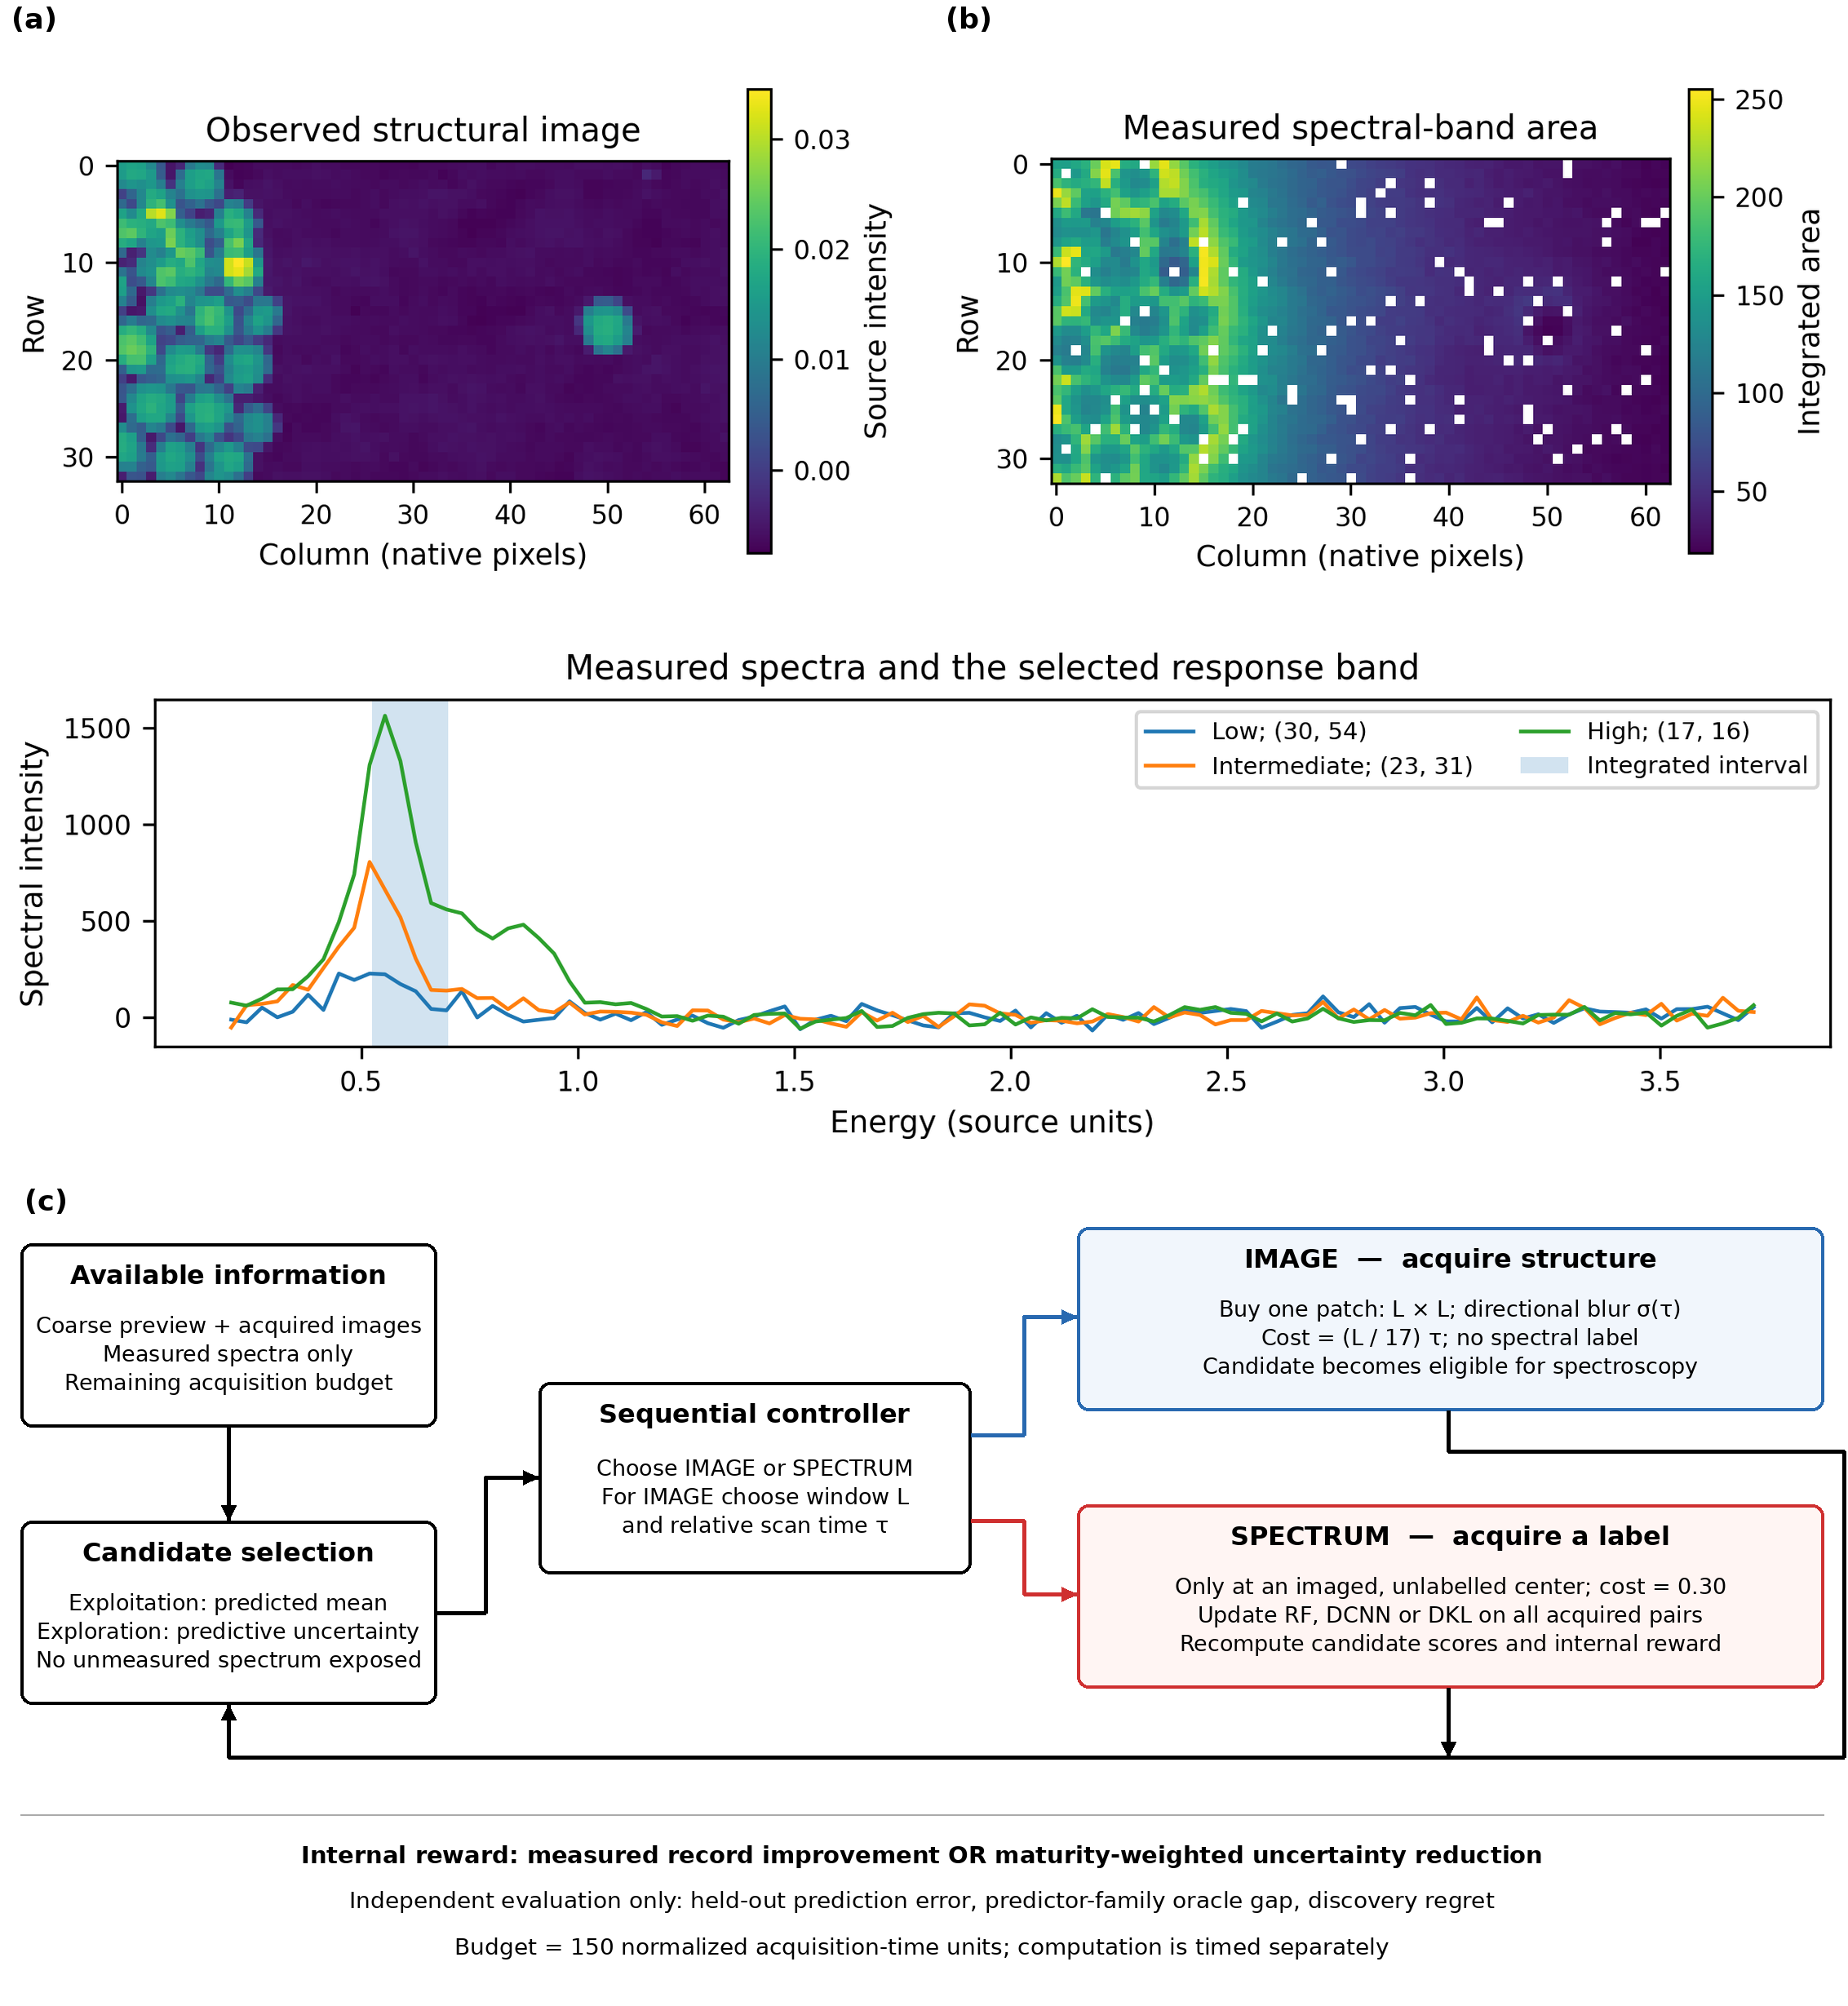

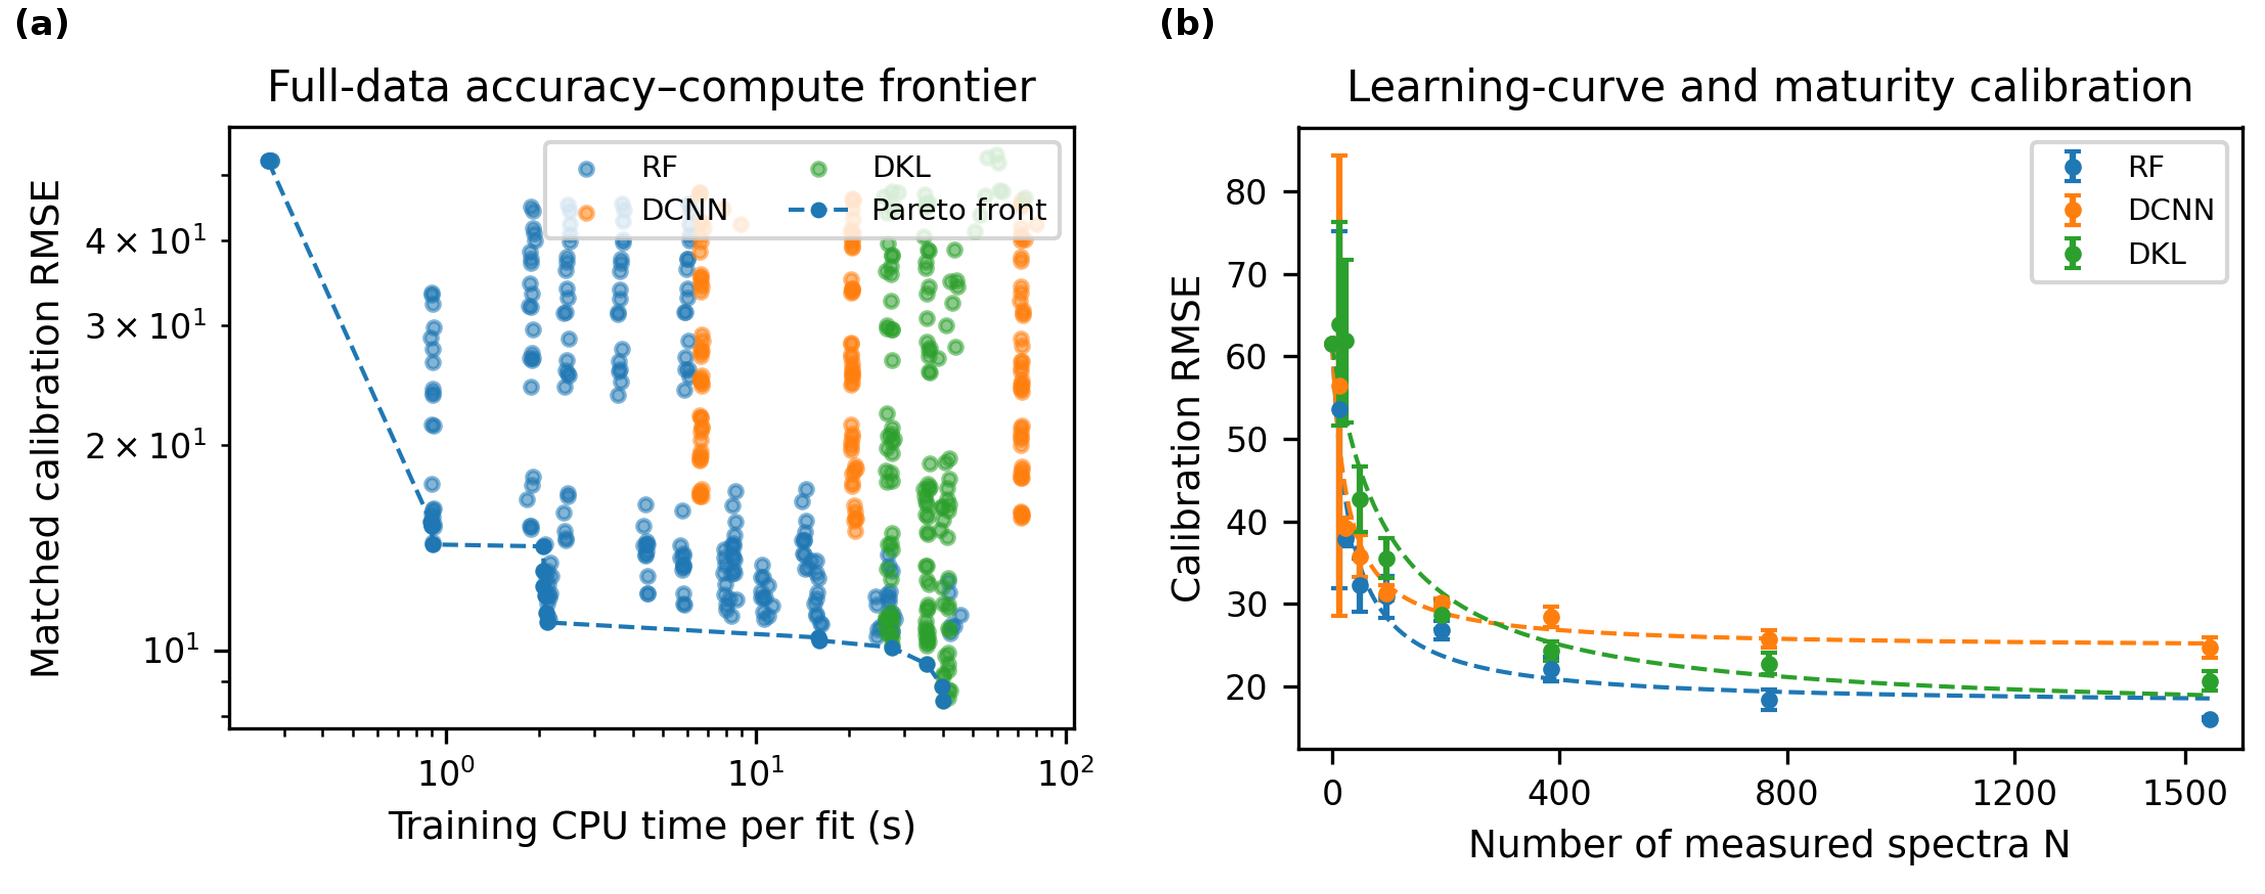

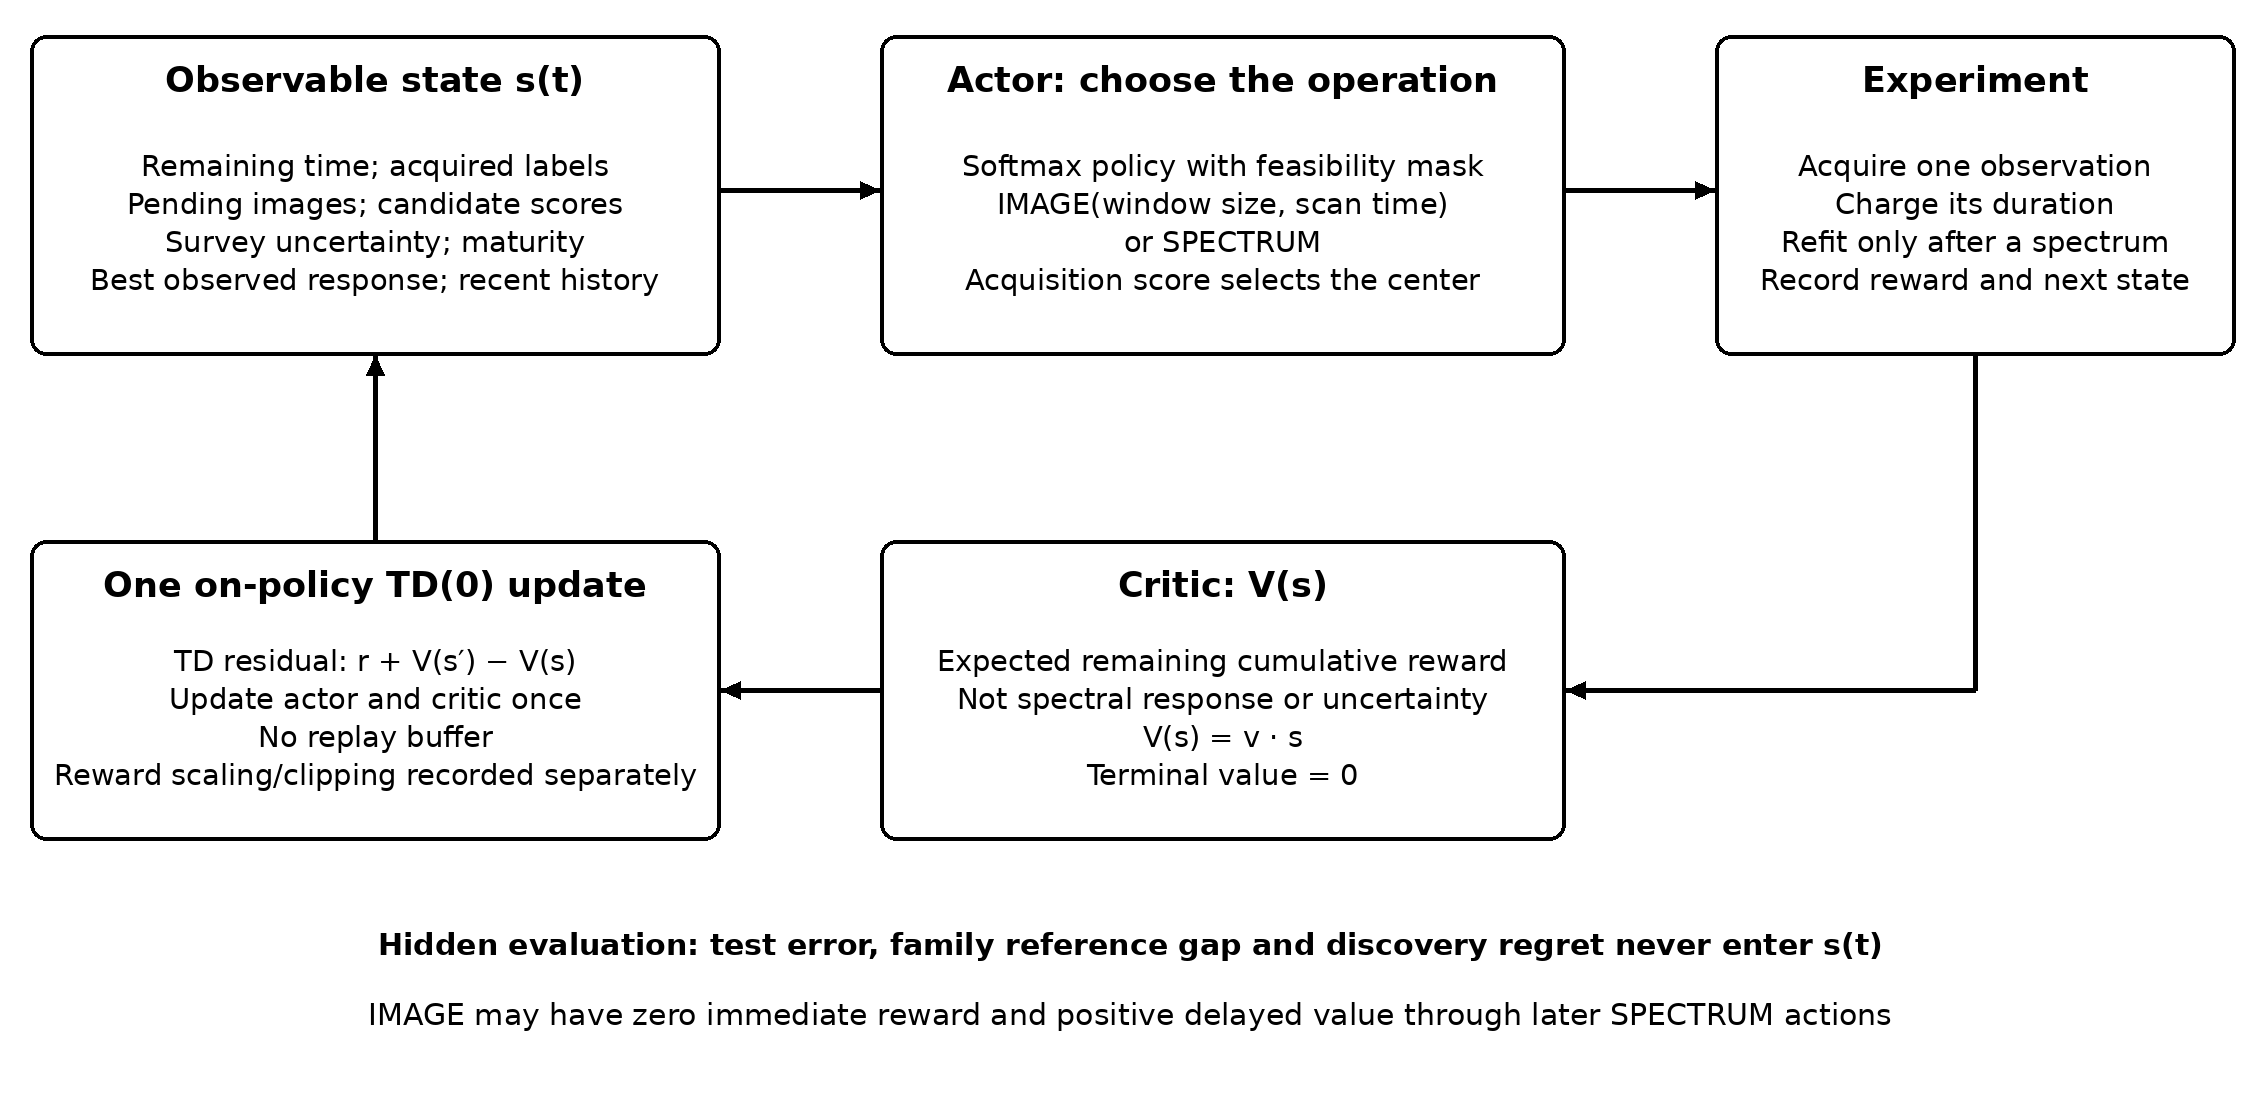

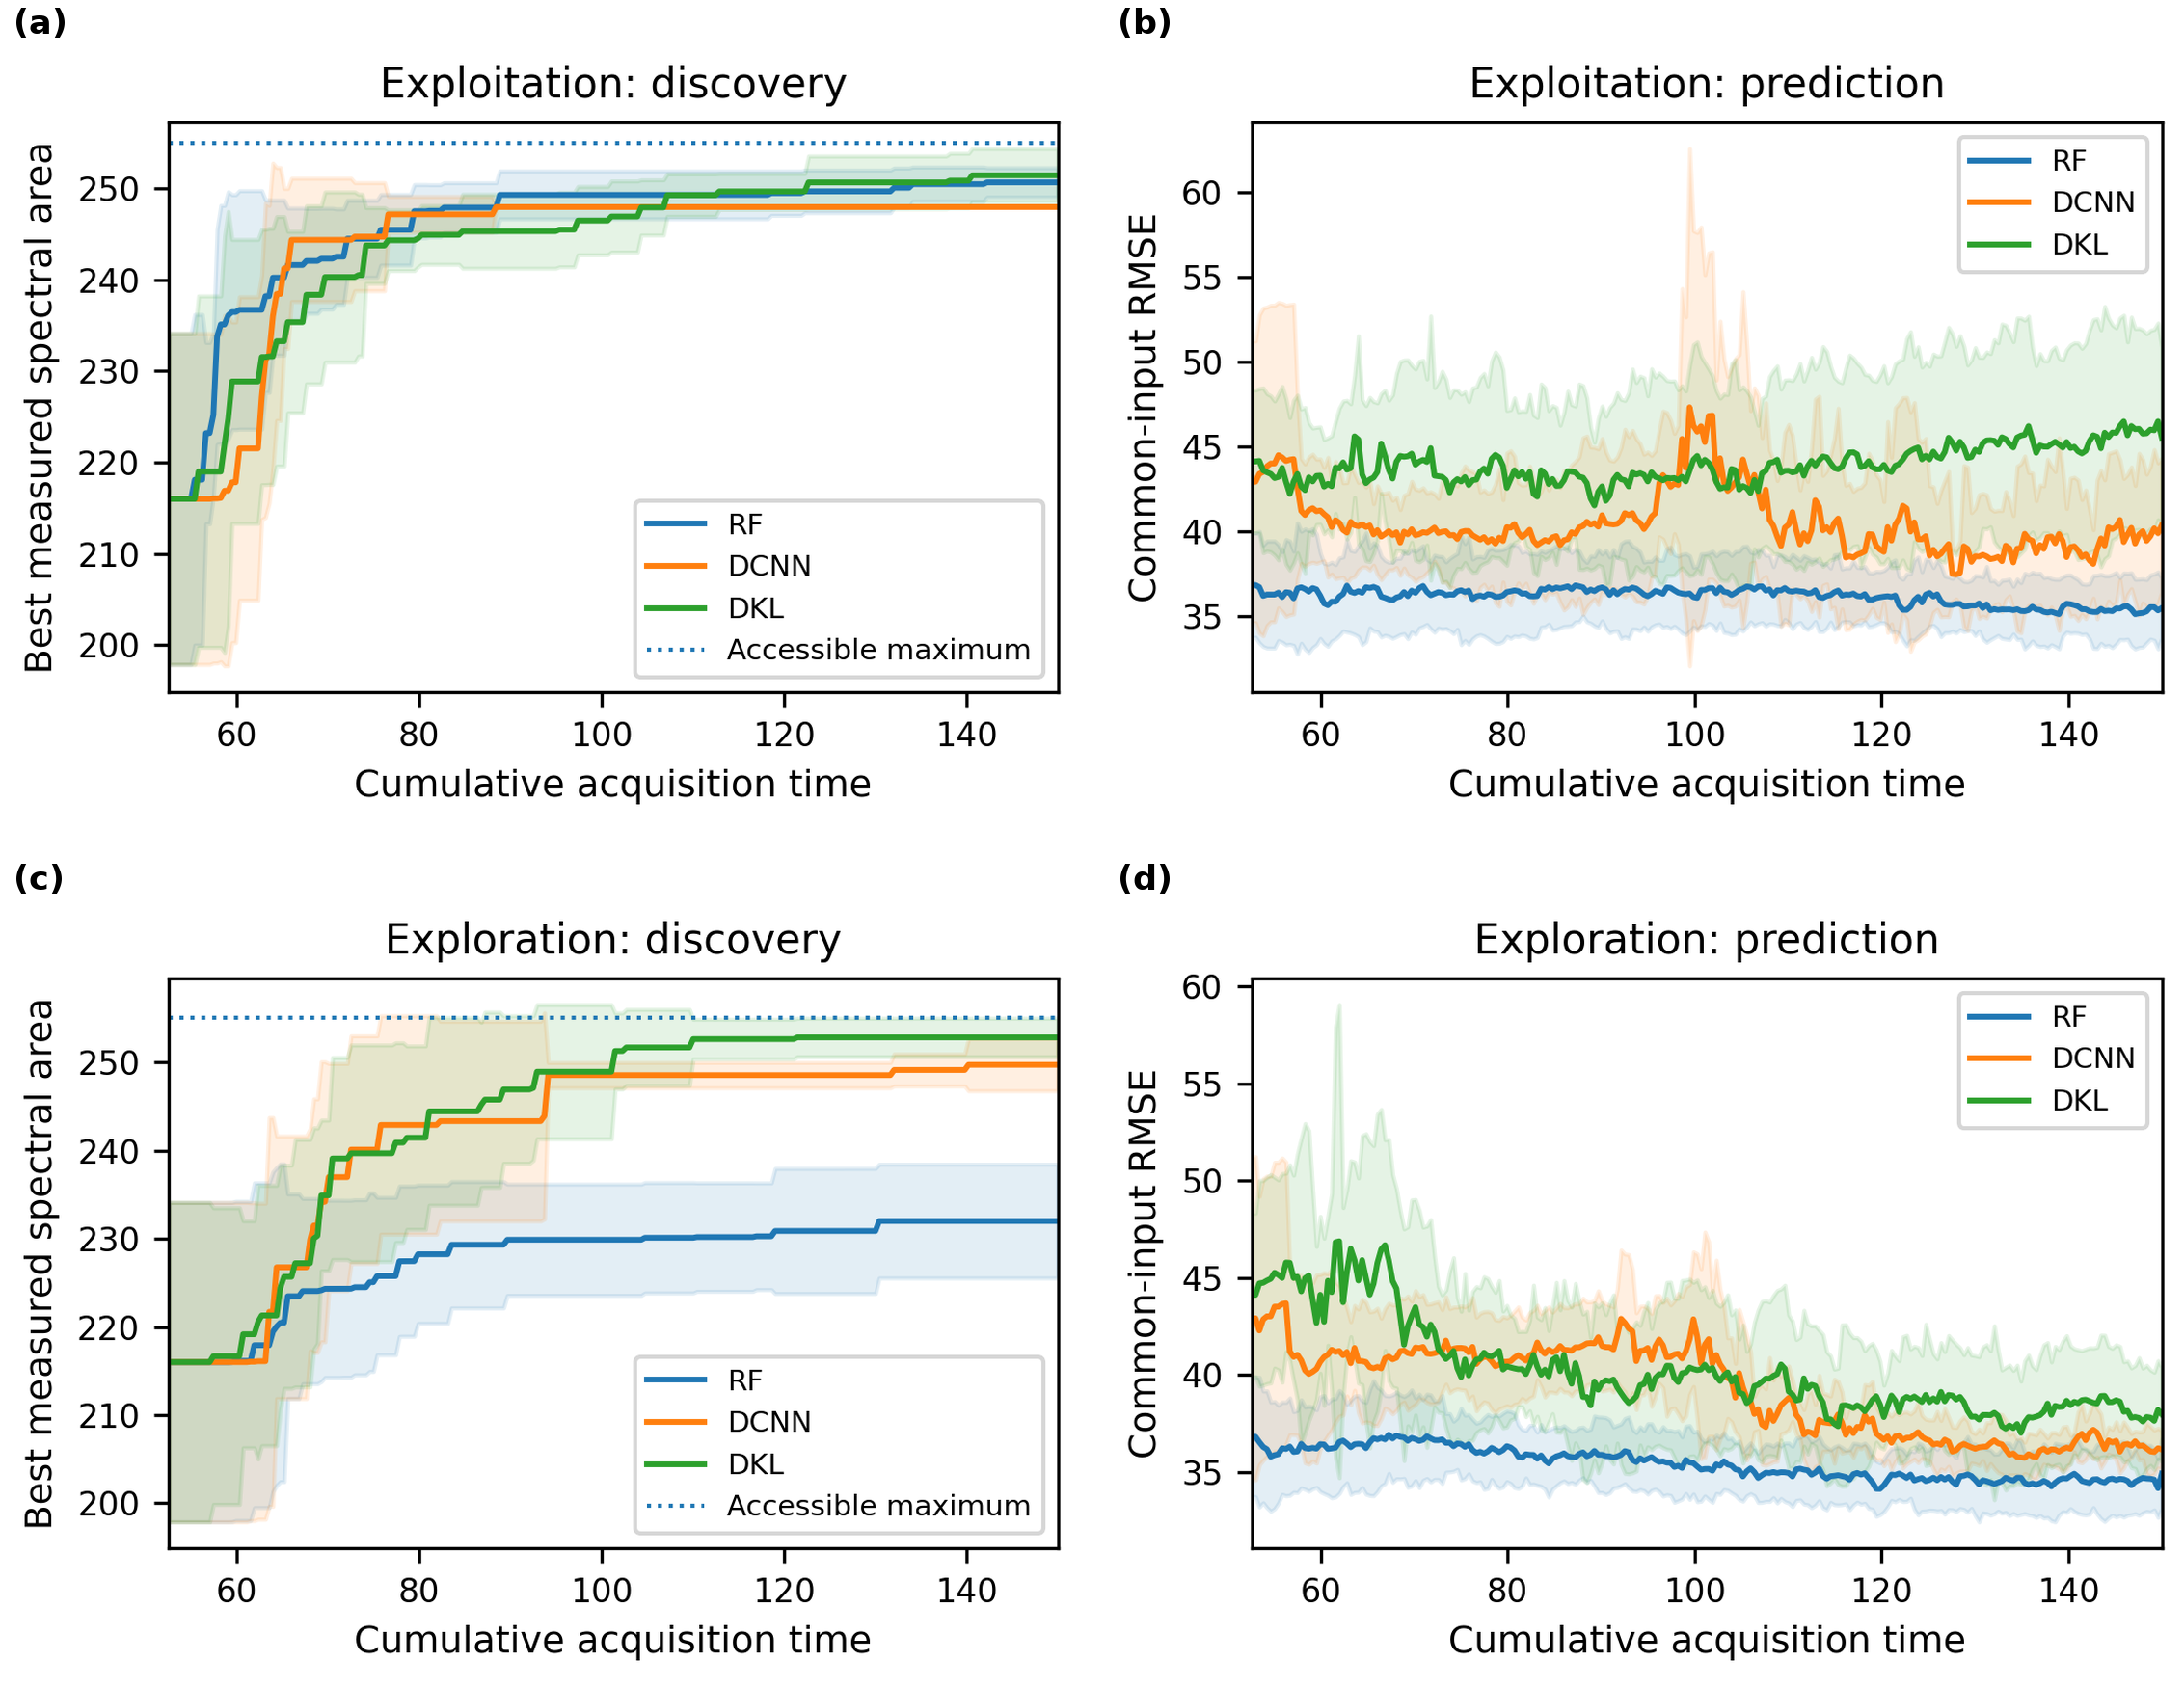

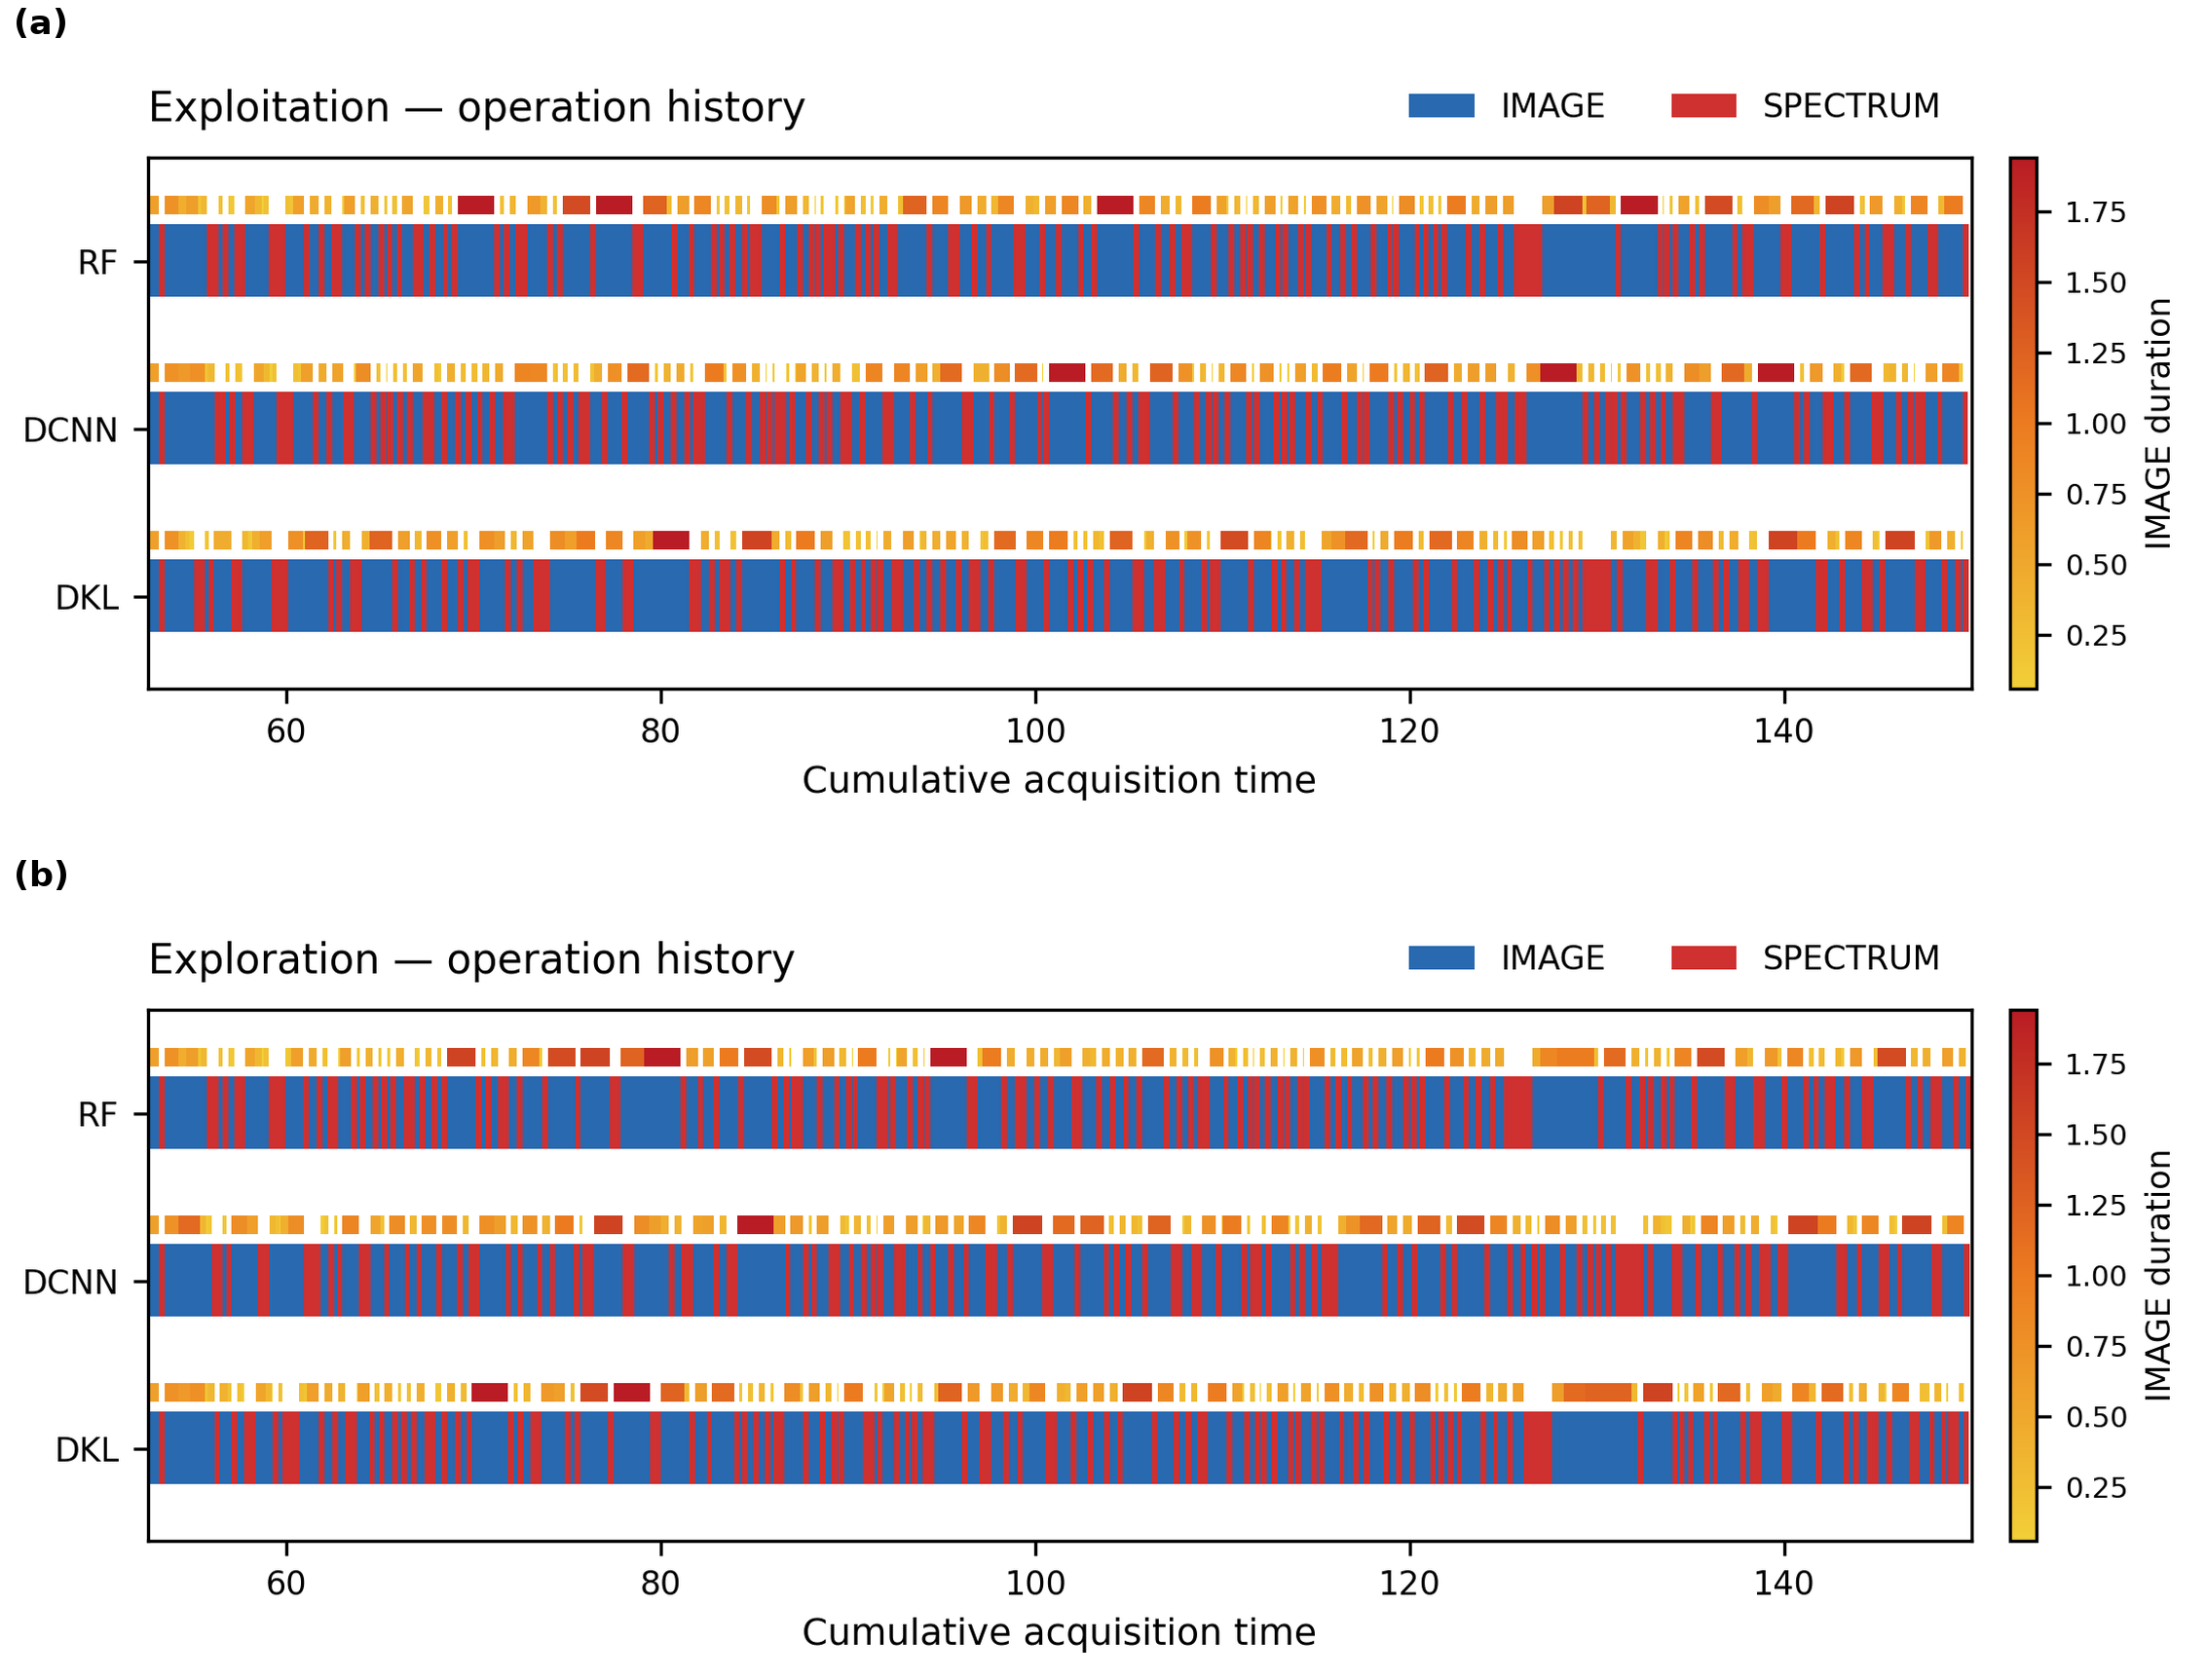

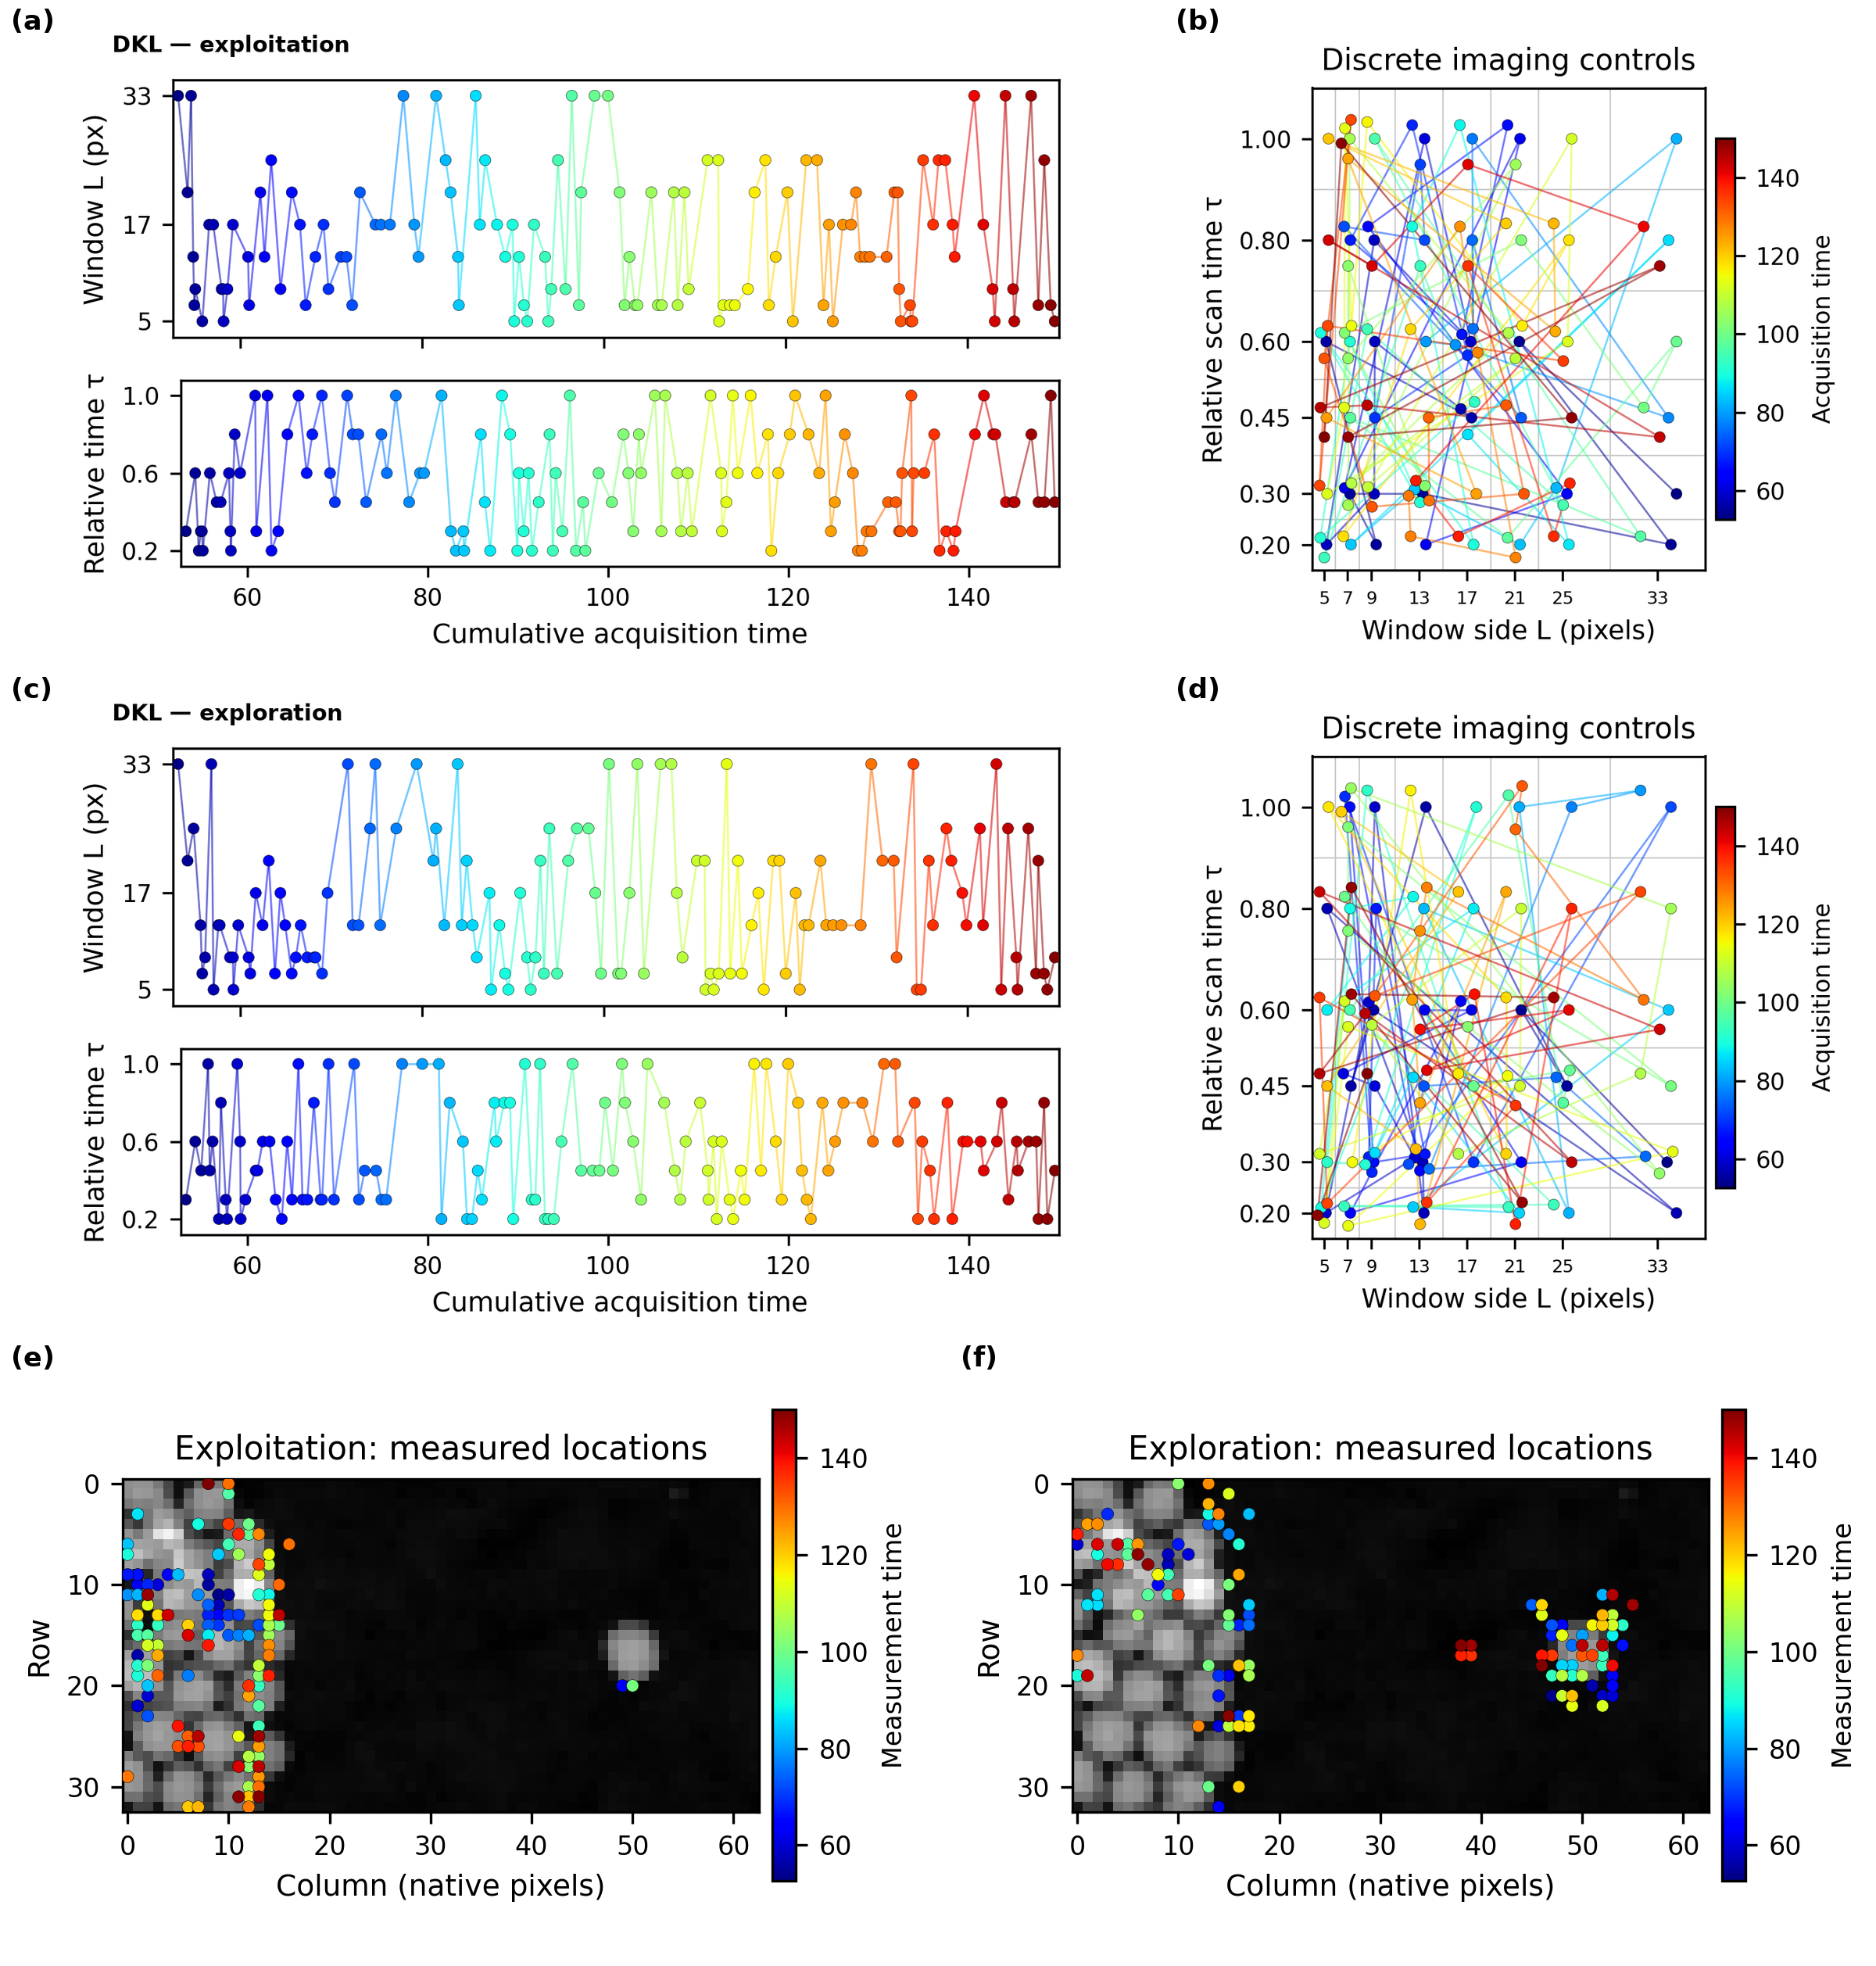

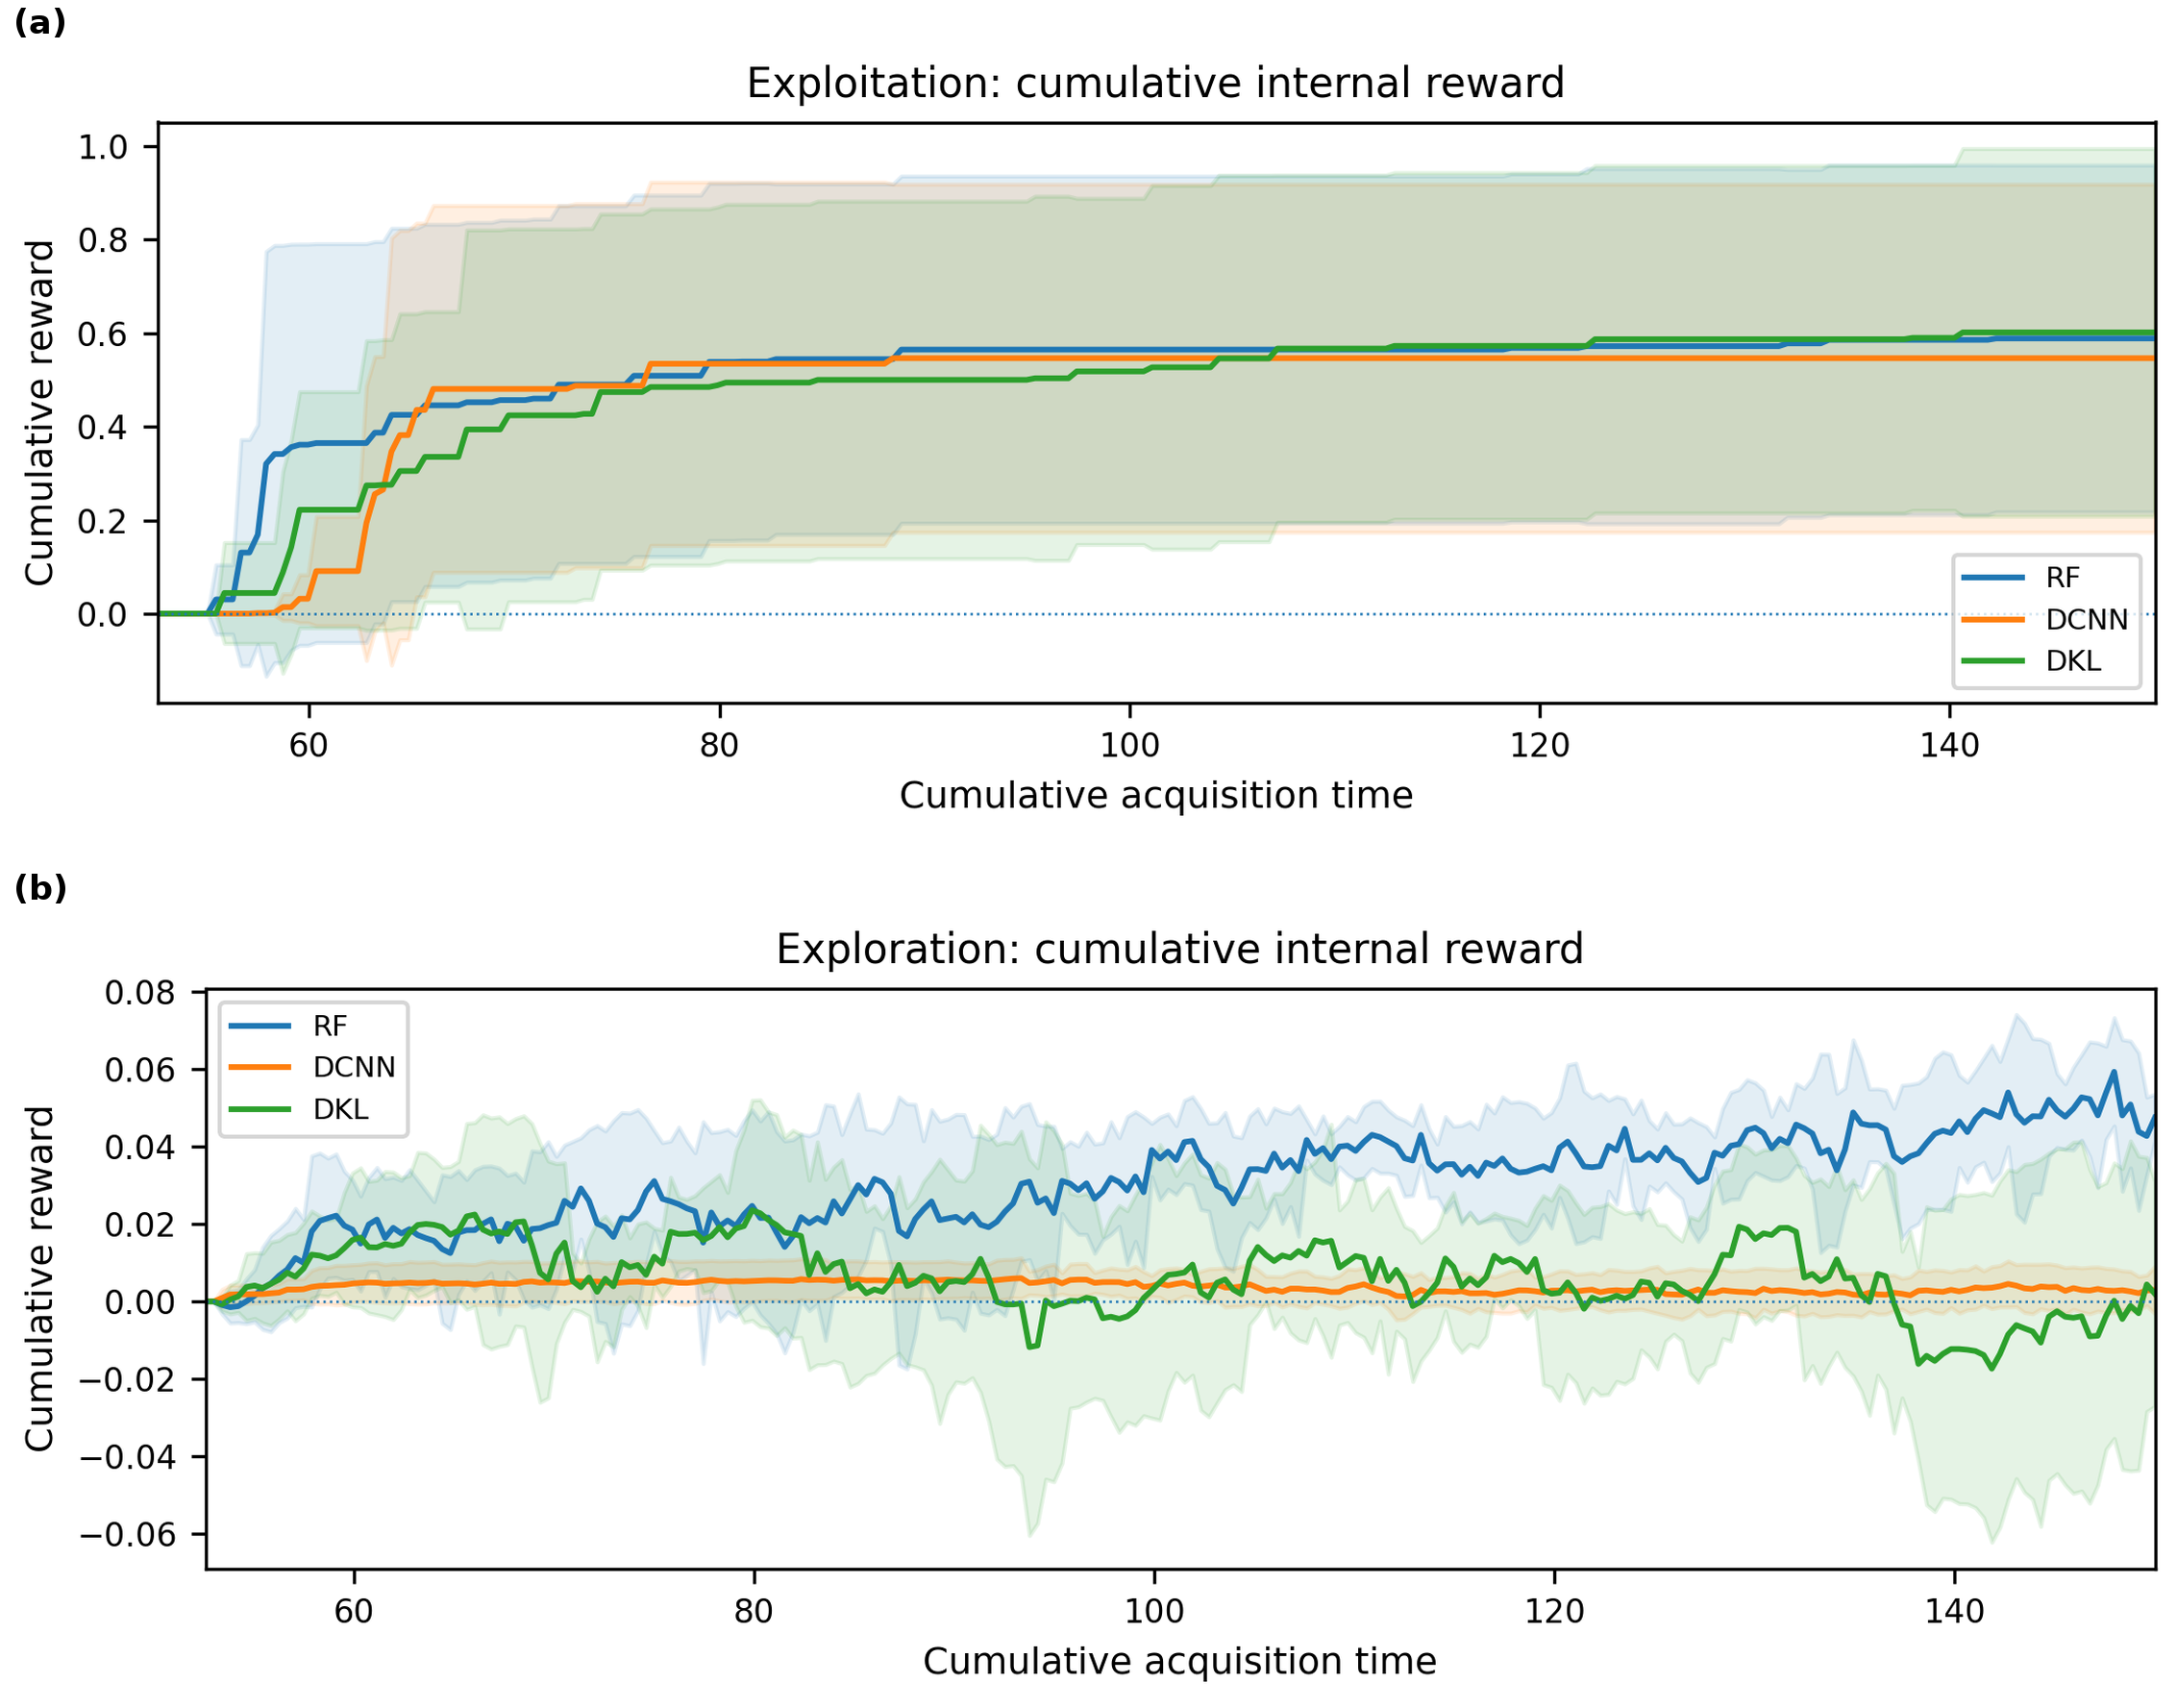

In [ ]:
if MODE == "paper":
    import paper_figures, paper_tables
    PAPER = OUTPUT / "manuscript"
    figures = paper_figures.make(MAIN, CONSTANT, PAPER)
    tables = paper_tables.make(MAIN, CONSTANT, PAPER)
    print(f"Generated {len(figures)} manuscript/supplementary figures and {len(tables)} tables.")
    for number in range(1,8):
        display(Image(filename=str(PAPER / "figures" / f"Figure_{number}.png"), width=850))
else:
    print("Check mode completed. No new full-grid or policy-campaign results are claimed.")

In [ ]:
if MODE == "paper":
    archive = export(OUTPUT, OUTPUT.parent / f"{OUTPUT.name}_results.zip", include_models=True)
    display(FileLink(str(archive)))
else:
    display(pd.read_csv(MAIN / "results" / "transition_checks.csv"))

/content/eels_paper_run_results.zip

### Reproduction scope
The dataset hashes, seeds, observation laws, models and controller are fixed by the manuscript protocol. Timings are hardware-dependent, and neural fits can differ numerically across environments. The saved measurements are not replaced with values quoted in the paper. The scalar sequential task is reproduced here; earlier exploratory full-spectrum prediction notebooks are not recast as additional manuscript experiments.

The compact NPZ is supplied separately. A durable public NPZ hosting address remains to be assigned; `DATA_URL` is deliberately not populated with an invented or temporary link.